# Script to compute summer metrics from CMIP6 model data over historical period + 2015-2024 using SSP2-4.5

Used the Copernicus CMIP6 CDS for GFDL and CESM data, also for CanESM5 SSP3-7.0 data
- at https://cds.climate.copernicus.eu/datasets/projections-cmip6?tab=download

Used the ESGF site for CanESM5 SSP2-4.5
- Helpful tutorial for ESGF https://climate-datalab.org/cmip6-walkthrough/
- https://metagrid.esgf-west.org/search
- Query String: latest = true AND (experiment_id = ssp245) AND (source_id = CanESM5) AND (variant_label = r1i1p1f1) AND (grid_label = gn) AND (realm = atmos) AND (nominal_resolution = 500 km) AND (variable_id = tas) AND (frequency = day)

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft

from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt
import matplotlib.ticker as mticker

import warnings
warnings.filterwarnings('ignore')

###################
# helper functions
###################
def SummerStatsFourier(temp_data, temp_data_next, threshold, save_plot, calc_tmax, calc_heat):
    '''

    Function that uses the input 75th percentile temperature in K to identify the summer from a time series of temperatures.
    Input data should already be set to 365 days.

    Args:
        temp_data: xarray of temperature data for a single grid cell for the year of interest
        temp_data_next: xarray of temperature data for a single grid cell for the following year (for SH summers)
        threshold: xarray for the 75th percentile threshold to use
        save_plot: save out a png of the time series with threshold, day of max, summer start/end shown
        calc_tmax: should the day of max temp during summer be calculated (slows processing)
        calc_heat: should the accumulated heat during summer be calculated (slows processing), includes mean temp and mean HS temp
        
    Returns:
        start day: DOY that daily mean t2m (from smoothed Fourier fit) first crossed above threshold (75th percentile)
        end day: DOY that daily mean t2m (from smoothed Fourier fit) first crossed below threshold (75th percentile) 
        day with max temp: during the summer period, the day that had the highest mean daily t2m 
        accumulated heat in summer: sum of degree days above threshold during summer, 0 if none
        summer length: number of days the smoothed fit to the t2m data is above threshold, 0 if none
        rmse: root mean squared error of Fourier fit to temperature time series
        **** r2: R-squared value for Fourier fit [IS THIS POSSIBLE???]
        mean temp: the mean temperature in K for the summer period, 0 if there was no time above threshold
        mean HS temp: the mean temperature in K for the days above threshold during summer (positive days)
        
    Example:
        start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStats(temps, temps_next, thresh, True, True, False)

    '''

    # default values
    first_day = 0 
    last_day = 0
    tmax_day = 0 
    summer_heat = 0 
    summer_length = 0
    rmse = 0.0
    r_squared = 0.0 # keeping for backward compat with the poly fit outputs
    mean_t = 0
    mean_hs = 0

    # split method based on NH or SH

    ######
    # Northern Hemisphere (uses current year only)
    if temp_data.lat.values >= 0:
        # extract DOY and T2m values for those days
        x1 = temp_data.time.dt.dayofyear.values
        y1 = temp_data.values

        # Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
        ymean = np.mean(y1)
        y_norm = y1 - ymean
        # perform DFT of temp data
        coef = fft(y_norm)
        # low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
        # help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
        Z_lp = np.copy(coef)
        Z_lp[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
        # apply inverse fourier transform to convert back to time domain (just want the real part)
        y_norm_lp = np.real(np.fft.ifft(Z_lp))

        # add back in the original mean temp
        y_lp = y_norm_lp + ymean

        # RMSE for Fourier fit
        rmse = np.sqrt(np.sum((y1-y_lp)**2)/365.0)
    
        # create some x values for plotting  fit
        x_values = np.linspace(min(x1), max(x1), 365) 
    
        # use fit to get stats
        summer_length = np.count_nonzero(y_lp >= threshold.values)
        summer_days = np.where(y_lp >= threshold.values)[0]

        # deal with those that didn't have any days above threshold
        if summer_length == 0:
            first_day = 0
            last_day = 0
            if calc_tmax:
                # day with max temp isn't above threshold but still want the value so can be any day of the year
                tmax_day = int(temp_data.argmax() + 1)
            if calc_heat:
                # determine accumulated heat over summer as sum of degree days above threshold
                # in this case there are none
                summer_heat = 0
        else:
            # otherwise can get start/end days 
            first_day = int(x_values[min(summer_days)])
            #OLD:# last_day = int(x_values[max(summer_days)])

            # end day comes after first day so find next crossing of  fit
            # this is to be careful to not count until the end of a double crossing
            end_window = np.where((y_lp[first_day:365]) < threshold.values)

            # if it does cross back below threshold before the end of the "year"
            if np.count_nonzero(end_window):
                last_day = end_window[0][0] + first_day

            # otherwise it never crosses back below threshold for the "year"
            # so the last day is day 365
            else:
                last_day = 365
           
            # summer length is the span between first and last + 1 to include the end day
            summer_length = last_day - first_day + 1    
            
            if calc_tmax:
                # day with max temp that is in summer period
                if first_day == last_day: #only one day of summer
                    tmax_day = first_day
                else:
                    # if summer_length is 0 then we already grab the day of max temp in the year
                    # but the day of max can also be the last day of the year so have to special case
                    if (temp_data[(first_day):(last_day+1)]).size == 0:
                        tmax_day = last_day
                    else:         
                        tmax_day = int((temp_data[(first_day):(last_day+1)].argmax() + 1) + first_day)        
            if calc_heat:
                # determine accumulated heat over summer as sum of degree days above threshold
                # also save mean temp
                nh_summ = temp_data[(first_day):(last_day+1)]

                # total area relative to zero for regions above threshold line
                above_thresh = float(nh_summ.where(nh_summ.values >= threshold.values).sum())
                days_above_thresh = nh_summ.where(nh_summ.values >= threshold.values).count()
                
                # area below threshold line to be subtracted
                thresh_heat = float(nh_summ.where(nh_summ.values >= threshold.values).count()) * threshold.values
                
                # calculate difference to get only the area between threshold and data
                summer_heat = above_thresh - thresh_heat

                # if there is a summer we can get the mean temp for the whole summer and the mean HS temp
                if len(nh_summ) > 0:
                    mean_t = nh_summ.values.mean()
                    mean_hs = float(above_thresh/days_above_thresh) - threshold.values

                
    
    ######
    # Southern Hemisphere (uses current year and following year)
    else: 
        # concat both years
        ds_two = xr.concat([temp_data, temp_data_next], dim="time")

        # get the current year for slicing
        input_year = temp_data.time.dt.year.values[0]

        # select July 1 - June 30 across the two years to do fit
        startdate = str(input_year)+'-07-01' # 182nd day of a normal year
        enddate = str(input_year+1)+'-06-30'
        sh_yr = ds_two.sel(time=slice(startdate,enddate))
        
        # DOY (relative to July 1) and T2m values for those days
        x1 = np.arange(1,len(sh_yr.time)+1) 
        y1 = sh_yr.values
        
        # Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
        ymean = np.mean(y1)
        y_norm = y1 - ymean
        # perform DFT of temp data
        coef = fft(y_norm)
        # low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
        # help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
        Z_lp = np.copy(coef)
        Z_lp[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
        # apply inverse fourier transform to convert back to time domain (just want the real part)
        y_norm_lp = np.real(np.fft.ifft(Z_lp))

        # add back in the original mean temp
        y_lp = y_norm_lp + ymean

        # RMSE for Fourier fit
        rmse = np.sqrt(np.sum((y1-y_lp)**2)/365.0)
        
        # create some x values for plotting  fit
        x_values = np.linspace(min(x1), max(x1), 365) 
        summer_length = np.count_nonzero(y_lp >= threshold.values)
        summer_days = np.where(y_lp >= threshold.values)[0]

        # check if summer length is 0
        if summer_length == 0:
            first_day = 0
            last_day = 0
            if calc_tmax:
                # day with max temp isn't above threshold but still want the value so can be any day of the year
                tmax_day = int(sh_yr.argmax() + 1)
            if calc_heat:
                # determine accumulated heat over summer as sum of degree days above threshold
                # in this case there are none
                summer_heat = 0
        else:
            # otherwise can get start/end days but note these are relative to July 1
            first_day = int(x_values[min(summer_days)])
            #OLD:# last_day = int(x_values[max(summer_days)])

            # end day comes after first day so find next crossing of  fit
            # this is to be careful to not count until the end of a double crossing
            end_window = np.where((y_lp[first_day:365]) < threshold.values)

            # if it does cross back below threshold before the end of the "year"
            if np.count_nonzero(end_window):
                last_day = end_window[0][0] + first_day

            # otherwise it never crosses back below threshold for the "year"
            # so the last day is day 365
            else:
                last_day = 365
           
            # summer length is the span between first and last + 1 to include the end day
            summer_length = last_day - first_day + 1           
    
            
            if calc_tmax:
                # day with max temp that is in summer period
                if first_day == last_day: #only one day of summer
                    tmax_day = first_day
                else:
                    # if summer_length is 0 then we already grab the day of max temp in the year
                    # but the day of max can also be the last day of the year so have to special case
                    if (sh_yr[(first_day):(last_day+1)]).size == 0:
                        tmax_day = last_day
                    else:         
                        tmax_day = int((sh_yr[(first_day):(last_day+1)].argmax() + 1) + first_day)  
            if calc_heat:
                # determine accumulated heat over summer as sum of degree days above threshold
                # also save the mean temp of summer
                sh_summ = sh_yr[(first_day):(last_day+1)]

                # total area relative to zero for regions above threshold line
                above_thresh = float(sh_summ.where(sh_summ.values >= threshold.values).sum())
                days_above_thresh = sh_summ.where(sh_summ.values >= threshold.values).count()
                
                # area below threshold line to be subtracted
                thresh_heat = float(sh_summ.where(sh_summ.values >= threshold.values).count()) * threshold.values
                
                # calculate difference to get only the area between threshold and data
                summer_heat = above_thresh - thresh_heat

                # if there is a summer we can get the mean temp for the whole summer and the mean HS temp
                if len(sh_summ) > 0:
                    mean_t = sh_summ.values.mean()
                    mean_hs = float(above_thresh/days_above_thresh) - threshold.values
                
                

                
    # make and save plot if desired
    ##
    ##
    if save_plot:
        cell_lat = temp_data.lat.values
        cell_lon = temp_data.lon.values
        yr = temp_data.time.dt.year.values[0]

        plt.figure(figsize=(16,6))
        plt.plot(x1,y1, label='daily mean T2m')
        plt.plot(x_values, y_lp, label='Fourier fit 1-4th Harmonic', color='red')
        plt.axhline(threshold.values, color="black", linewidth=0.8, linestyle="dashed") 
        plt.axvline(first_day, color="black", linewidth=0.8, linestyle="dashed")
        plt.axvline(last_day, color="black", linewidth=0.8, linestyle="dashed")
        plt.annotate('start', xy=(first_day-5,np.max(y_lp)+2), fontsize=12)
        plt.annotate('end', xy=(last_day-5,np.max(y_lp)+2), fontsize=12)
        plt.annotate('summer = '+str(summer_length)+' days', xy=(first_day+5,np.mean(y_lp)), fontsize=18)
        plt.annotate('75th percentile = '+str(np.round(threshold.values,1))+'K', xy=(0,threshold.values+1), fontsize=18)
        plt.annotate('RMSE = '+str(np.round(rmse,2)), xy=(0, np.min(y1)), fontsize=18)
        plt.annotate('Mean = '+str(np.round(mean_t,2))+'K', xy=(last_day-5, mean_t-1), fontsize=12)

        if calc_tmax:
            # add annotation for tmax_day
            plt.annotate('Tmax day '+str(tmax_day), xy=(tmax_day,np.max(y1)), fontsize=12)

        if cell_lat < 0:
            # SH days are relative to July 1
            plt.xlabel('DOY (' + str(yr) + ') relative to July 1')
        else:
            plt.xlabel('DOY (' + str(yr) + ')')
        plt.ylabel('Mean Daily Temp (K)')
        plt.title(str(yr) + " Summer for Lat,Lon = [" +str(cell_lat)+","+str(cell_lon)+ "] Baseline Years = (1961-1990)")
        plt.legend()
        plt.savefig("fourierfit_stats_"+str(cell_lat)+"_"+str(cell_lon)+"_"+str(yr)+".png")
        plt.show()
    
    # return
    return int(first_day), int(last_day), int(tmax_day), float(summer_heat), int(summer_length), float(rmse), float(r_squared), float(mean_t), float(mean_hs)



## GFDL-ESM4

#### Load baseline 75% percentile values from GFDL-ESM4 historical data per grid cell
- prior use of ERA5 baseline showed bias especially for CanESM data

In [39]:
# get baseline
file_path = '../../../Data/CMIP6/GFDL-ESM4/FixedCoords/baseline/computed_1961-1990-full_75th.nc'
c_75_gfdl = xr.open_dataarray(file_path)
c_75_gfdl.values


array([[232.26114655, 232.26734543, 232.284729  , ..., 232.22362518,
        232.23983383, 232.25183105],
       [233.77070999, 233.82932663, 233.89312363, ..., 233.58325577,
        233.6568985 , 233.71512985],
       [236.58597183, 236.75053787, 236.90254593, ..., 236.13204575,
        236.28129196, 236.44504166],
       ...,
       [270.2830658 , 270.28128815, 270.28505707, ..., 270.28268433,
        270.27661133, 270.28279877],
       [270.32775879, 270.31763458, 270.31313324, ..., 270.30745697,
        270.31652832, 270.32610321],
       [270.33882904, 270.33126831, 270.32994843, ..., 270.33628082,
        270.33679962, 270.34015656]], shape=(180, 288))

### Load GFDL-ESM4 data and fix coordinate issues
#### *** this is now complete ***

In [51]:
# all data so far
#file_path = '../../../Data/CMIP6/GFDL-ESM4/*.nc'
# file_path = '../../../Data/CMIP6/GFDL-ESM4/tas_day_GFDL-ESM4_ssp245_r1i1p1f1_gr1_20150101-20241231.nc'

# ds_gfdl = xr.open_mfdataset(file_path)

#### update time variable

In [52]:
# ds_gfdl['time'] = ds_gfdl.indexes['time'].to_datetimeindex()

/var/folders/ml/p381h5fs0x9g7g5ksj8fh6qh0000gn/T/ipykernel_73769/1565888960.py:1: FutureWarning: In a future version of xarray to_datetimeindex will default to returning a 'us'-resolution DatetimeIndex instead of a 'ns'-resolution DatetimeIndex. This warning can be silenced by explicitly passing the `time_unit` keyword argument.
  ds_gfdl['time'] = ds_gfdl.indexes['time'].to_datetimeindex()
/var/folders/ml/p381h5fs0x9g7g5ksj8fh6qh0000gn/T/ipykernel_73769/1565888960.py:1: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'noleap', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  ds_gfdl['time'] = ds_gfdl.indexes['time'].to_datetimeindex()


In [21]:
# def missing_elements(L):
#     start, end = L[0], L[-1]
#     return sorted(set(range(start, end + 1)).difference(L))

# L = ds_gfdl.sel(time='2000').time.dt.dayofyear.values
# missing_elements(L)

[60]

#### Looks like Feb 29 has been removed

#### Adjust Lon to run from -180 to 180 instead of 0 to 360

In [53]:
# adjust longitude to run from -180 to 180
# solution from: https://stackoverflow.com/questions/53345442/about-changing-longitude-array-from-0-360-to-180-to-180-with-python-xarray
# save attributes so I can add them back later
# lon_atrib = ds_gfdl.coords['lon'].attrs  
# lat_atrib = ds_gfdl.coords['lat'].attrs
# ds_gfdl.coords['lon'] = (ds_gfdl.coords['lon'] + 180) % 360 - 180
# ds_fixed = ds_gfdl.sortby(ds_gfdl.lon)
# ds_fixed

<xarray.Dataset> Size: 757MB
Dimensions:    (lat: 180, bnds: 2, lon: 288, time: 3650)
Coordinates:
  * lat        (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * bnds       (bnds) float64 16B 1.0 2.0
  * lon        (lon) float64 2kB -179.4 -178.1 -176.9 ... 176.9 178.1 179.4
  * time       (time) datetime64[ns] 29kB 2015-01-01T12:00:00 ... 2024-12-31T...
    height     float64 8B ...
Data variables:
    lat_bnds   (lat, bnds) float64 3kB dask.array<chunksize=(180, 2), meta=np.ndarray>
    lon_bnds   (lon, bnds) float64 5kB dask.array<chunksize=(288, 2), meta=np.ndarray>
    tas        (time, lat, lon) float32 757MB dask.array<chunksize=(1, 180, 288), meta=np.ndarray>
    time_bnds  (time, bnds) object 58kB dask.array<chunksize=(1, 2), meta=np.ndarray>
Attributes: (12/46)
    external_variables:     areacella
    history:                File was processed by fremetar (GFDL analog of CM...
    table_id:               day
    activity_id:            ScenarioMIP
    branch_method:          standard
    branch_time_in_child:   60225.0
    ...                     ...
    title:                  NOAA GFDL GFDL-ESM4 model output prepared for CMI...
    tracking_id:            hdl:21.14100/a94e308e-7b1b-4a67-a21a-aa57eb88f207
    variable_id:            tas
    variant_info:           N/A
    references:             see further_info_url attribute
    variant_label:          r1i1p1f1

#### Save out data with fixed time and longitude coords

In [54]:
# file_path = '../../../Data/CMIP6/GFDL-ESM4/FixedCoords/tas_day_GFDL-ESM4_ssp245_r1i1p1f1_gr1_20150101-20241231.nc'

# ds_fixed.to_netcdf(file_path)

## Now re-load fixed GFDL-ESM4 data

In [40]:
file_path = '../../../Data/CMIP6/GFDL-ESM4/FixedCoords/*.nc'
#file_path = '../../../Data/CMIP6/GFDL-ESM4/tas_day_GFDL-ESM4_ssp245_r1i1p1f1_gr1_20150101-20241231.nc'

ds_gfdl = xr.open_mfdataset(file_path)

In [41]:
ds_gfdl

<xarray.Dataset> Size: 3GB
Dimensions:    (time: 12775, lat: 180, bnds: 2, lon: 288)
Coordinates:
  * time       (time) datetime64[ns] 102kB 1990-01-01T12:00:00 ... 2024-12-31...
  * lat        (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * bnds       (bnds) float64 16B 1.0 2.0
  * lon        (lon) float64 2kB -179.4 -178.1 -176.9 ... 176.9 178.1 179.4
    height     float64 8B 2.0
Data variables:
    lat_bnds   (time, lat, bnds) float64 37MB dask.array<chunksize=(1825, 180, 2), meta=np.ndarray>
    lon_bnds   (time, lon, bnds) float64 59MB dask.array<chunksize=(1825, 288, 2), meta=np.ndarray>
    tas        (time, lat, lon) float32 3GB dask.array<chunksize=(1, 180, 288), meta=np.ndarray>
    time_bnds  (time, bnds) object 204kB dask.array<chunksize=(1, 2), meta=np.ndarray>
Attributes: (12/46)
    external_variables:     areacella
    history:                File was processed by fremetar (GFDL analog of CM...
    table_id:               day
    activity_id:            CMIP
    branch_method:          standard
    branch_time_in_child:   0.0
    ...                     ...
    title:                  NOAA GFDL GFDL-ESM4 model output prepared for CMI...
    tracking_id:            hdl:21.14100/ef0a0372-2d5b-4290-89a9-83c849cfa64e
    variable_id:            tas
    variant_info:           N/A
    references:             see further_info_url attribute
    variant_label:          r1i1p1f1

### Test for Vancouver 2000 - nearest grid cell

In [42]:
#test for Vancouver
input_lat = 49.246
input_lon = -123.116

thresh = c_75_gfdl.sel(lat=input_lat, lon=input_lon, method="nearest")
thresh

<xarray.DataArray 'tas' ()> Size: 8B
array(284.264442)
Coordinates:
    lat       float64 8B 49.5
    lon       float64 8B -123.1
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [43]:
input_year = 2000

ds = ds_gfdl.sel(time = str(input_year))
curr = ds.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
dsnext = ds_gfdl.sel(time = str(input_year+1))
nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
curr, nxt

(<xarray.DataArray 'tas' (time: 365)> Size: 1kB
 dask.array<getitem, shape=(365,), dtype=float32, chunksize=(1,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 3kB 2000-01-01T12:00:00 ... 2000-12-31T12:...
     height   float64 8B 2.0
     lat      float64 8B 49.5
     lon      float64 8B -123.1
 Attributes:
     long_name:      Near-Surface Air Temperature
     units:          K
     cell_methods:   area: time: mean
     cell_measures:  area: areacella
     standard_name:  air_temperature
     interp_method:  conserve_order2
     original_name:  tas,
 <xarray.DataArray 'tas' (time: 365)> Size: 1kB
 dask.array<getitem, shape=(365,), dtype=float32, chunksize=(1,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 3kB 2001-01-01T12:00:00 ... 2001-12-31T12:...
     height   float64 8B 2.0
     lat      float64 8B 49.5
     lon      float64 8B -123.1
 Attributes:
     long_name:      Near-Surface Air Temperature
     units:          K
 

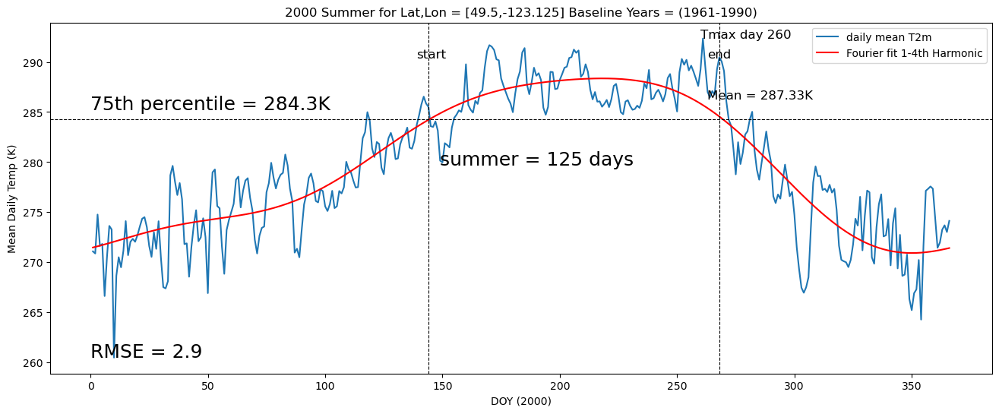

(144,
 268,
 260,
 402.8012390136719,
 125,
 2.896641969680786,
 0.0,
 287.33477783203125,
 3.4724244742557744)

In [44]:
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True)
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

#### Vancouver 2023 uses ssp2-4.5 data

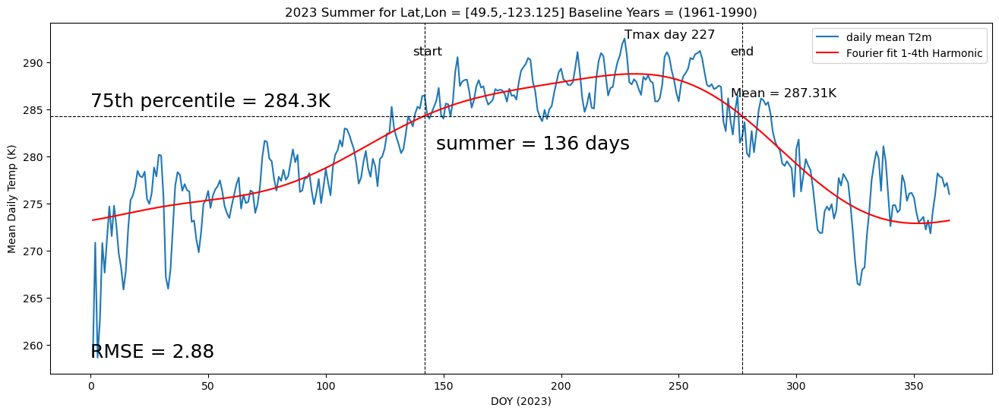

CPU times: user 1.02 s, sys: 146 ms, total: 1.16 s
Wall time: 965 ms


(142,
 277,
 227,
 425.8759231567383,
 136,
 2.8821969032287598,
 0.0,
 287.3099060058594,
 3.4624058793230574)

In [8]:
%%time
input_year = 2023

ds = ds_gfdl.sel(time = str(input_year))
curr = ds.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
dsnext = ds_gfdl.sel(time = str(input_year+1))
nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True)
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Try Sydney Australia to test SH functioning

In [9]:
input_lat = -33 - 52/60 - 4/3600
input_lon = 151.25
thresh = c_75_gfdl.sel(lat=input_lat, lon=input_lon, method="nearest")

curr = ds.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
curr, nxt

(<xarray.DataArray 'tas' (time: 365)> Size: 1kB
 dask.array<getitem, shape=(365,), dtype=float32, chunksize=(1,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 3kB 2023-01-01T12:00:00 ... 2023-12-31T12:...
     height   float64 8B 2.0
     lat      float64 8B -33.5
     lon      float64 8B 151.9
 Attributes:
     long_name:      Near-Surface Air Temperature
     units:          K
     cell_methods:   area: time: mean
     cell_measures:  area: areacella
     standard_name:  air_temperature
     interp_method:  conserve_order2
     original_name:  tas,
 <xarray.DataArray 'tas' (time: 365)> Size: 1kB
 dask.array<getitem, shape=(365,), dtype=float32, chunksize=(1,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 3kB 2024-01-01T12:00:00 ... 2024-12-31T12:...
     height   float64 8B 2.0
     lat      float64 8B -33.5
     lon      float64 8B 151.9
 Attributes:
     long_name:      Near-Surface Air Temperature
     units:          K
 

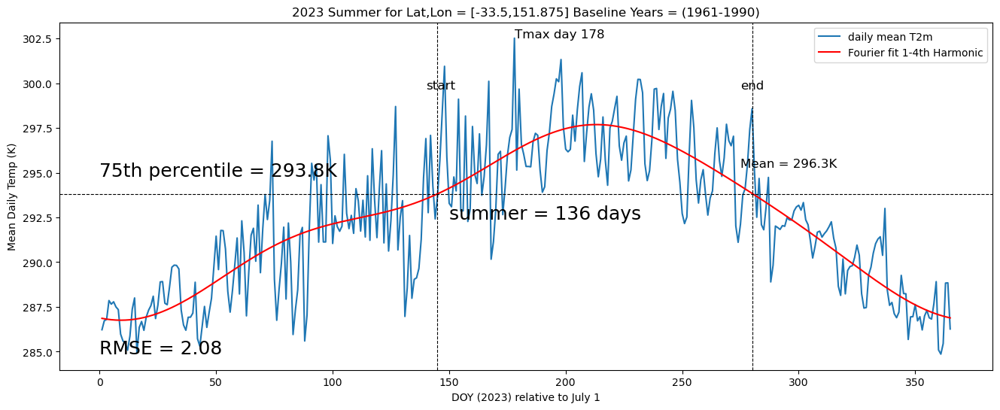

(145,
 280,
 178,
 364.6070098876953,
 136,
 2.0770905017852783,
 0.0,
 296.2985534667969,
 3.198307104278001)

In [10]:
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True)
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

## Main Loop: loop through multiple years to generate summer stats

In [45]:
# grid parameters for looping
num_lat = ds_gfdl.lat.shape[0]
num_lon = ds_gfdl.lon.shape[0]

loop_lats = ds_gfdl.lat.values[:num_lat]
loop_lons = ds_gfdl.lon.values[:num_lon]
loop_lats, loop_lons

(array([-89.5, -88.5, -87.5, -86.5, -85.5, -84.5, -83.5, -82.5, -81.5,
        -80.5, -79.5, -78.5, -77.5, -76.5, -75.5, -74.5, -73.5, -72.5,
        -71.5, -70.5, -69.5, -68.5, -67.5, -66.5, -65.5, -64.5, -63.5,
        -62.5, -61.5, -60.5, -59.5, -58.5, -57.5, -56.5, -55.5, -54.5,
        -53.5, -52.5, -51.5, -50.5, -49.5, -48.5, -47.5, -46.5, -45.5,
        -44.5, -43.5, -42.5, -41.5, -40.5, -39.5, -38.5, -37.5, -36.5,
        -35.5, -34.5, -33.5, -32.5, -31.5, -30.5, -29.5, -28.5, -27.5,
        -26.5, -25.5, -24.5, -23.5, -22.5, -21.5, -20.5, -19.5, -18.5,
        -17.5, -16.5, -15.5, -14.5, -13.5, -12.5, -11.5, -10.5,  -9.5,
         -8.5,  -7.5,  -6.5,  -5.5,  -4.5,  -3.5,  -2.5,  -1.5,  -0.5,
          0.5,   1.5,   2.5,   3.5,   4.5,   5.5,   6.5,   7.5,   8.5,
          9.5,  10.5,  11.5,  12.5,  13.5,  14.5,  15.5,  16.5,  17.5,
         18.5,  19.5,  20.5,  21.5,  22.5,  23.5,  24.5,  25.5,  26.5,
         27.5,  28.5,  29.5,  30.5,  31.5,  32.5,  33.5,  34.5,  35.5,
      

In [46]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1990, 2024,1)

process_yrs

array([1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000,
       2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011,
       2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022,
       2023])

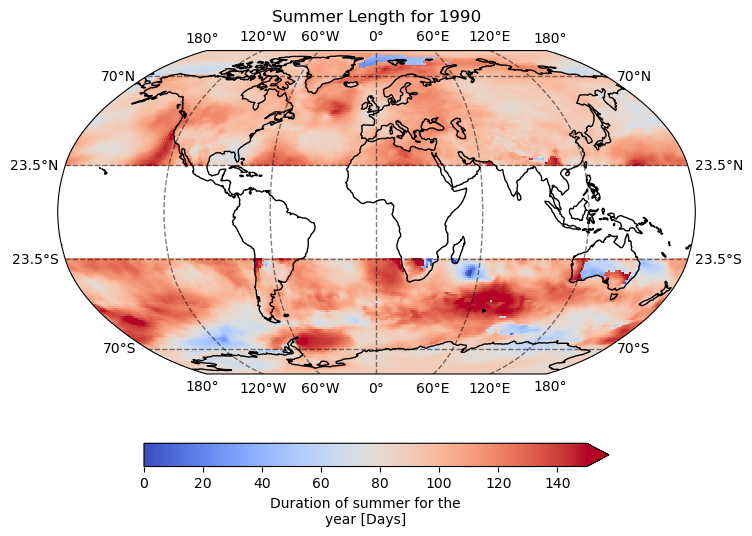

Time for 1990 :1.8897020500000001 min


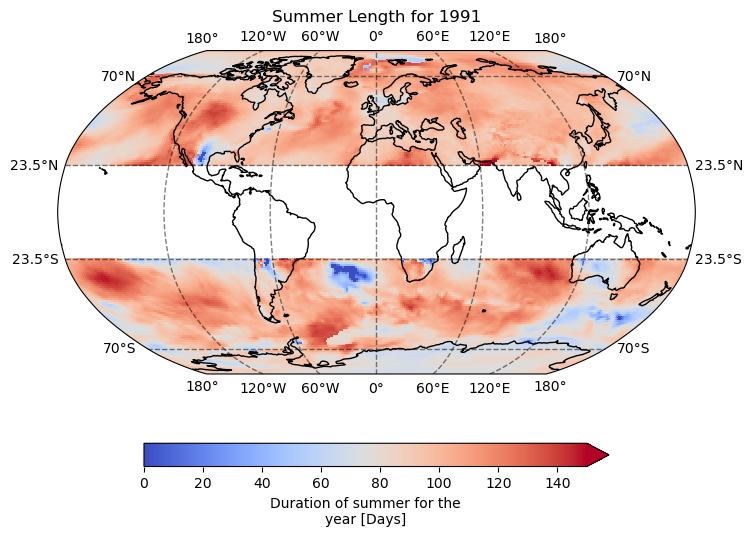

Time for 1991 :1.8673115833333334 min


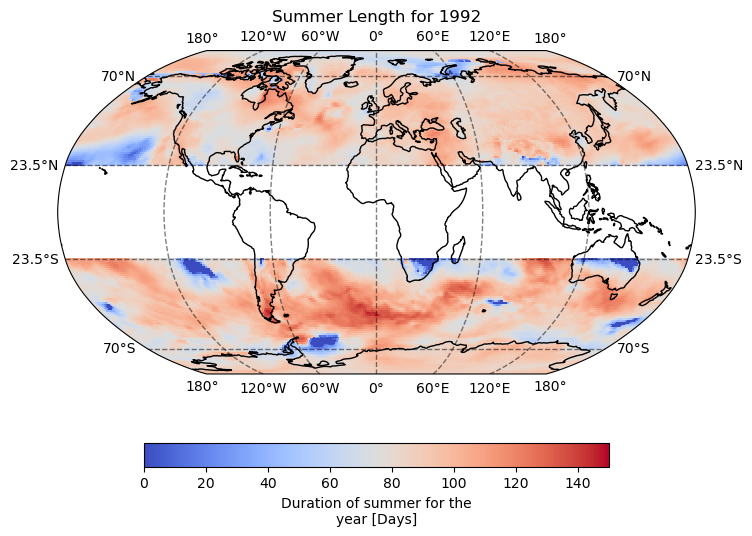

Time for 1992 :1.9041670166666667 min


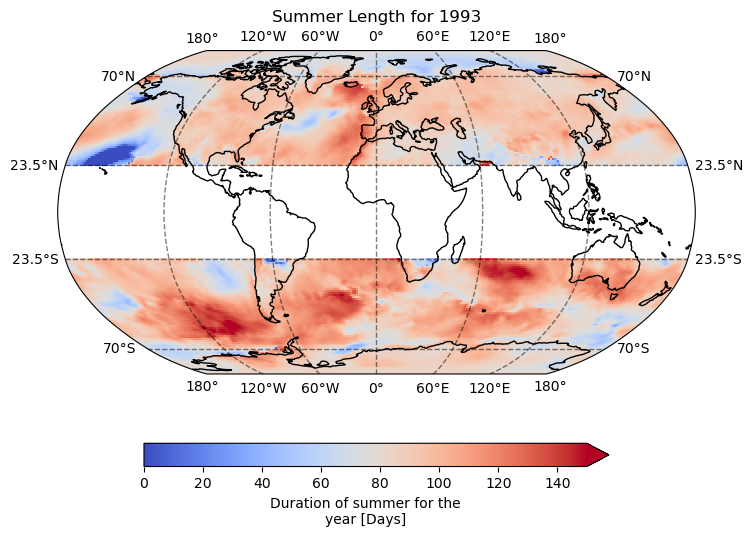

Time for 1993 :1.92619125 min


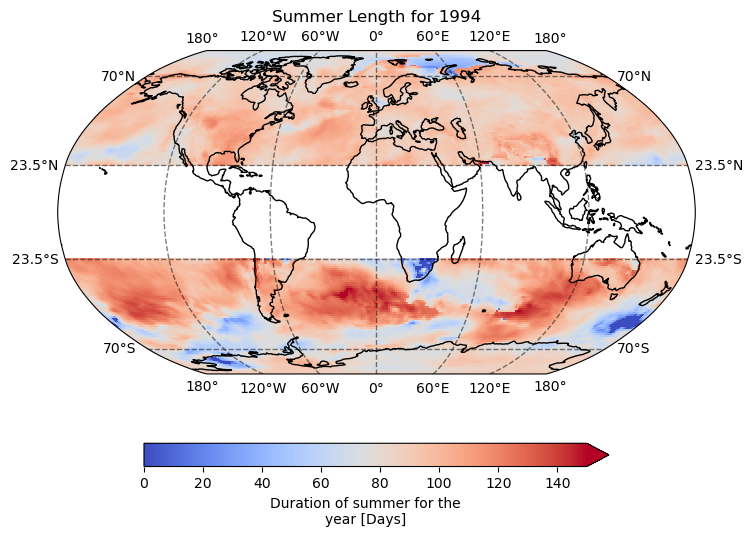

Time for 1994 :1.9347814833333332 min


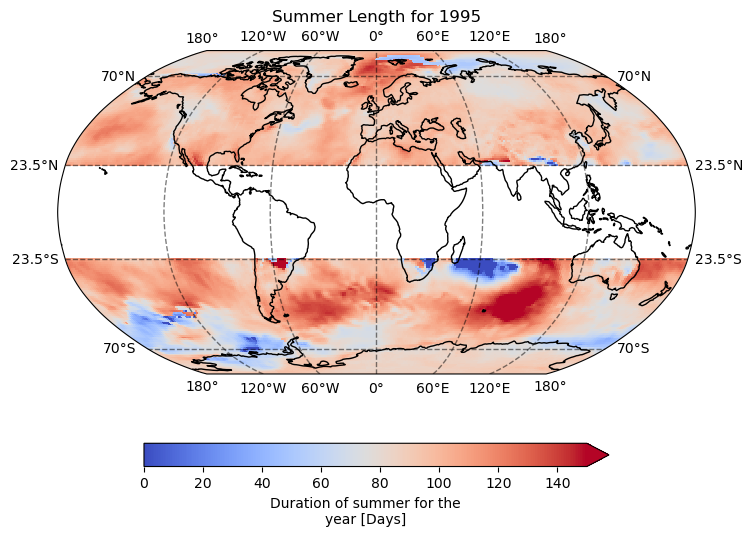

Time for 1995 :1.9812186666666667 min


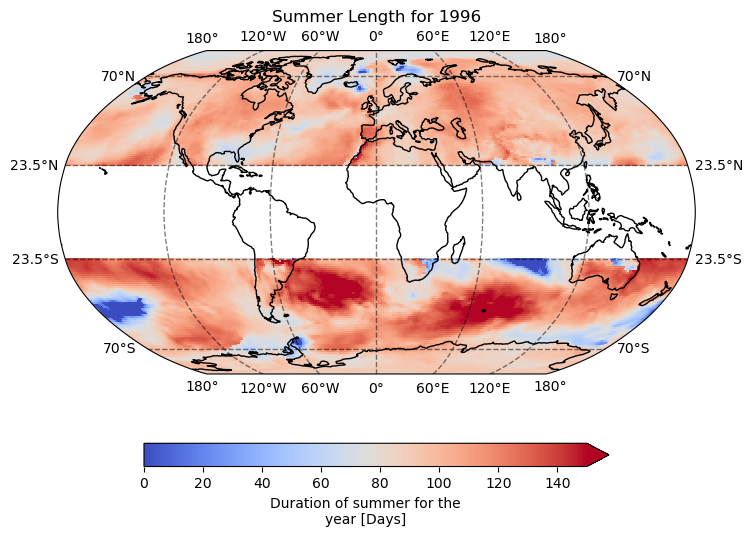

Time for 1996 :1.94909745 min


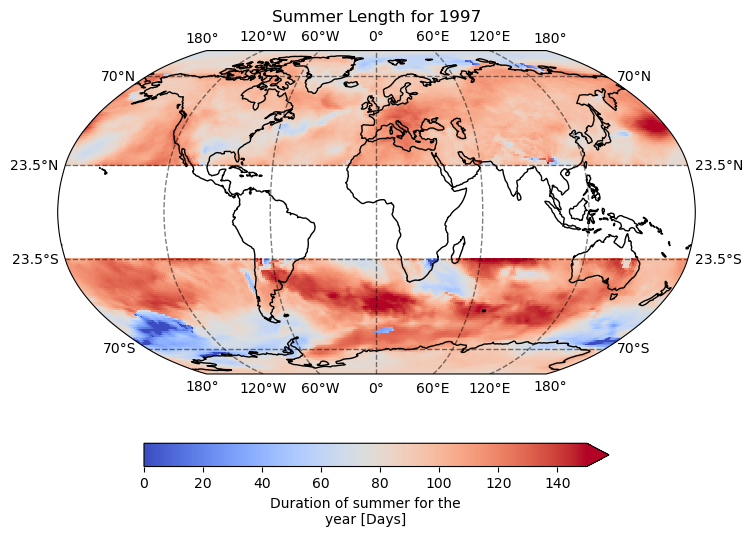

Time for 1997 :1.9419559333333334 min


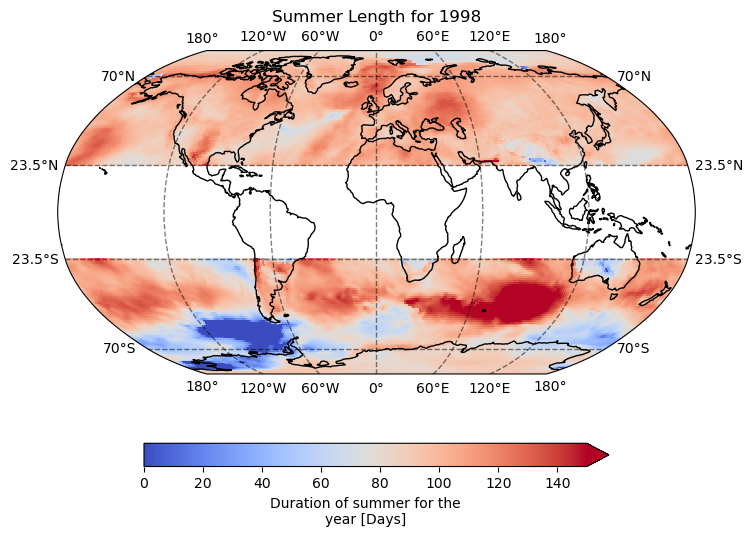

Time for 1998 :1.9751980833333334 min


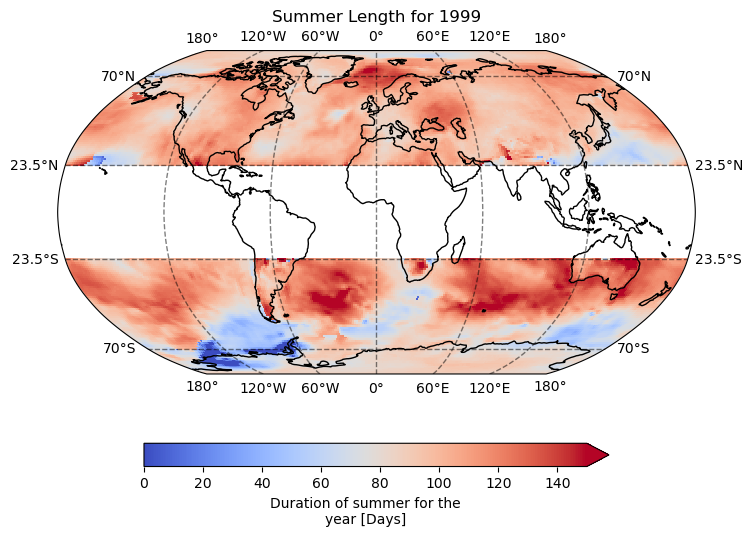

Time for 1999 :1.9733669166666667 min


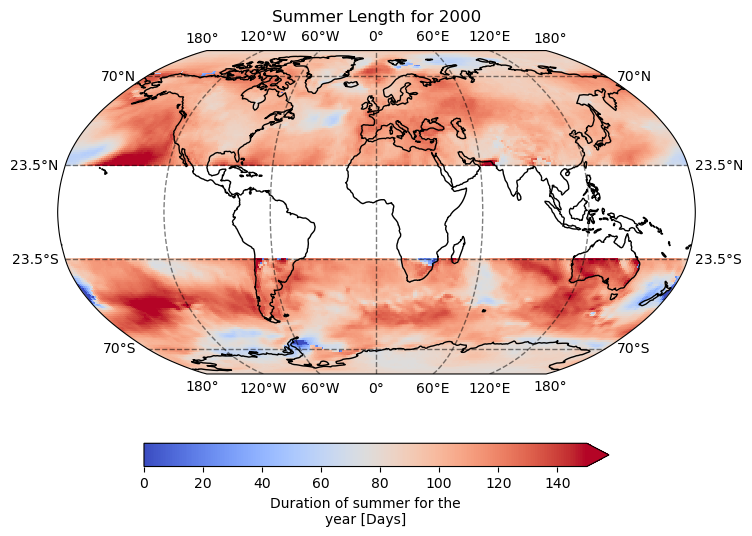

Time for 2000 :1.97553225 min


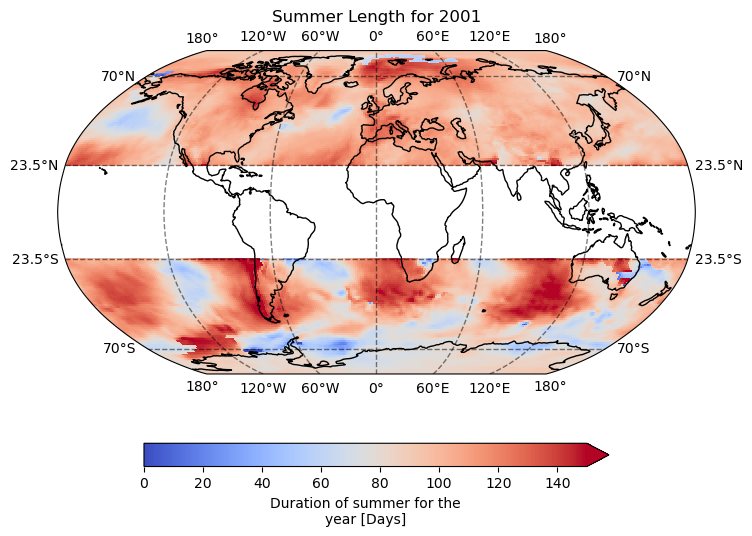

Time for 2001 :1.9388312833333332 min


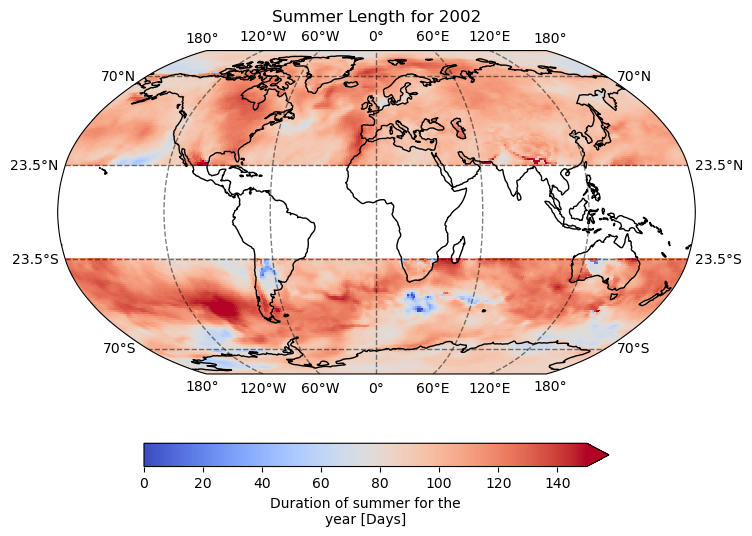

Time for 2002 :1.9668904666666667 min


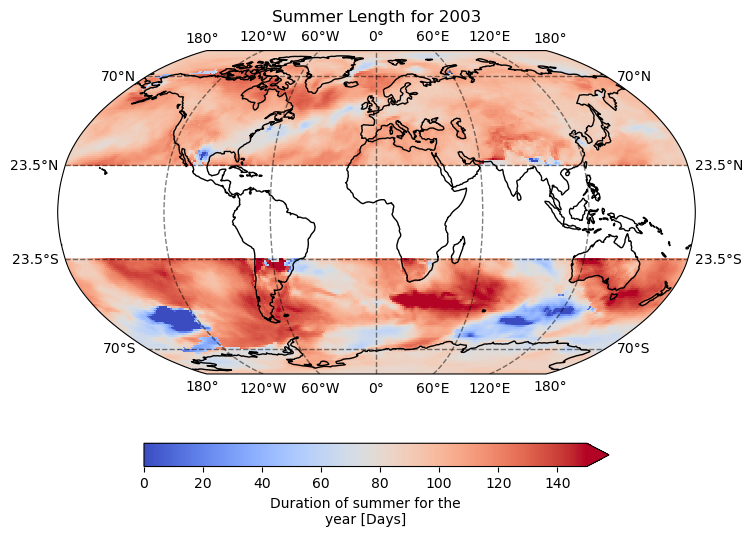

Time for 2003 :1.9870824833333331 min


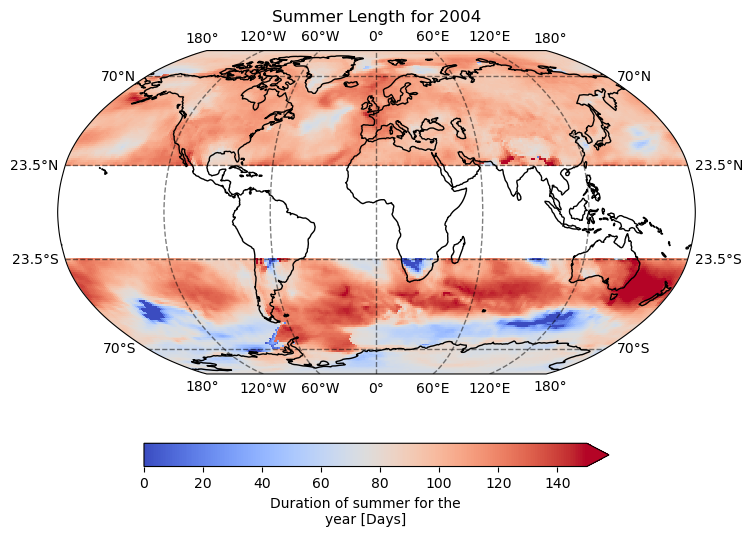

Time for 2004 :1.9754494833333331 min


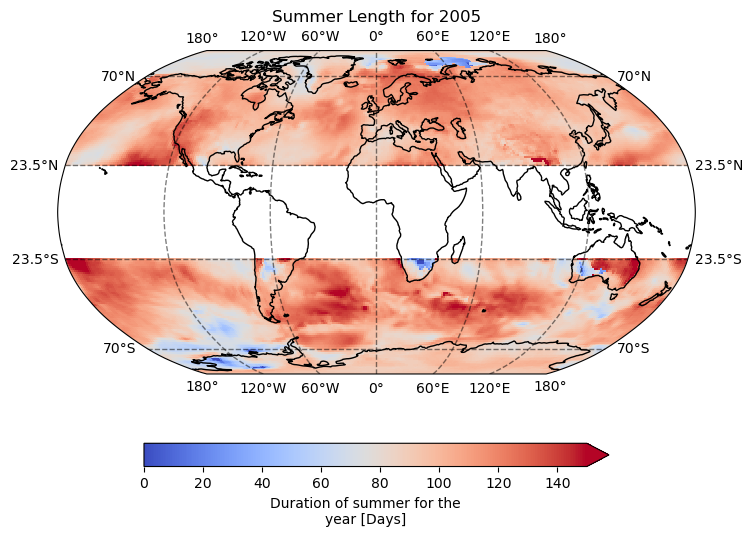

Time for 2005 :1.9471818833333332 min


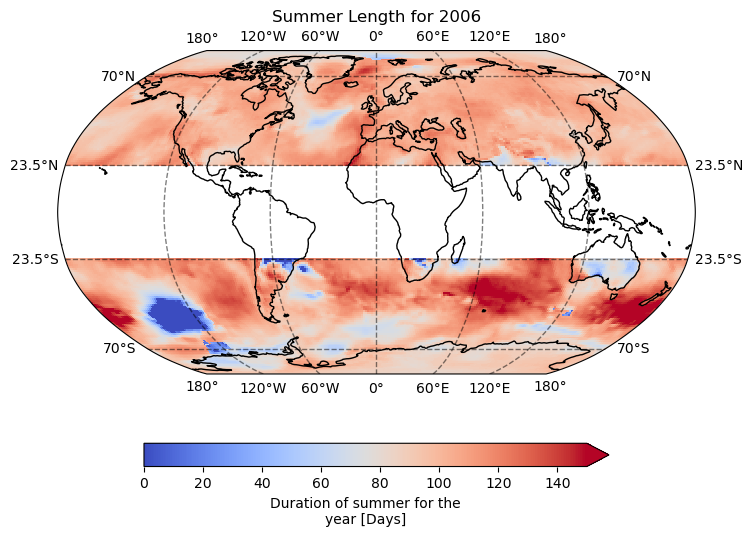

Time for 2006 :1.9487561999999998 min


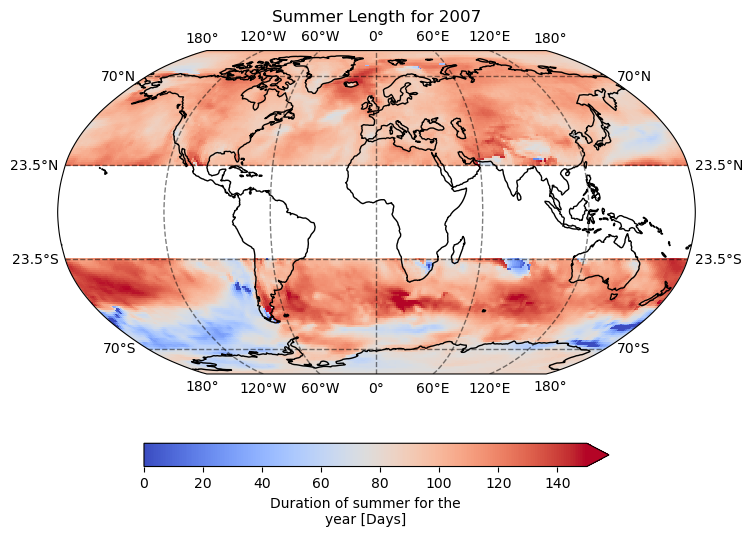

Time for 2007 :2.0118235 min


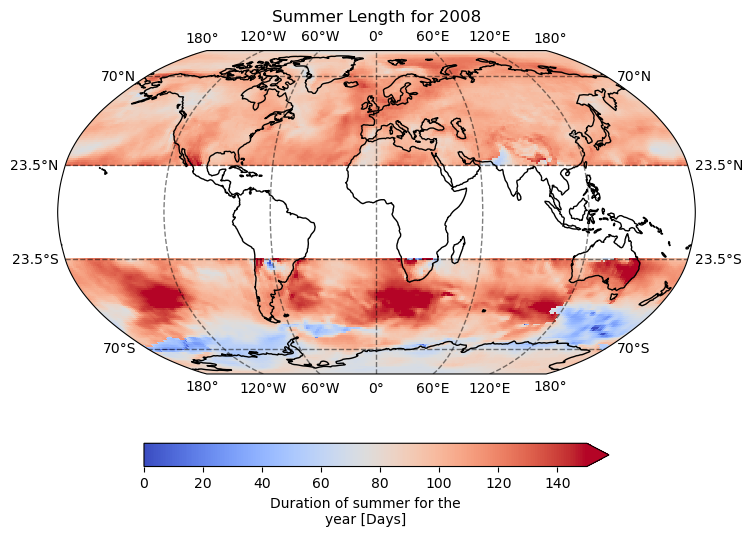

Time for 2008 :2.0124106833333335 min


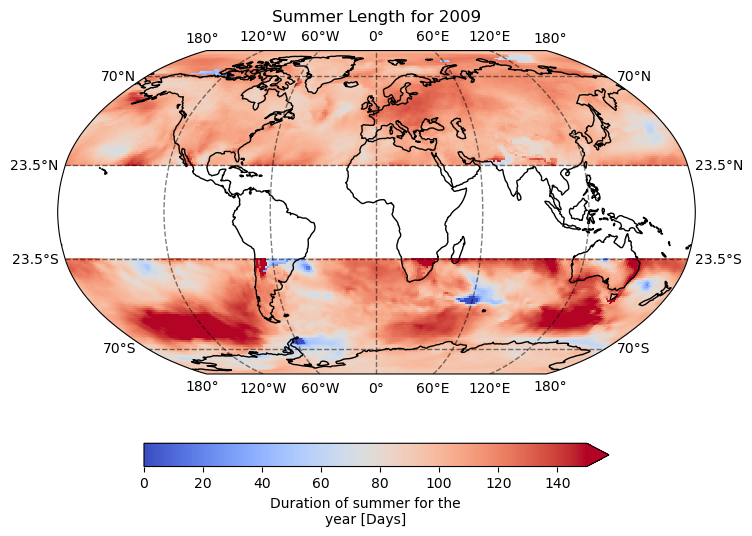

Time for 2009 :1.9404351166666667 min


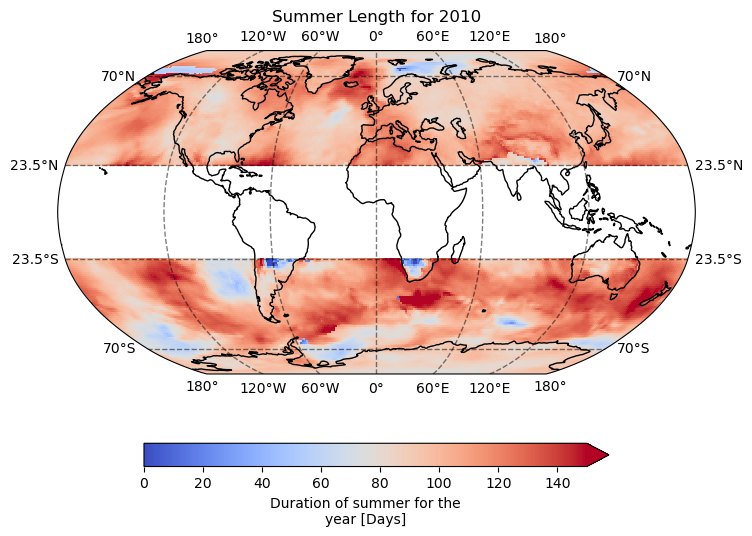

Time for 2010 :1.9679196333333333 min


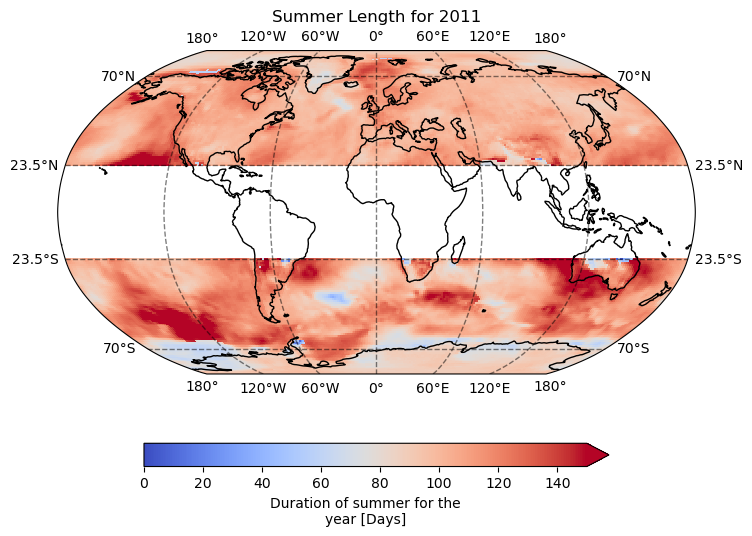

Time for 2011 :1.9689313333333334 min


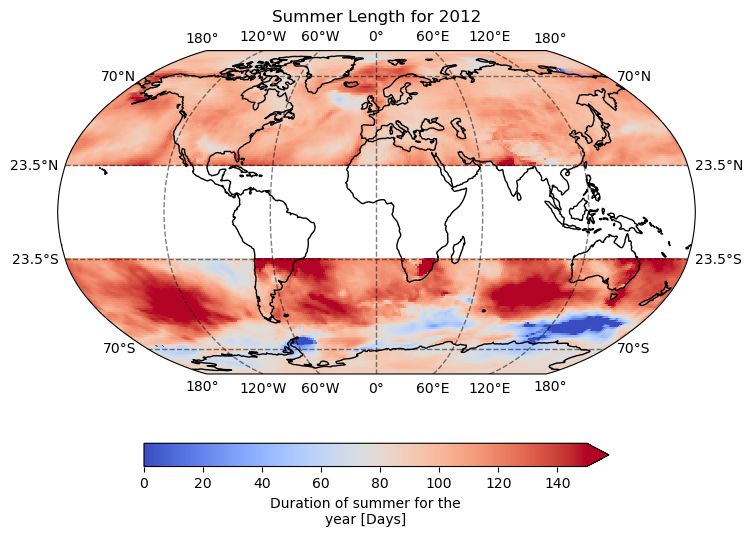

Time for 2012 :2.0047998333333332 min


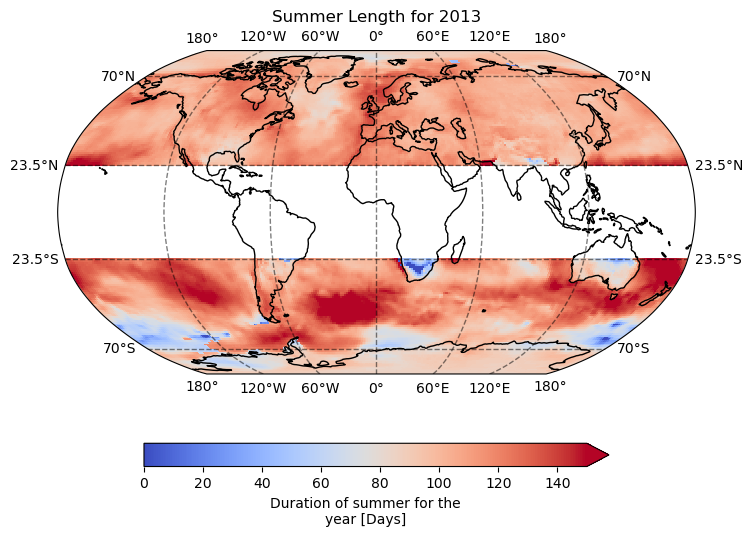

Time for 2013 :1.9969789 min


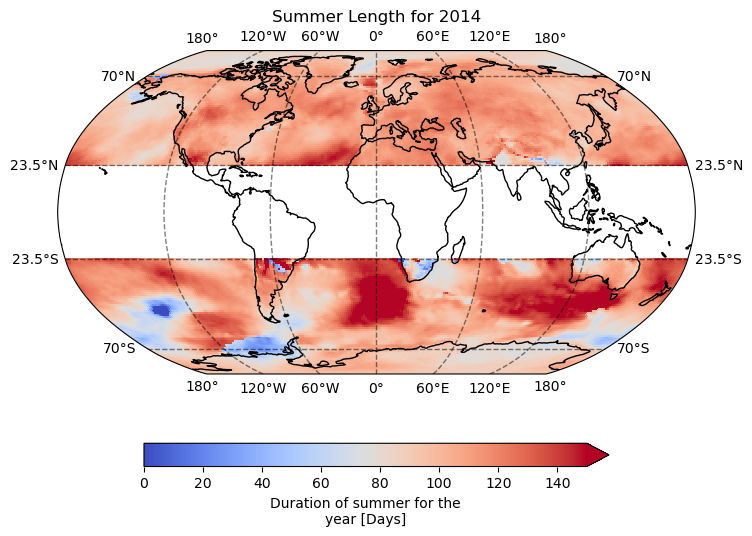

Time for 2014 :1.9834670166666666 min


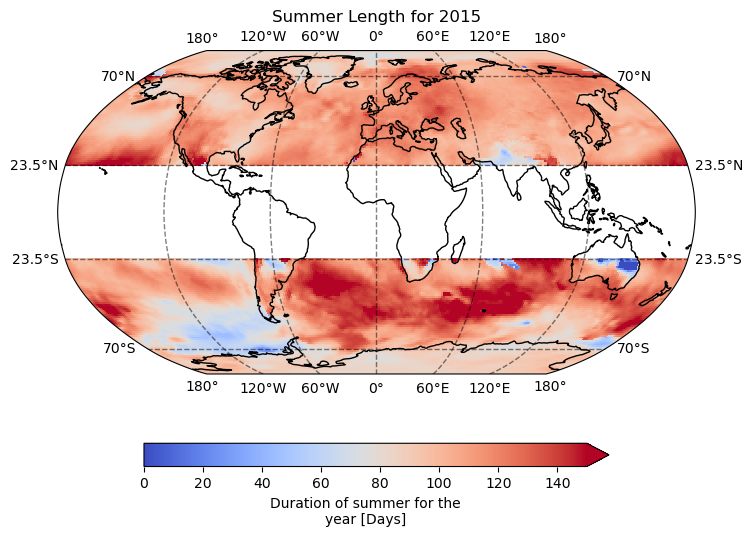

Time for 2015 :2.01702265 min


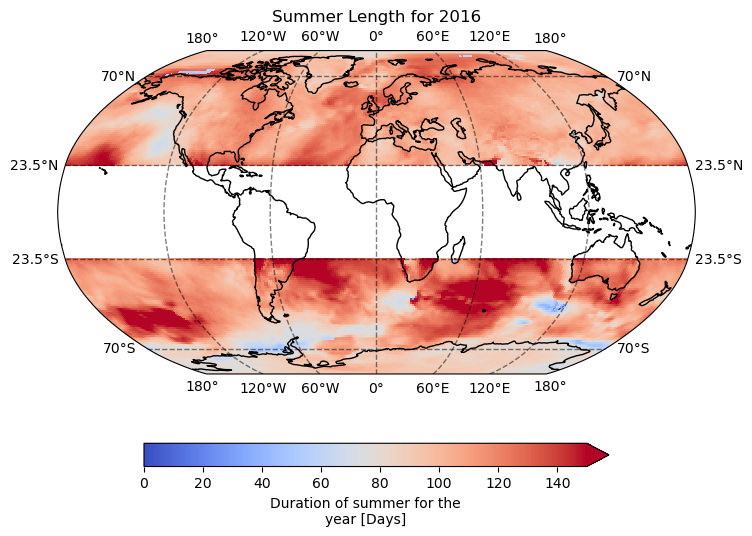

Time for 2016 :1.9779368 min


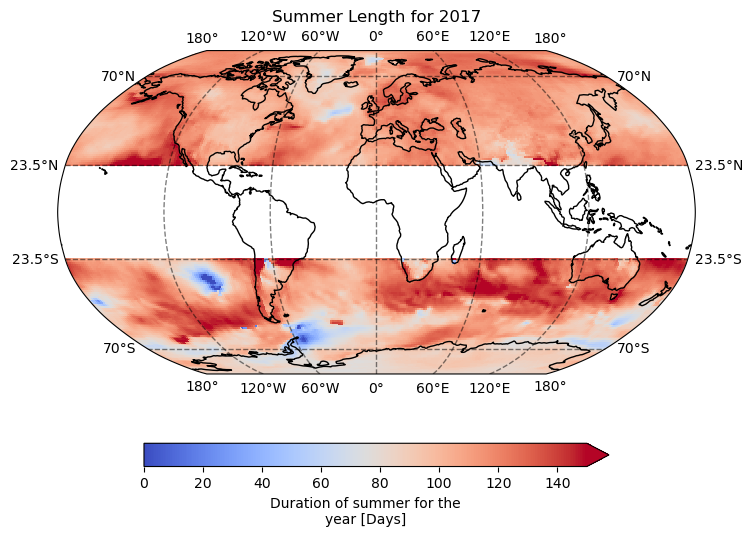

Time for 2017 :1.95927385 min


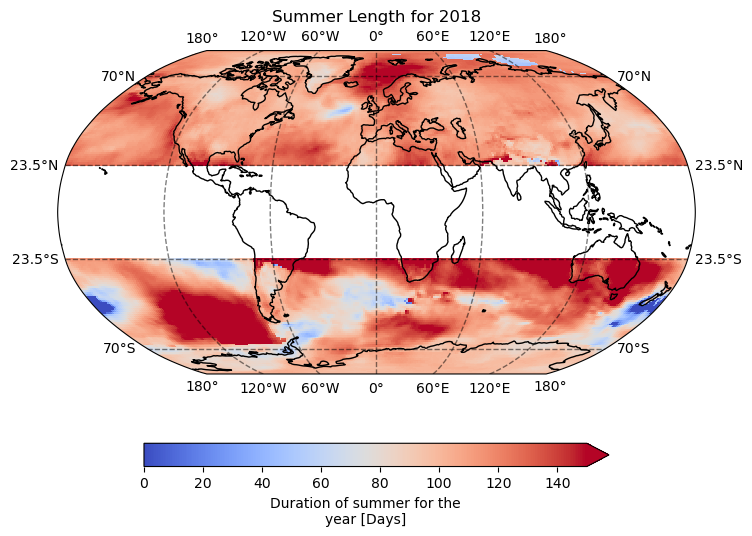

Time for 2018 :1.9668625166666667 min


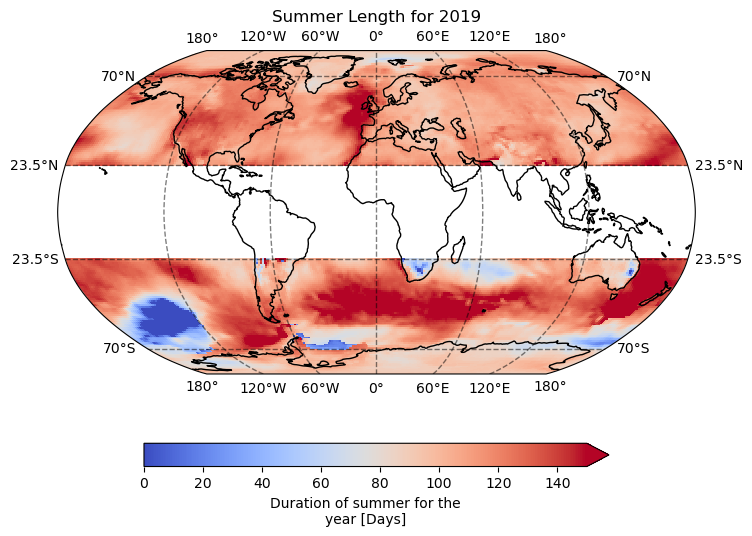

Time for 2019 :1.9627773666666668 min


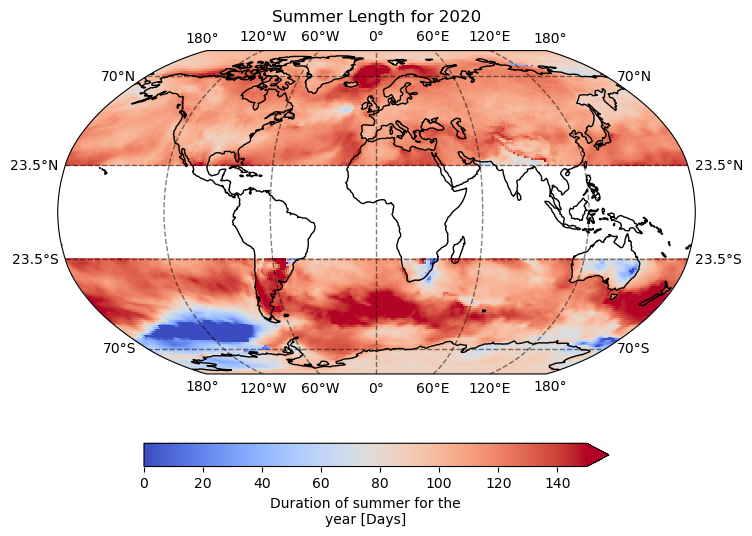

Time for 2020 :2.0249814666666666 min


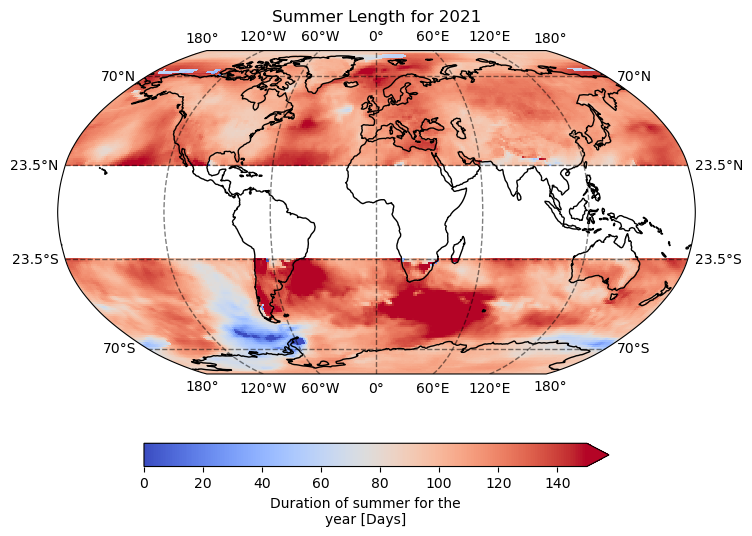

Time for 2021 :2.0277974166666666 min


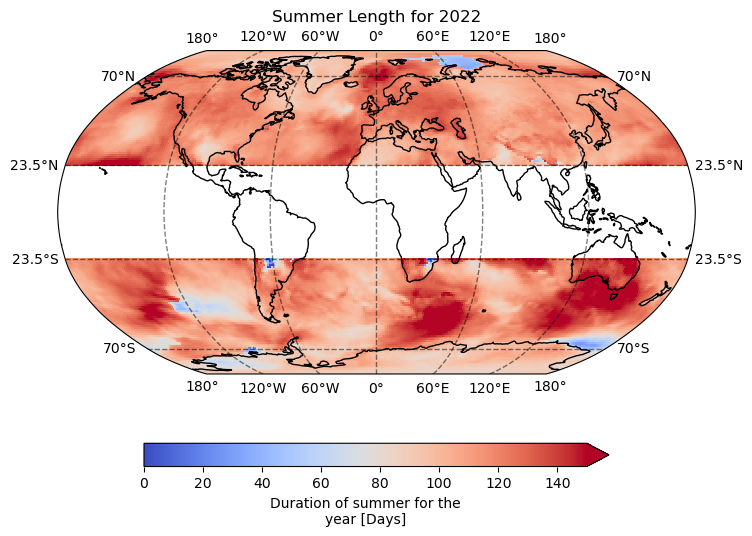

Time for 2022 :1.9811648333333334 min


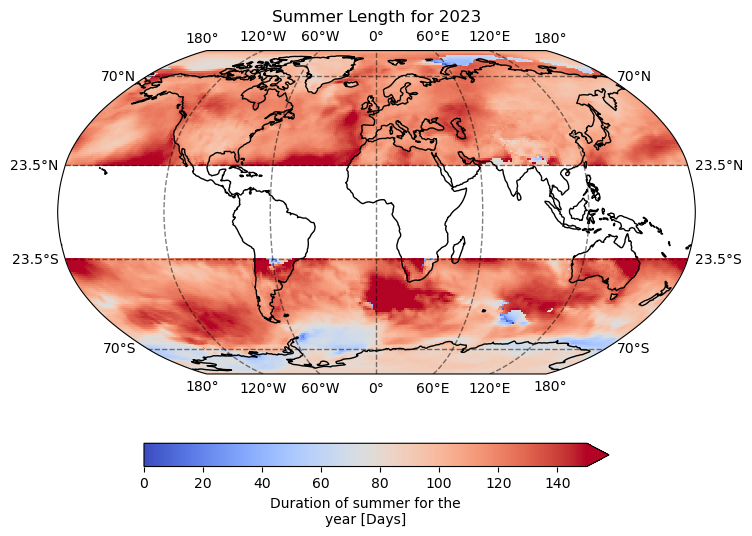

Time for 2023 :1.9737228999999998 min
CPU times: user 1h 4min 6s, sys: 50.3 s, total: 1h 4min 56s
Wall time: 1h 6min 51s


In [47]:
%%time

# Runtime: 1.9 min for 1 year
# 1hr 7 min for 34 yrs

# loop thru the years in the defined array above
for input_year in process_yrs:

    start = dt.now()

    ds = ds_gfdl.sel(time = str(input_year))

    dsnext = ds_gfdl.sel(time = str(input_year+1))

    # load into memory to speed up the summer stats processing
    ds.load()
    dsnext.load()

    # empty data arrays for summer stats
    summerlength = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                coords=[loop_lats, loop_lons], 
                                dims=['lat','lon'])
    summerstart = xr.DataArray(np.zeros((num_lat,num_lon)), 
                               coords=[loop_lats, loop_lons], 
                               dims=['lat','lon'])
    summerend = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summermax = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summerheat = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summerrmse = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summerr2 = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summermean = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summermeanhs = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    
    # add attributes
    summerstart.attrs["long_name"] = "Start day of summer for the year (DOY in [1,365])"
    summerstart.attrs["units"] = "Day of year"
    
    summerend.attrs["long_name"] = "Last day of summer for the year (DOY in [1,365])"
    summerend.attrs["units"] = "Day of year"
    
    summerlength.attrs["long_name"] = "Duration of summer for the year"
    summerlength.attrs["units"] = "Days"
    
    summermax.attrs["long_name"] = "Day of max mean temp during summer for the year"
    summermax.attrs["units"] = "Day of year"
    
    summerheat.attrs["long_name"] = "Accumulated heat during summer for the year"
    summerheat.attrs["units"] = "Degree-Days"
    
    summerrmse.attrs["long_name"] = "Root mean squared error of Fourier fit"
    summerrmse.attrs["units"] = "Degrees [K]"
    
    summerr2.attrs["long_name"] = "Coefficient of determination (R-squared) of Fourier fit [NOT USED]"
    summerr2.attrs["units"] = "Variance explained"

    summermean.attrs["long_name"] = "Mean temperature during the summer period"
    summermean.attrs["units"] = "Degrees [K]"

    summermeanhs.attrs["long_name"] = "Mean HS temperature during the summer period"
    summermeanhs.attrs["units"] = "Degrees [K]"

    ## now that I've added RMSE and R^2 - these loops take ~27 min with heat and tmax

    # loop through all of the lat,lon of interest
    for input_lat in loop_lats:
        for input_lon in loop_lons:
            # get threshold from c_75 - using closest location since not same grid as GFDL-ESM4
            thresh = c_75_gfdl.sel(lat=input_lat,lon=input_lon, method='nearest')
    
            # all the temps for that grid cell over time for this year and next (for SH)
            curr = ds.tas.sel(lat=input_lat,lon=input_lon) 
            nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon)
    
            # build summer stats for the grid cell and produce the plot if desired (currently False)
            start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True)
            
            # xarray requires strange indexing in order to replace values by coordinate
            summerstart.loc[input_lat, input_lon] = start_day
            summerend.loc[input_lat, input_lon] = last_day
            summermax.loc[input_lat, input_lon] = day_of_max
            summerheat.loc[input_lat, input_lon] = acc_heat
            summerlength.loc[input_lat, input_lon] = summer_length
            summerrmse.loc[input_lat, input_lon] = rmse
            summerr2.loc[input_lat, input_lon] = r2
            summermean.loc[input_lat, input_lon] = mean_temp
            summermeanhs.loc[input_lat, input_lon] = mean_hs
            

    # save it out
    sum_ds = xr.Dataset(data_vars={'SummerStart':summerstart,
                               'SummerEnd':summerend,
                               'SummerTmax':summermax,
                               'SummerHeat':summerheat,
                               'SummerLength':summerlength,
                               'SummerRMSE':summerrmse,
                               'SummerR2':summerr2,
                                'SummerMeanT':summermean,
                                   'SummerMeanHS':summermeanhs})
    output_path = '../../../Data/CMIP6/GFDL-ESM4/Summers/'+str(input_year)+'_GFDL-ESM4_r1i1p1f1_summer_stats.nc'
    sum_ds.to_netcdf(output_path)

    # plots for the year
    fig = plt.figure(figsize=(12,6))

    # assign axis and def projection to use
    ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))
    
    # add coastlines and grid
    ax.coastlines()
    ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([-70, -23.5, 23.5, 70]), linestyle='--')
    
    sum_ds.SummerLength.where((sum_ds.lat >= 23.5) | (sum_ds.lat <= -23.5)).plot(
        ax=ax,
        transform=ccrs.PlateCarree(), # assign map projection
        vmin=0,
        vmax=150, 
        cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
        cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
    )
    
    plt.title("Summer Length for "+str(input_year))#+" using 1961-1990 baseline")
    #plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
    plt.show()

    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(input_year)+" :"+str(elapsed)+" min")

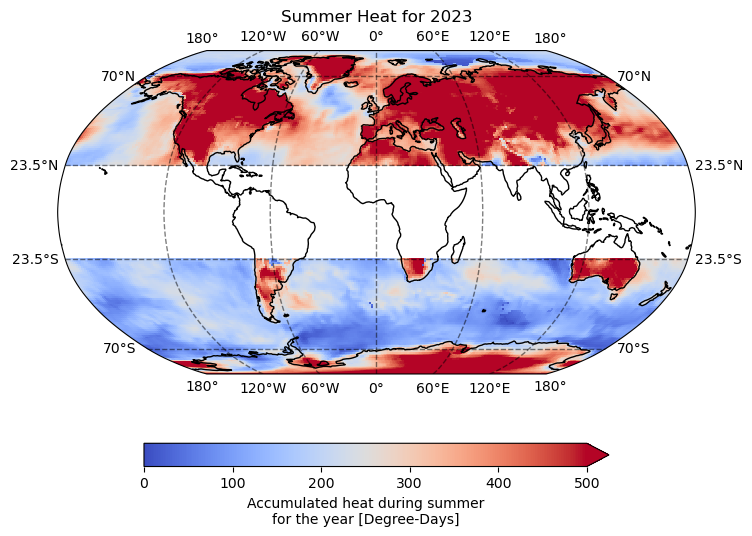

In [48]:
# plots for the year
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([-70, -23.5, 23.5, 70]), linestyle='--')

sum_ds.SummerHeat.where((sum_ds.lat >= 23.5) | (sum_ds.lat <= -23.5)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=0,
    vmax=500, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

plt.title("Summer Heat for "+str(input_year))#+" using 1961-1990 baseline")
#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

In [87]:
sum_ds

<xarray.Dataset> Size: 4MB
Dimensions:       (lat: 180, lon: 288)
Coordinates:
  * lat           (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 87.5 88.5 89.5
  * lon           (lon) float64 2kB -179.4 -178.1 -176.9 ... 176.9 178.1 179.4
Data variables:
    SummerStart   (lat, lon) float64 415kB 151.0 151.0 151.0 ... 156.0 156.0
    SummerEnd     (lat, lon) float64 415kB 213.0 213.0 213.0 ... 257.0 257.0
    SummerTmax    (lat, lon) float64 415kB 172.0 172.0 172.0 ... 218.0 218.0
    SummerHeat    (lat, lon) float64 415kB 203.7 204.0 204.4 ... 169.2 168.9
    SummerLength  (lat, lon) float64 415kB 63.0 63.0 63.0 ... 102.0 102.0 102.0
    SummerRMSE    (lat, lon) float64 415kB 5.572 5.565 5.558 ... 4.424 4.42
    SummerR2      (lat, lon) float64 415kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    SummerMeanT   (lat, lon) float64 415kB 239.0 239.1 239.1 ... 272.3 272.3
    SummerMeanHS  (lat, lon) float64 415kB 3.574 3.58 3.523 ... 1.839 1.836

## CESM2 data

#### Load baseline 75% percentile values from CESM2 historical data per grid cell
- prior use of ERA5 baseline showed bias especially for CanESM data

In [49]:
# get baseline
file_path = '../../../Data/CMIP6/CESM2/FixedCoords/baseline/computed_1961-1990-full_75th.nc'
c_75_cesm = xr.open_dataarray(file_path)
c_75_cesm.values


array([[234.80058289, 234.80616379, 234.80616379, ..., 234.75330353,
        234.75772476, 234.7748642 ],
       [234.26151276, 234.29961014, 234.3295517 , ..., 234.14857483,
        234.18935394, 234.22166824],
       [235.34697723, 235.40986633, 235.47353745, ..., 235.29081345,
        235.28463364, 235.32973862],
       ...,
       [270.73863983, 270.7377243 , 270.72985077, ..., 270.75177765,
        270.74143219, 270.73791504],
       [270.77828217, 270.77237701, 270.78060913, ..., 270.78917694,
        270.78504181, 270.78116608],
       [270.84149933, 270.84282684, 270.84532928, ..., 270.84636688,
        270.84644318, 270.84247589]], shape=(192, 288))

In [50]:
file_path = '../../../Data/CMIP6/CESM2/FixedCoords/*.nc'
#file_path = '../../../Data/CMIP6/GFDL-ESM4/tas_day_GFDL-ESM4_ssp245_r1i1p1f1_gr1_20150101-20241231.nc'

ds_cesm2 = xr.open_mfdataset(file_path)

In [51]:
ds_cesm2

<xarray.Dataset> Size: 3GB
Dimensions:    (time: 12776, bnds: 2, lon: 288, lat: 192)
Coordinates:
  * time       (time) object 102kB 1990-01-01 00:00:00 ... 2024-12-31 00:00:00
  * lon        (lon) float64 2kB -180.0 -178.8 -177.5 ... 176.2 177.5 178.8
  * lat        (lat) float64 2kB -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) object 204kB dask.array<chunksize=(1, 2), meta=np.ndarray>
    lon_bnds   (time, lon, bnds) float64 59MB dask.array<chunksize=(3650, 288, 2), meta=np.ndarray>
    lat_bnds   (time, lat, bnds) float64 39MB dask.array<chunksize=(3650, 192, 2), meta=np.ndarray>
    tas        (time, lat, lon) float32 3GB dask.array<chunksize=(1, 192, 288), meta=np.ndarray>
Attributes: (12/44)
    CDI:                    Climate Data Interface version 2.5.0 (https://mpi...
    Conventions:            CF-1.7 CMIP-6.2
    source:                 CESM2 (2017): atmosphere: CAM6 (0.9x1.25 finite v...
    institution:            National Center for Atmospheric Research, Climate...
    activity_id:            CMIP
    case_id:                15
    ...                     ...
    branch_time_in_parent:  219000.0
    branch_time_in_child:   674885.0
    branch_method:          standard
    further_info_url:       https://furtherinfo.es-doc.org/CMIP6.NCAR.CESM2.h...
    history:                Thu May 14 15:35:29 2026: cdo -sellonlatbox,-180,...
    CDO:                    Climate Data Operators version 2.5.0 (https://mpi...

#### update time variable

In [52]:
ds_cesm2['time'] = ds_cesm2.indexes['time'].to_datetimeindex()
ds_cesm2

<xarray.Dataset> Size: 3GB
Dimensions:    (time: 12776, bnds: 2, lon: 288, lat: 192)
Coordinates:
  * time       (time) datetime64[ns] 102kB 1990-01-01 1990-01-02 ... 2024-12-31
  * lon        (lon) float64 2kB -180.0 -178.8 -177.5 ... 176.2 177.5 178.8
  * lat        (lat) float64 2kB -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) object 204kB dask.array<chunksize=(1, 2), meta=np.ndarray>
    lon_bnds   (time, lon, bnds) float64 59MB dask.array<chunksize=(3650, 288, 2), meta=np.ndarray>
    lat_bnds   (time, lat, bnds) float64 39MB dask.array<chunksize=(3650, 192, 2), meta=np.ndarray>
    tas        (time, lat, lon) float32 3GB dask.array<chunksize=(1, 192, 288), meta=np.ndarray>
Attributes: (12/44)
    CDI:                    Climate Data Interface version 2.5.0 (https://mpi...
    Conventions:            CF-1.7 CMIP-6.2
    source:                 CESM2 (2017): atmosphere: CAM6 (0.9x1.25 finite v...
    institution:            National Center for Atmospheric Research, Climate...
    activity_id:            CMIP
    case_id:                15
    ...                     ...
    branch_time_in_parent:  219000.0
    branch_time_in_child:   674885.0
    branch_method:          standard
    further_info_url:       https://furtherinfo.es-doc.org/CMIP6.NCAR.CESM2.h...
    history:                Thu May 14 15:35:29 2026: cdo -sellonlatbox,-180,...
    CDO:                    Climate Data Operators version 2.5.0 (https://mpi...

### Test for Vancouver 2000 - nearest grid cell

In [53]:
#test for Vancouver
input_lat = 49.246
input_lon = -123.116

thresh = c_75_cesm.sel(lat=input_lat, lon=input_lon, method="nearest")
thresh

<xarray.DataArray 'tas' ()> Size: 8B
array(286.113365)
Coordinates:
    lat       float64 8B 49.48
    lon       float64 8B -122.5
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [54]:
input_year = 2000

ds = ds_cesm2.sel(time = str(input_year))
curr = ds.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
dsnext = ds_cesm2.sel(time = str(input_year+1))
nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
curr, nxt

(<xarray.DataArray 'tas' (time: 365)> Size: 1kB
 dask.array<getitem, shape=(365,), dtype=float32, chunksize=(1,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 3kB 2000-01-01 2000-01-02 ... 2000-12-31
     lon      float64 8B -122.5
     lat      float64 8B 49.48
 Attributes: (12/19)
     standard_name:  air_temperature
     long_name:      Near-Surface Air Temperature
     units:          K
     cell_measures:  area: areacella
     cell_methods:   area: time: mean
     comment:        near-surface (usually, 2 meter) air temperature
     ...             ...
     time:           time
     time_label:     time-mean
     time_title:     Temporal mean
     title:          Near-Surface Air Temperature
     type:           real
     variable_id:    tas,
 <xarray.DataArray 'tas' (time: 365)> Size: 1kB
 dask.array<getitem, shape=(365,), dtype=float32, chunksize=(1,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 3kB 2001-01-01 2001-01-0

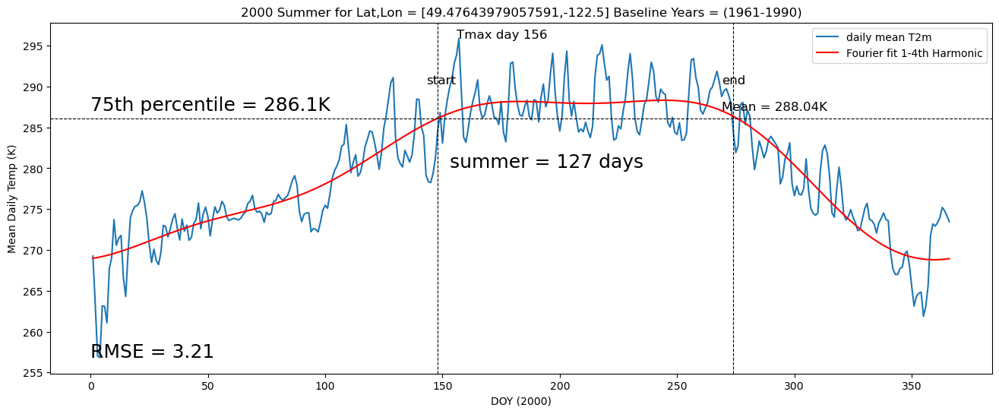

(148,
 274,
 156,
 304.83229064941406,
 127,
 3.212716579437256,
 0.0,
 288.0364685058594,
 3.387025451660179)

In [55]:
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True)
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

#### Vancouver 2023 uses ssp2-4.5 data

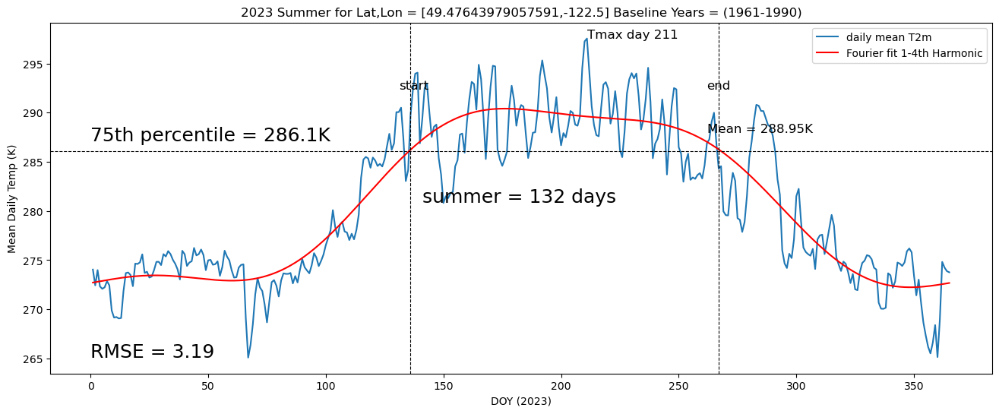

CPU times: user 1.03 s, sys: 210 ms, total: 1.24 s
Wall time: 1.12 s


(136,
 267,
 211,
 437.9076232910156,
 132,
 3.190014600753784,
 0.0,
 288.951171875,
 4.379076232910165)

In [56]:
%%time
input_year = 2023

ds = ds_cesm2.sel(time = str(input_year))
curr = ds.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
dsnext = ds_cesm2.sel(time = str(input_year+1))
nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True)
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Try Sydney Australia to test SH functioning

In [57]:
input_lat = -33 - 52/60 - 4/3600
input_lon = 151.25
thresh = c_75_cesm.sel(lat=input_lat, lon=input_lon, method="nearest")

curr = ds.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
curr, nxt

(<xarray.DataArray 'tas' (time: 365)> Size: 1kB
 dask.array<getitem, shape=(365,), dtype=float32, chunksize=(1,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 3kB 2023-01-01 2023-01-02 ... 2023-12-31
     lon      float64 8B 151.2
     lat      float64 8B -33.46
 Attributes: (12/19)
     standard_name:  air_temperature
     long_name:      Near-Surface Air Temperature
     units:          K
     cell_measures:  area: areacella
     cell_methods:   area: time: mean
     comment:        near-surface (usually, 2 meter) air temperature
     ...             ...
     time:           time
     time_label:     time-mean
     time_title:     Temporal mean
     title:          Near-Surface Air Temperature
     type:           real
     variable_id:    tas,
 <xarray.DataArray 'tas' (time: 365)> Size: 1kB
 dask.array<getitem, shape=(365,), dtype=float32, chunksize=(1,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 3kB 2024-01-01 2024-01-0

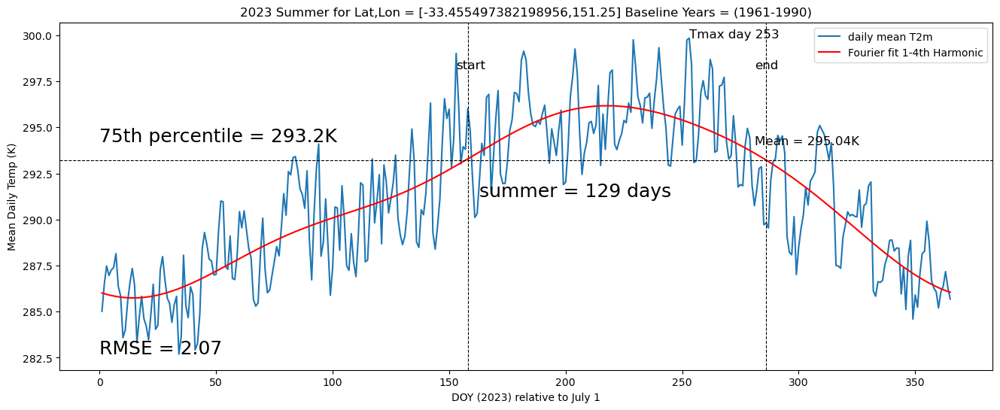

(158,
 286,
 253,
 273.2109680175781,
 129,
 2.07021427154541,
 0.0,
 295.038818359375,
 2.7321096801757676)

In [58]:
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True)
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

## Main Loop: loop through multiple years to generate summer stats

In [59]:
# grid parameters for looping
num_lat = ds_cesm2.lat.shape[0]
num_lon = ds_cesm2.lon.shape[0]

loop_lats = ds_cesm2.lat.values[:num_lat]
loop_lons = ds_cesm2.lon.values[:num_lon]
loop_lats, loop_lons

(array([-90.        , -89.05759162, -88.11518325, -87.17277487,
        -86.23036649, -85.28795812, -84.34554974, -83.40314136,
        -82.46073298, -81.51832461, -80.57591623, -79.63350785,
        -78.69109948, -77.7486911 , -76.80628272, -75.86387435,
        -74.92146597, -73.97905759, -73.03664921, -72.09424084,
        -71.15183246, -70.20942408, -69.26701571, -68.32460733,
        -67.38219895, -66.43979058, -65.4973822 , -64.55497382,
        -63.61256545, -62.67015707, -61.72774869, -60.78534031,
        -59.84293194, -58.90052356, -57.95811518, -57.01570681,
        -56.07329843, -55.13089005, -54.18848168, -53.2460733 ,
        -52.30366492, -51.36125654, -50.41884817, -49.47643979,
        -48.53403141, -47.59162304, -46.64921466, -45.70680628,
        -44.76439791, -43.82198953, -42.87958115, -41.93717277,
        -40.9947644 , -40.05235602, -39.10994764, -38.16753927,
        -37.22513089, -36.28272251, -35.34031414, -34.39790576,
        -33.45549738, -32.51308901, -31.

In [60]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1990, 2024,1)

process_yrs

array([1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000,
       2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011,
       2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022,
       2023])

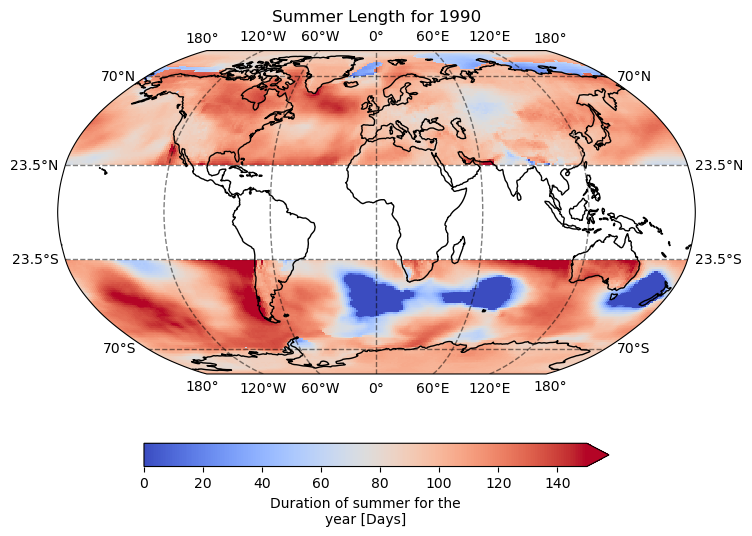

Time for 1990 :2.0061325333333335 min


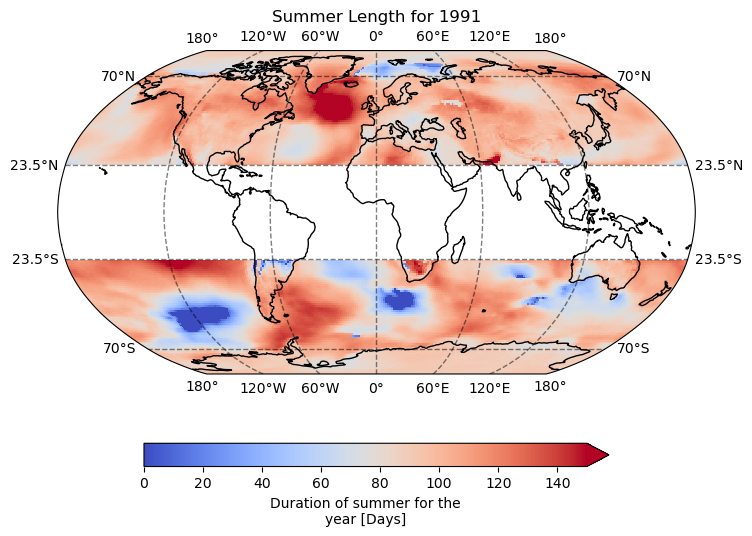

Time for 1991 :2.0323023166666667 min


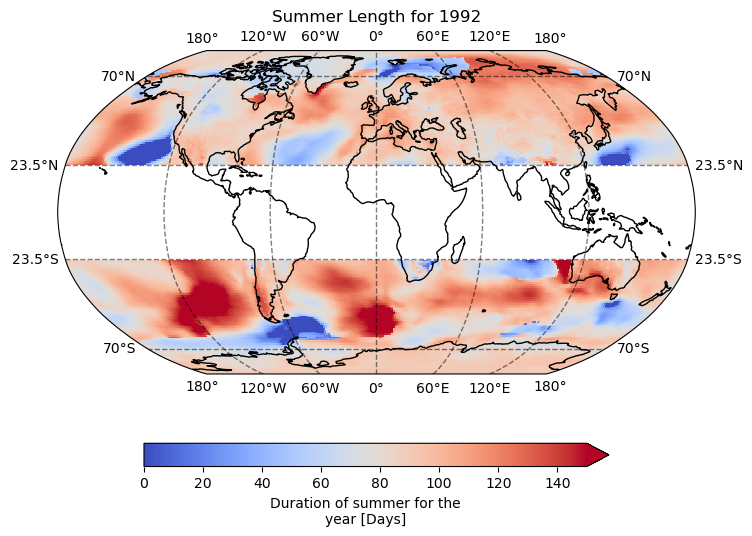

Time for 1992 :2.0276129333333333 min


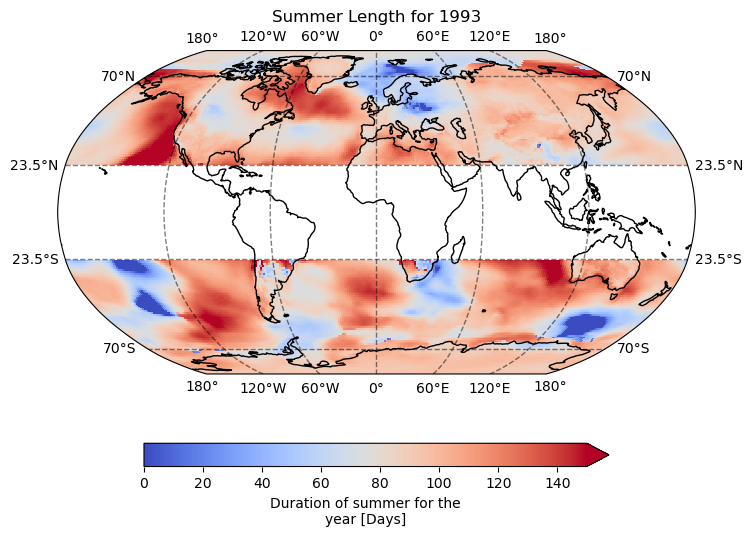

Time for 1993 :2.0914680999999997 min


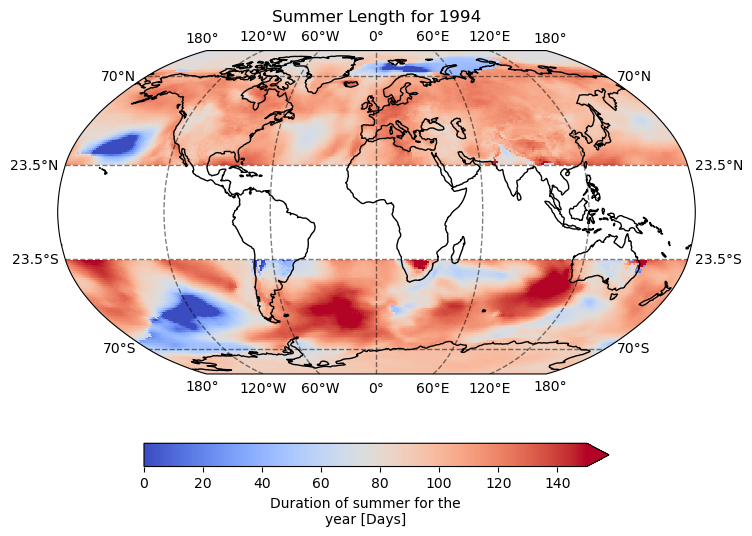

Time for 1994 :2.0277289 min


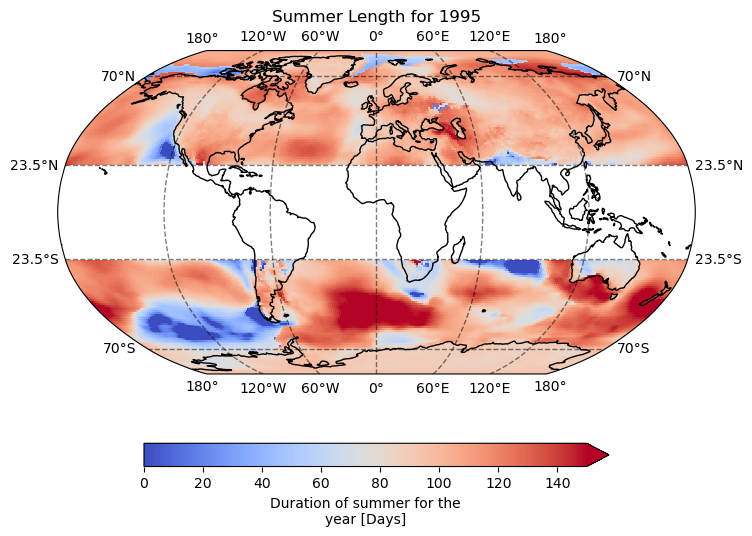

Time for 1995 :1.9770898333333333 min


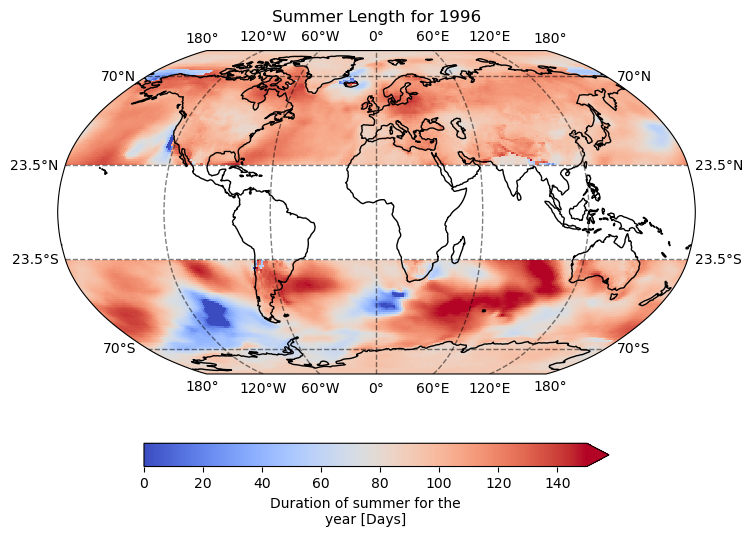

Time for 1996 :2.0464531 min


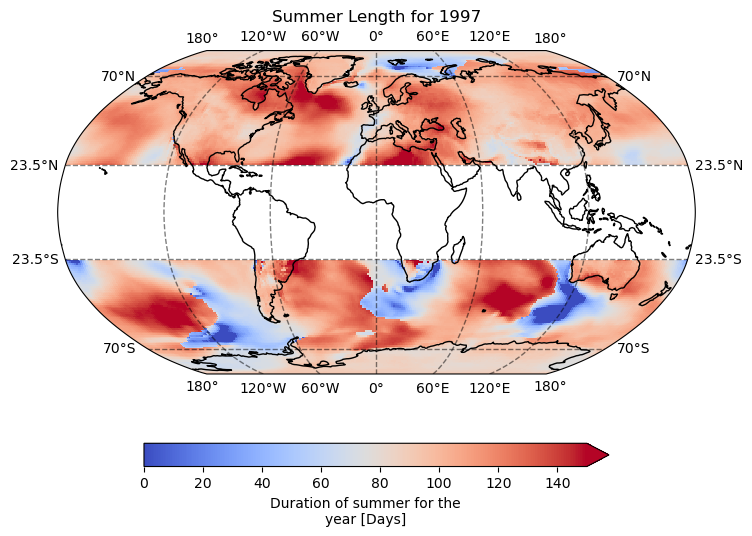

Time for 1997 :2.0718168333333336 min


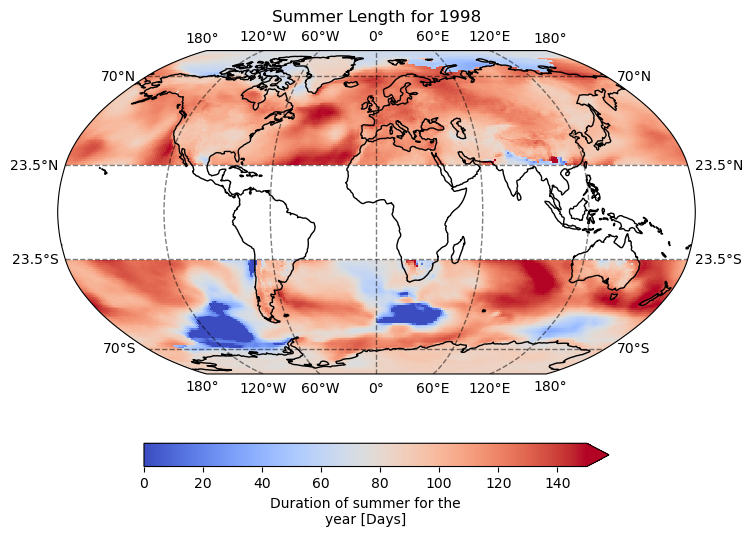

Time for 1998 :2.0760988166666667 min


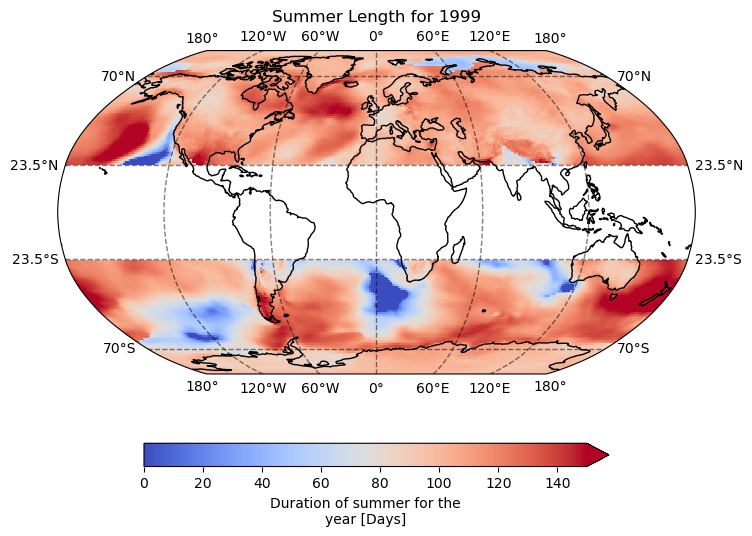

Time for 1999 :2.0161603333333336 min


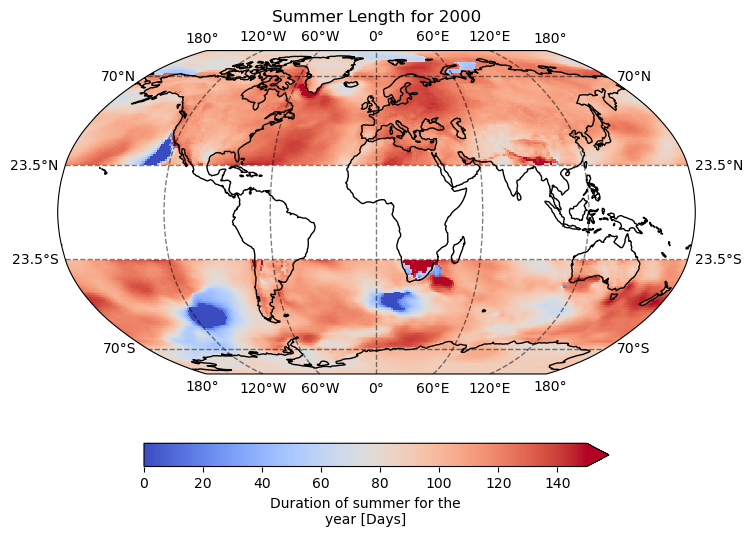

Time for 2000 :2.0418229666666665 min


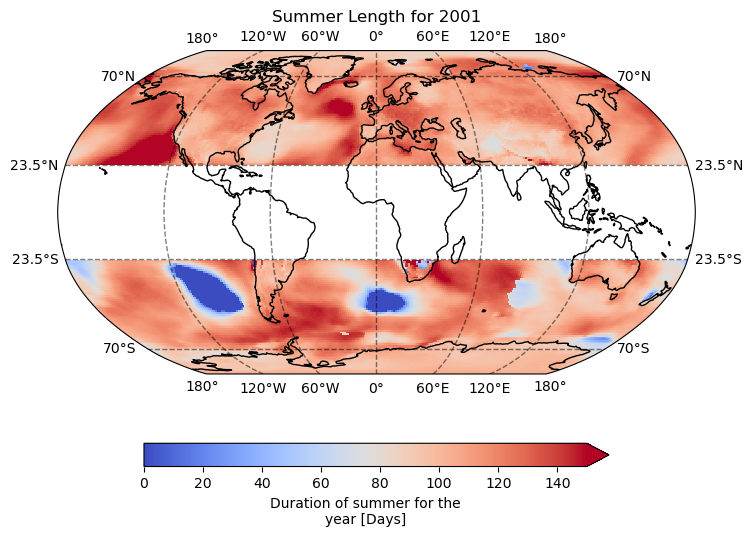

Time for 2001 :2.1475422166666664 min


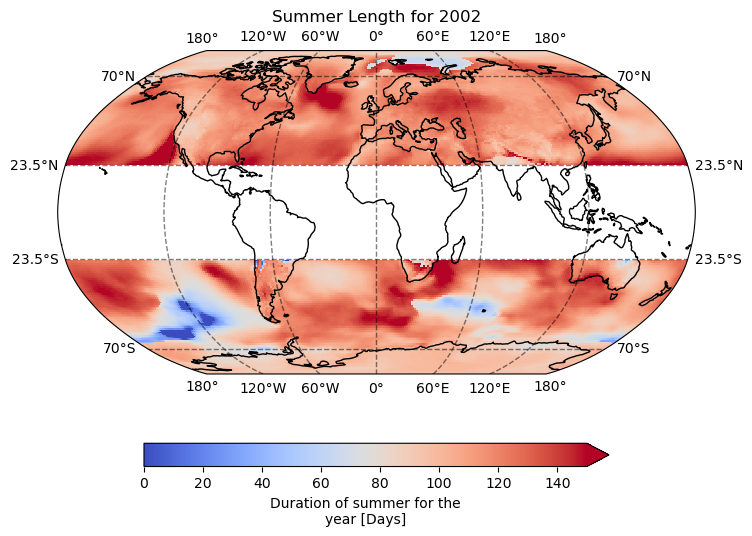

Time for 2002 :2.099001916666667 min


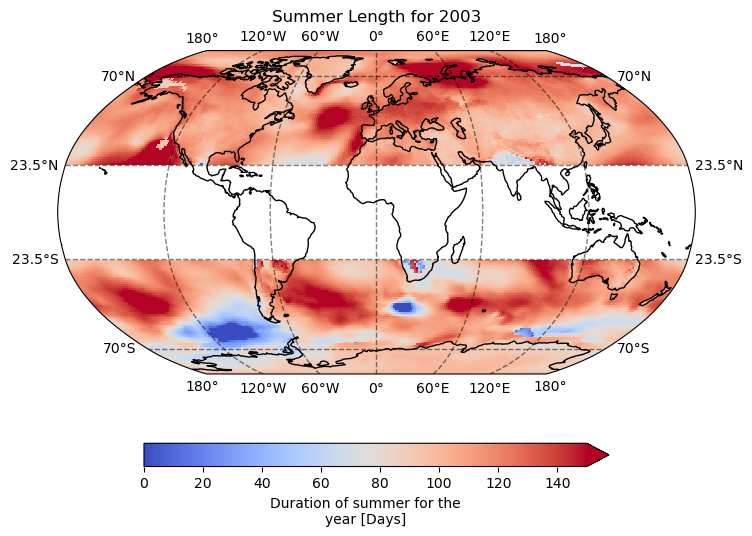

Time for 2003 :2.0456059166666667 min


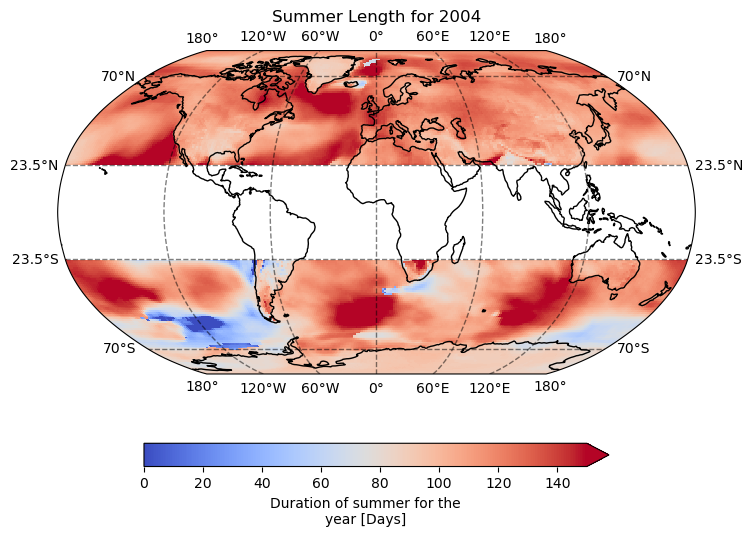

Time for 2004 :2.0387973500000003 min


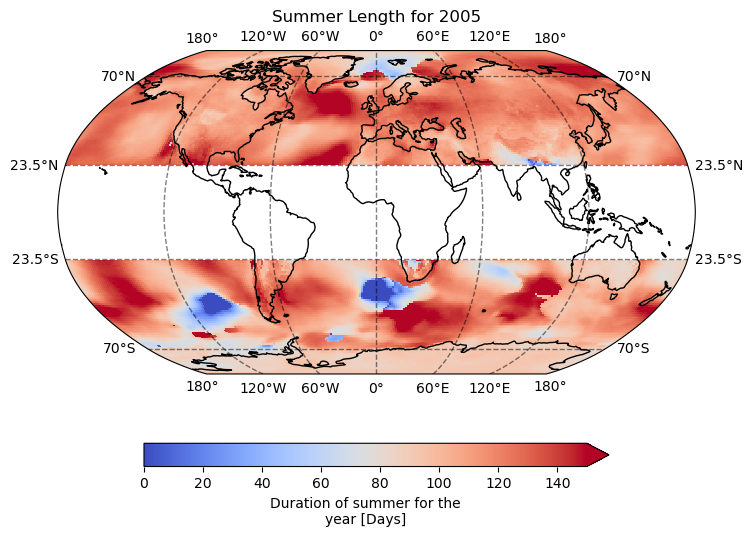

Time for 2005 :2.0373008666666665 min


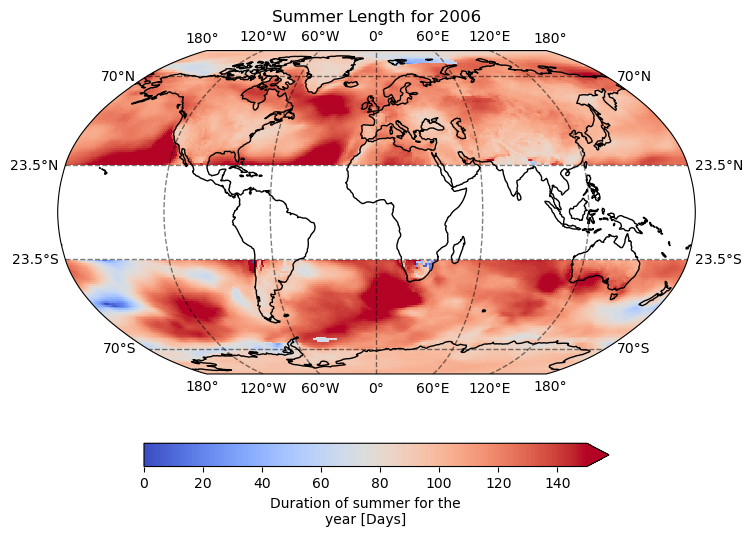

Time for 2006 :2.122614566666667 min


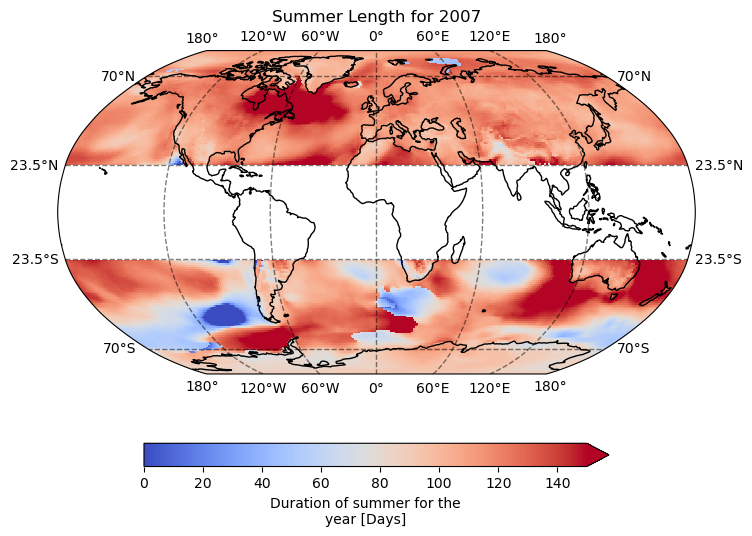

Time for 2007 :2.08622445 min


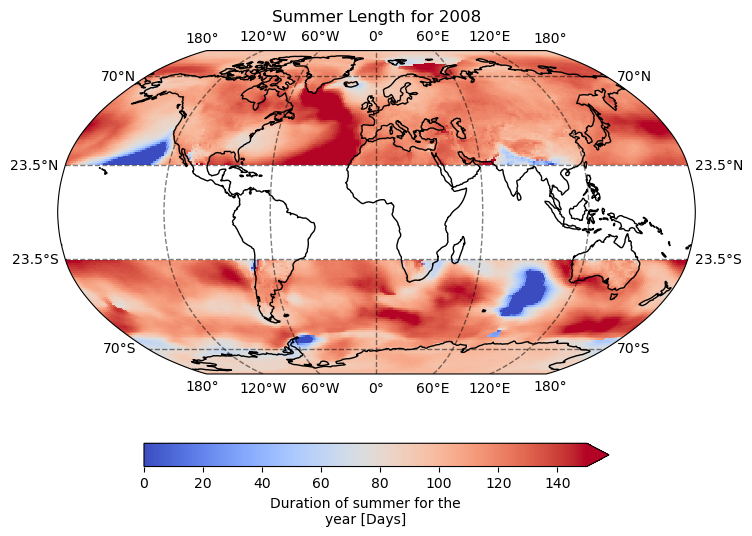

Time for 2008 :2.023102316666667 min


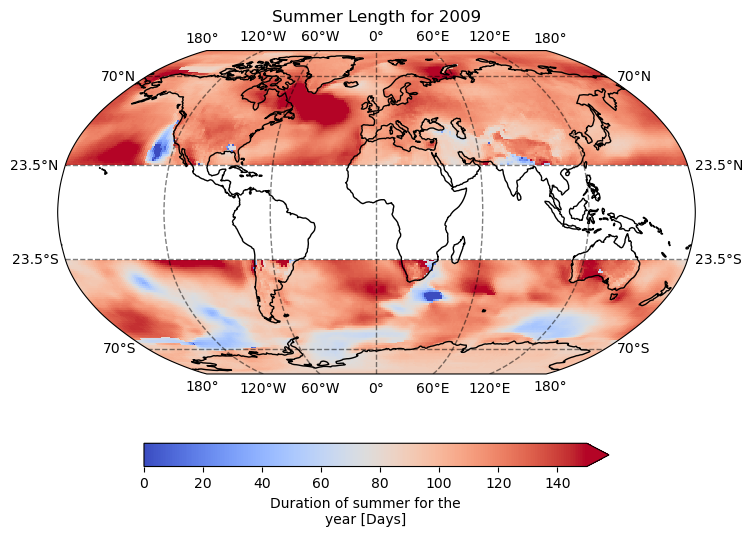

Time for 2009 :2.0422051833333335 min


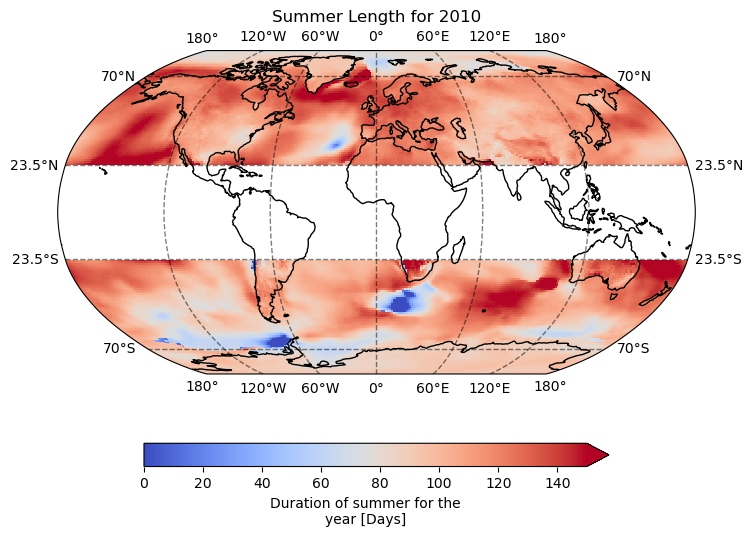

Time for 2010 :1.9863758666666667 min


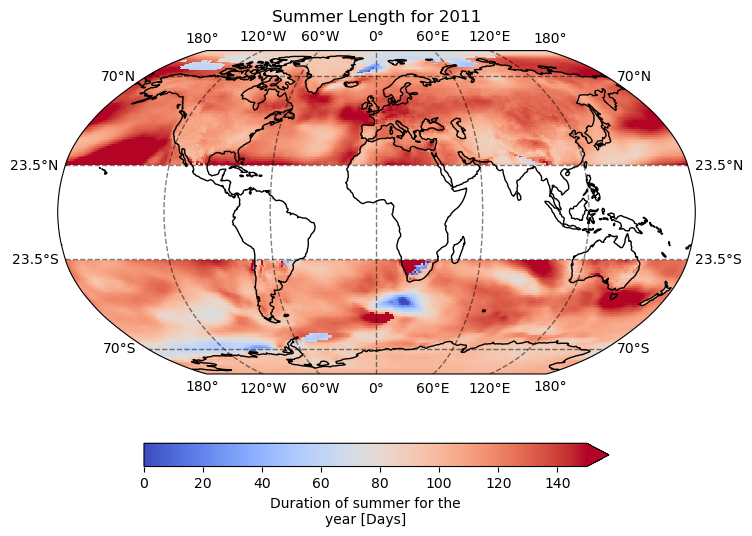

Time for 2011 :1.9907373833333333 min


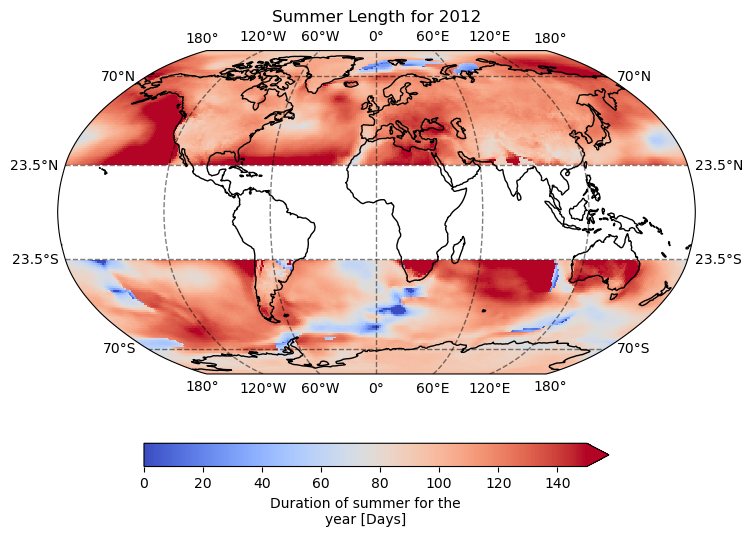

Time for 2012 :2.00508635 min


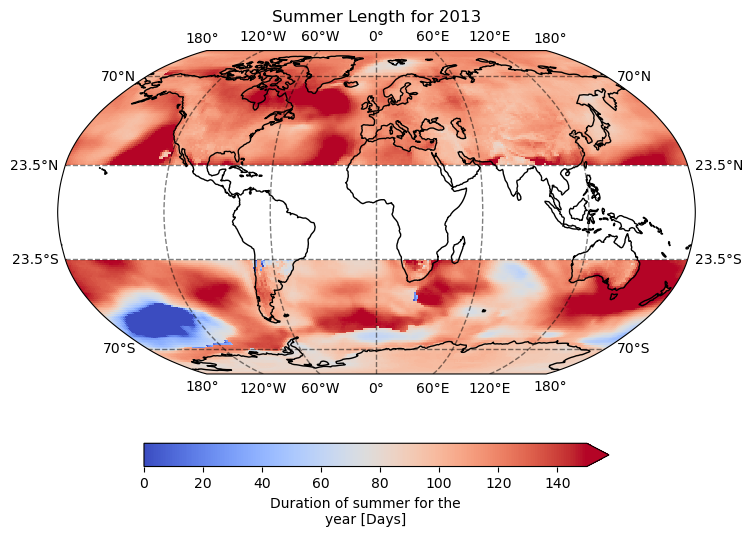

Time for 2013 :1.99125025 min


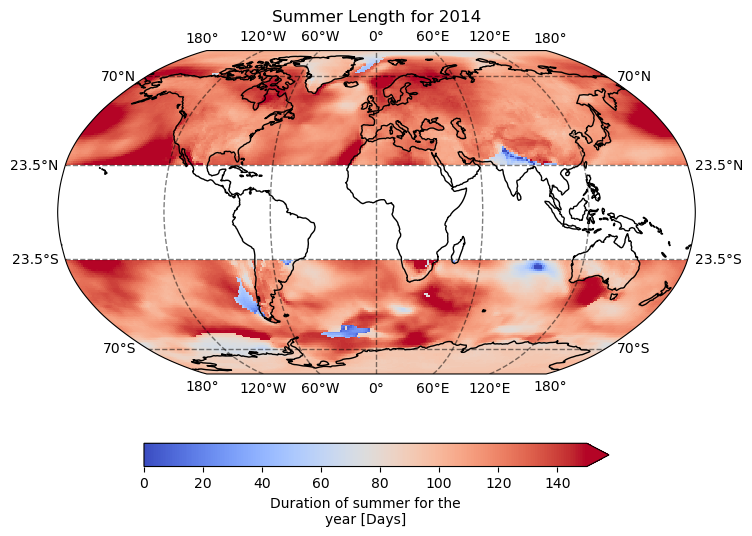

Time for 2014 :1.9983760333333334 min


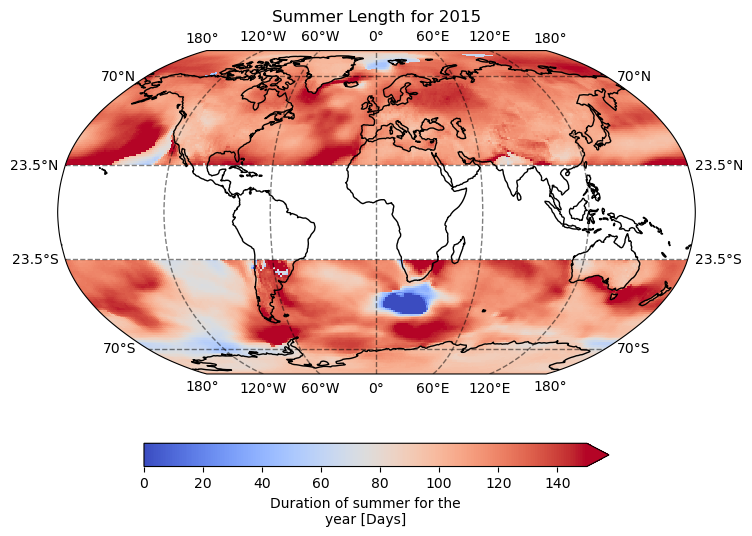

Time for 2015 :2.061342983333333 min


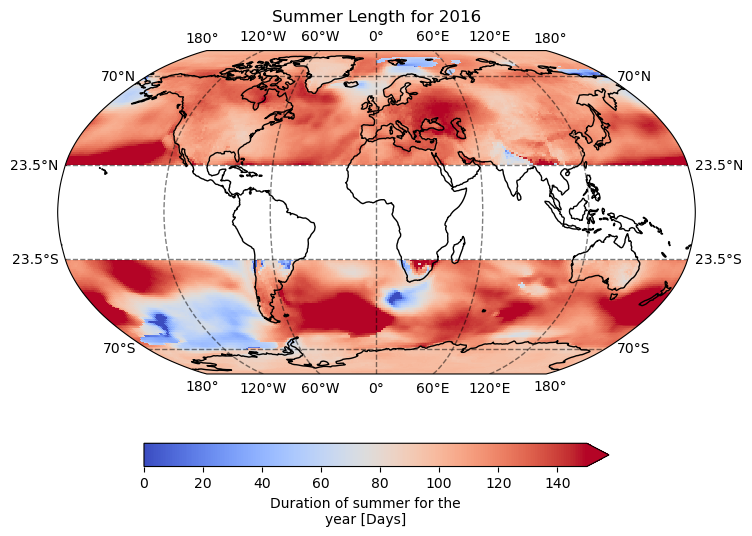

Time for 2016 :2.0267131 min


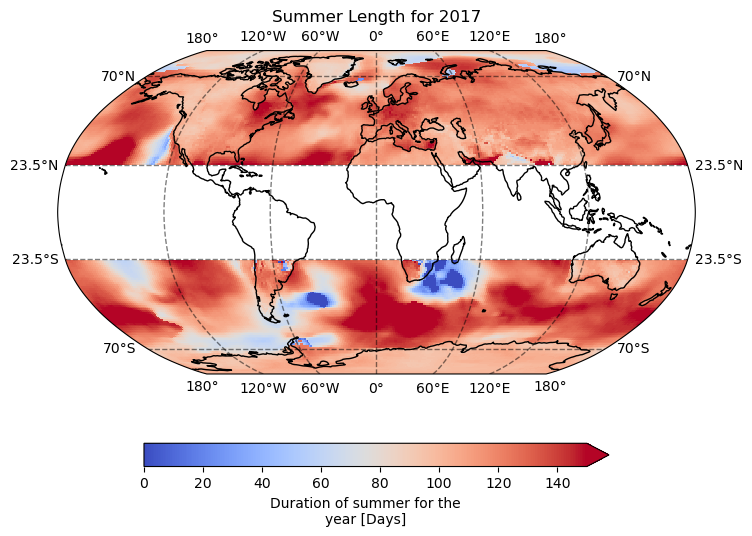

Time for 2017 :2.0333523166666665 min


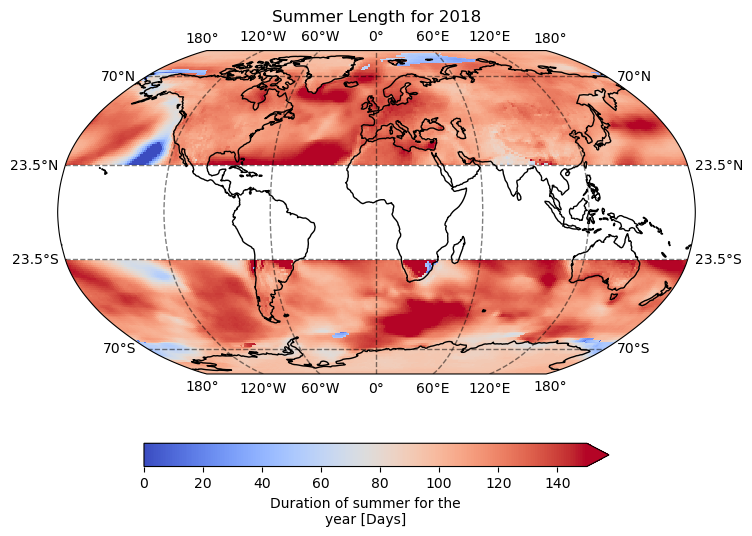

Time for 2018 :2.0167358833333333 min


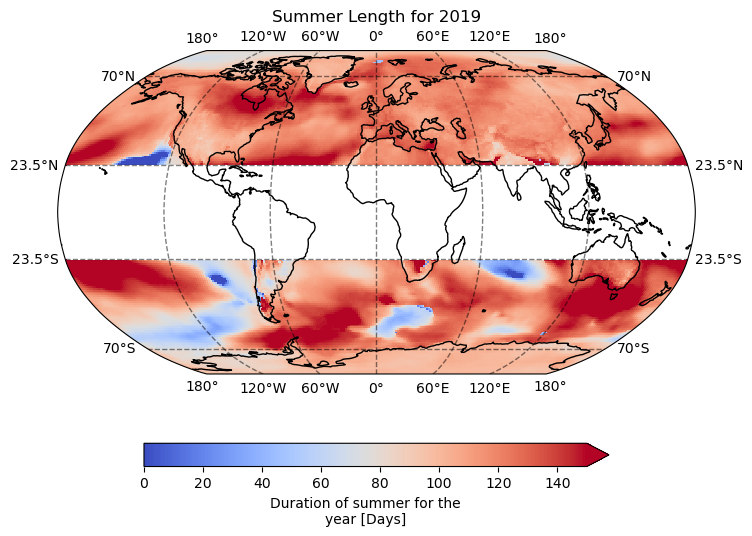

Time for 2019 :1.9806441833333333 min


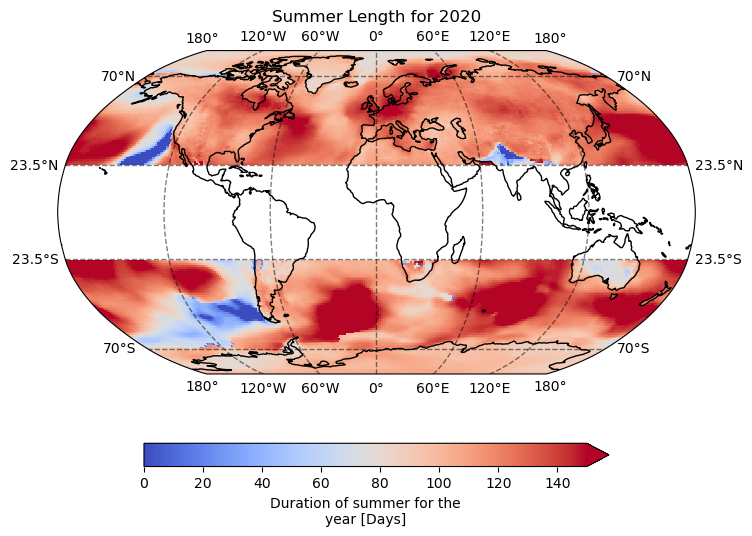

Time for 2020 :1.9952743166666667 min


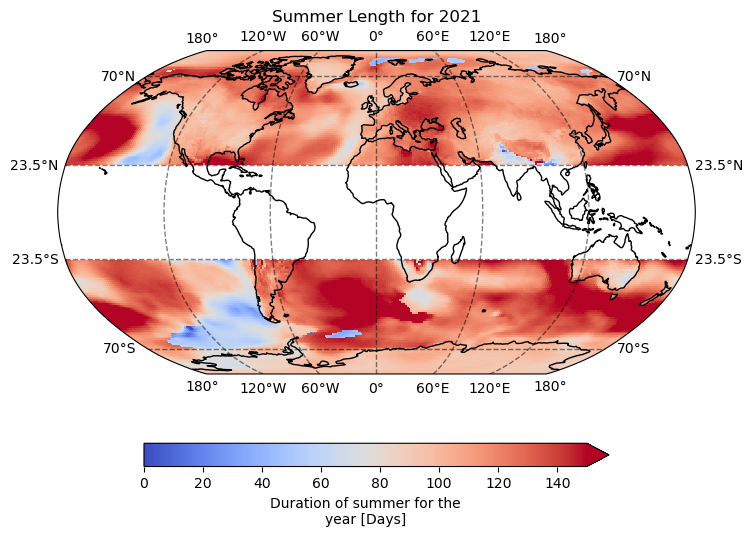

Time for 2021 :1.9954010999999998 min


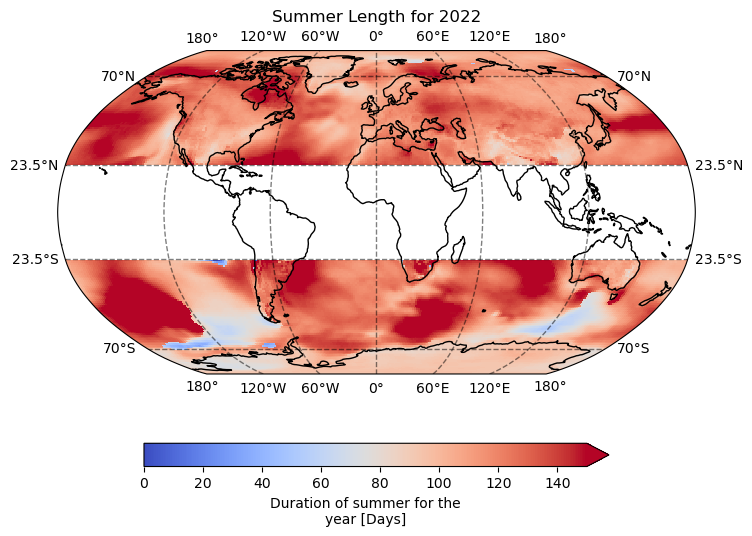

Time for 2022 :2.0619624333333335 min


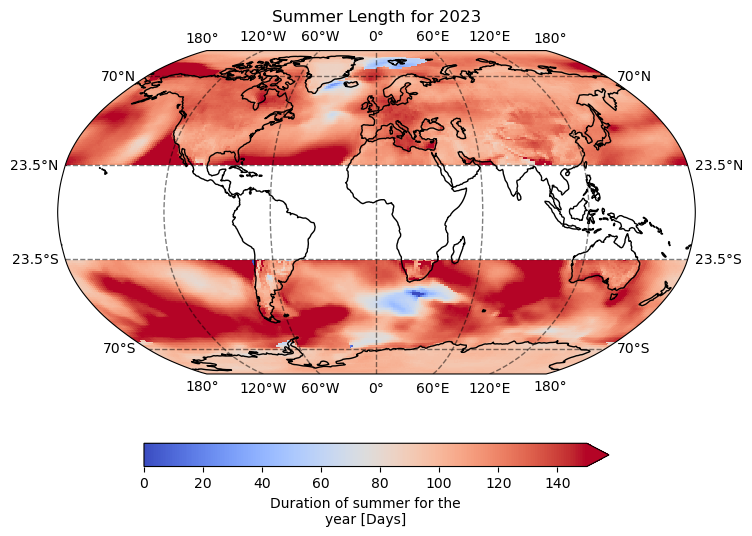

Time for 2023 :1.9997099666666667 min
CPU times: user 1h 6min 58s, sys: 45.2 s, total: 1h 7min 43s
Wall time: 1h 9min 12s


In [61]:
%%time

# Runtime: 2 min for 1 yr

# loop thru the years in the defined array above
for input_year in process_yrs:

    start = dt.now()

    ds = ds_cesm2.sel(time = str(input_year))

    dsnext = ds_cesm2.sel(time = str(input_year+1))

    # load into memory to speed up the summer stats processing
    ds.load()
    dsnext.load()

    # empty data arrays for summer stats
    summerlength = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                coords=[loop_lats, loop_lons], 
                                dims=['lat','lon'])
    summerstart = xr.DataArray(np.zeros((num_lat,num_lon)), 
                               coords=[loop_lats, loop_lons], 
                               dims=['lat','lon'])
    summerend = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summermax = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summerheat = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summerrmse = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summerr2 = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summermean = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summermeanhs = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    
    # add attributes
    summerstart.attrs["long_name"] = "Start day of summer for the year (DOY in [1,365])"
    summerstart.attrs["units"] = "Day of year"
    
    summerend.attrs["long_name"] = "Last day of summer for the year (DOY in [1,365])"
    summerend.attrs["units"] = "Day of year"
    
    summerlength.attrs["long_name"] = "Duration of summer for the year"
    summerlength.attrs["units"] = "Days"
    
    summermax.attrs["long_name"] = "Day of max mean temp during summer for the year"
    summermax.attrs["units"] = "Day of year"
    
    summerheat.attrs["long_name"] = "Accumulated heat during summer for the year"
    summerheat.attrs["units"] = "Degree-Days"
    
    summerrmse.attrs["long_name"] = "Root mean squared error of Fourier fit"
    summerrmse.attrs["units"] = "Degrees [K]"
    
    summerr2.attrs["long_name"] = "Coefficient of determination (R-squared) of Fourier fit [NOT USED]"
    summerr2.attrs["units"] = "Variance explained"

    summermean.attrs["long_name"] = "Mean temperature during the summer period"
    summermean.attrs["units"] = "Degrees [K]"

    summermeanhs.attrs["long_name"] = "Mean HS temperature during the summer period"
    summermeanhs.attrs["units"] = "Degrees [K]"

    ## now that I've added RMSE and R^2 - these loops take ~27 min with heat and tmax

    # loop through all of the lat,lon of interest
    for input_lat in loop_lats:
        for input_lon in loop_lons:
            # get threshold from c_75 - using closest location since not same grid as GFDL-ESM4
            thresh = c_75_cesm.sel(lat=input_lat,lon=input_lon, method='nearest')
    
            # all the temps for that grid cell over time for this year and next (for SH)
            curr = ds.tas.sel(lat=input_lat,lon=input_lon) 
            nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon)
    
            # build summer stats for the grid cell and produce the plot if desired (currently False)
            start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True)
            
            # xarray requires strange indexing in order to replace values by coordinate
            summerstart.loc[input_lat, input_lon] = start_day
            summerend.loc[input_lat, input_lon] = last_day
            summermax.loc[input_lat, input_lon] = day_of_max
            summerheat.loc[input_lat, input_lon] = acc_heat
            summerlength.loc[input_lat, input_lon] = summer_length
            summerrmse.loc[input_lat, input_lon] = rmse
            summerr2.loc[input_lat, input_lon] = r2
            summermean.loc[input_lat, input_lon] = mean_temp
            summermeanhs.loc[input_lat, input_lon] = mean_hs
            

    # save it out
    sum_ds = xr.Dataset(data_vars={'SummerStart':summerstart,
                               'SummerEnd':summerend,
                               'SummerTmax':summermax,
                               'SummerHeat':summerheat,
                               'SummerLength':summerlength,
                               'SummerRMSE':summerrmse,
                               'SummerR2':summerr2,
                                'SummerMeanT':summermean,
                                   'SummerMeanHS':summermeanhs})
    output_path = '../../../Data/CMIP6/CESM2/Summers/'+str(input_year)+'_CESM2_r1i1p1f1_summer_stats.nc'
    sum_ds.to_netcdf(output_path)

    # plots for the year
    fig = plt.figure(figsize=(12,6))

    # assign axis and def projection to use
    ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))
    
    # add coastlines and grid
    ax.coastlines()
    ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([-70, -23.5, 23.5, 70]), linestyle='--')
    
    sum_ds.SummerLength.where((sum_ds.lat >= 23.5) | (sum_ds.lat <= -23.5)).plot(
        ax=ax,
        transform=ccrs.PlateCarree(), # assign map projection
        vmin=0,
        vmax=150, 
        cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
        cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
    )
    
    plt.title("Summer Length for "+str(input_year))#+" using 1961-1990 baseline")
    #plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
    plt.show()

    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(input_year)+" :"+str(elapsed)+" min")

## CanESM5 data

#### Load baseline 75% percentile values from CanESM5 historical data per grid cell
- prior use of ERA5 baseline showed bias especially for CanESM data

In [25]:
# get baseline
file_path = '../../../Data/CMIP6/CanESM5/FixedCoords/baseline/computed_1961-1990-full_75th.nc'
c_75_canesm = xr.open_dataarray(file_path)
c_75_canesm.values


array([[241.00008774, 241.21955109, 241.41810226, ..., 240.23161697,
        240.49313354, 240.73985672],
       [253.62111282, 254.04934311, 254.46363449, ..., 252.03792953,
        252.61951065, 253.14171219],
       [259.2420578 , 259.37942505, 259.56554413, ..., 259.14061737,
        259.20709991, 259.18371582],
       ...,
       [269.58872223, 269.48653412, 269.49753571, ..., 269.65457916,
        269.64626312, 269.58562469],
       [268.96660614, 268.94041443, 268.94393921, ..., 269.0973587 ,
        269.05638885, 268.99520111],
       [268.73603058, 268.69161224, 268.69973755, ..., 268.81445312,
        268.789505  , 268.75492859]], shape=(64, 128))

In [26]:
file_path = '../../../Data/CMIP6/CanESM5/FixedCoords/*.nc'
#file_path = '../../../Data/CMIP6/GFDL-ESM4/tas_day_GFDL-ESM4_ssp245_r1i1p1f1_gr1_20150101-20241231.nc'

ds_canesm5 = xr.open_mfdataset(file_path)

In [27]:
ds_canesm5

<xarray.Dataset> Size: 1GB
Dimensions:    (time: 40515, bnds: 2, lon: 128, lat: 64)
Coordinates:
  * time       (time) object 324kB 1990-01-01 12:00:00 ... 2100-12-31 12:00:00
  * lon        (lon) float64 1kB -180.0 -177.2 -174.4 ... 171.6 174.4 177.2
  * lat        (lat) float64 512B -87.86 -85.1 -82.31 ... 82.31 85.1 87.86
    height     float64 8B 2.0
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) object 648kB dask.array<chunksize=(1, 2), meta=np.ndarray>
    lon_bnds   (time, lon, bnds) float64 83MB dask.array<chunksize=(3650, 128, 2), meta=np.ndarray>
    lat_bnds   (time, lat, bnds) float64 41MB dask.array<chunksize=(3650, 64, 2), meta=np.ndarray>
    tas        (time, lat, lon) float32 1GB dask.array<chunksize=(1, 64, 128), meta=np.ndarray>
Attributes: (12/55)
    CDI:                         Climate Data Interface version 2.5.0 (https:...
    Conventions:                 CF-1.7 CMIP-6.2
    source:                      CanESM5 (2019): \naerosol: interactive\natmo...
    institution:                 Canadian Centre for Climate Modelling and An...
    CCCma_model_hash:            3dedf95315d603326fde4f5340dc0519d80d10c0
    CCCma_parent_runid:          rc3-pictrl
    ...                          ...
    variable_id:                 tas
    variant_label:               r1i1p1f1
    version:                     v20190429
    license:                     CMIP6 model data produced by The Government ...
    cmor_version:                3.4.0
    CDO:                         Climate Data Operators version 2.5.0 (https:...

In [6]:
#ds_canesm5.tas.values

#### update time variable

In [28]:
ds_canesm5['time'] = ds_canesm5.indexes['time'].to_datetimeindex()
ds_canesm5

<xarray.Dataset> Size: 1GB
Dimensions:    (time: 40515, bnds: 2, lon: 128, lat: 64)
Coordinates:
  * time       (time) datetime64[ns] 324kB 1990-01-01T12:00:00 ... 2100-12-31...
  * lon        (lon) float64 1kB -180.0 -177.2 -174.4 ... 171.6 174.4 177.2
  * lat        (lat) float64 512B -87.86 -85.1 -82.31 ... 82.31 85.1 87.86
    height     float64 8B 2.0
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) object 648kB dask.array<chunksize=(1, 2), meta=np.ndarray>
    lon_bnds   (time, lon, bnds) float64 83MB dask.array<chunksize=(3650, 128, 2), meta=np.ndarray>
    lat_bnds   (time, lat, bnds) float64 41MB dask.array<chunksize=(3650, 64, 2), meta=np.ndarray>
    tas        (time, lat, lon) float32 1GB dask.array<chunksize=(1, 64, 128), meta=np.ndarray>
Attributes: (12/55)
    CDI:                         Climate Data Interface version 2.5.0 (https:...
    Conventions:                 CF-1.7 CMIP-6.2
    source:                      CanESM5 (2019): \naerosol: interactive\natmo...
    institution:                 Canadian Centre for Climate Modelling and An...
    CCCma_model_hash:            3dedf95315d603326fde4f5340dc0519d80d10c0
    CCCma_parent_runid:          rc3-pictrl
    ...                          ...
    variable_id:                 tas
    variant_label:               r1i1p1f1
    version:                     v20190429
    license:                     CMIP6 model data produced by The Government ...
    cmor_version:                3.4.0
    CDO:                         Climate Data Operators version 2.5.0 (https:...

### Test for Vancouver 2000 - nearest grid cell

In [29]:
#test for Vancouver
input_lat = 49.246
input_lon = -123.116

thresh = c_75_canesm.sel(lat=input_lat, lon=input_lon, method="nearest")
thresh

<xarray.DataArray 'tas' ()> Size: 8B
array(285.922417)
Coordinates:
    lon       float64 8B -123.8
    lat       float64 8B 48.84
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [30]:
input_year = 2000

ds = ds_canesm5.sel(time = str(input_year))
curr = ds.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
dsnext = ds_canesm5.sel(time = str(input_year+1))
nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
curr, nxt

(<xarray.DataArray 'tas' (time: 365)> Size: 1kB
 dask.array<getitem, shape=(365,), dtype=float32, chunksize=(1,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 3kB 2000-01-01T12:00:00 ... 2000-12-31T12:...
     lon      float64 8B -123.8
     lat      float64 8B 48.84
     height   float64 8B 2.0
 Attributes:
     standard_name:     air_temperature
     long_name:         Near-Surface Air Temperature
     units:             K
     CDI_grid_type:     gaussian
     CDI_grid_num_LPE:  32
     comment:           near-surface (usually, 2 meter) air temperature
     original_name:     ST
     cell_methods:      area: time: mean
     cell_measures:     area: areacella
     history:           2019-05-02T08:02:00Z altered by CMOR: Treated scalar d...,
 <xarray.DataArray 'tas' (time: 365)> Size: 1kB
 dask.array<getitem, shape=(365,), dtype=float32, chunksize=(1,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 3kB 2001-01-01T12:00:00 ... 2

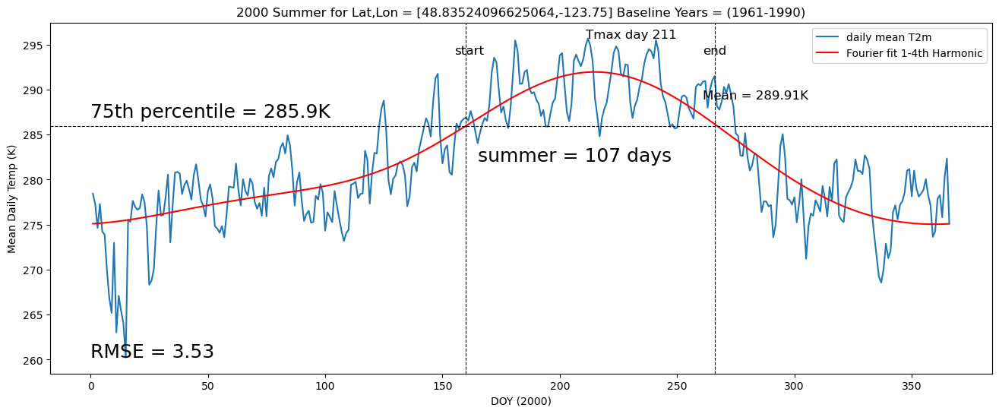

(160,
 266,
 211,
 431.8107376098633,
 107,
 3.531092882156372,
 0.0,
 289.9111022949219,
 4.451657088761465)

In [31]:
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True)
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

#### Vancouver 2023 using ssp2-4.5 data

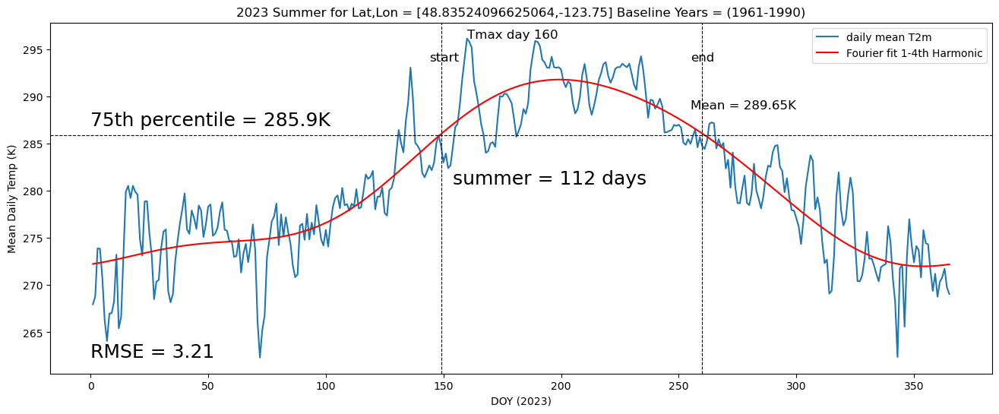

CPU times: user 1.15 s, sys: 168 ms, total: 1.32 s
Wall time: 1.25 s


(149,
 260,
 160,
 445.2743835449219,
 112,
 3.2087628841400146,
 0.0,
 289.65313720703125,
 4.8399389515752205)

In [32]:
%%time
input_year = 2023

ds = ds_canesm5.sel(time = str(input_year))
curr = ds.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
dsnext = ds_canesm5.sel(time = str(input_year+1))
nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True)
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Try Sydney Australia to test SH functioning

In [33]:
input_lat = -33 - 52/60 - 4/3600
input_lon = 151.25
thresh = c_75_canesm.sel(lat=input_lat, lon=input_lon, method="nearest")

curr = ds.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
curr, nxt

(<xarray.DataArray 'tas' (time: 365)> Size: 1kB
 dask.array<getitem, shape=(365,), dtype=float32, chunksize=(1,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 3kB 2023-01-01T12:00:00 ... 2023-12-31T12:...
     lon      float64 8B 151.9
     lat      float64 8B -34.88
     height   float64 8B 2.0
 Attributes:
     standard_name:     air_temperature
     long_name:         Near-Surface Air Temperature
     units:             K
     CDI_grid_type:     gaussian
     CDI_grid_num_LPE:  32
     comment:           near-surface (usually, 2 meter) air temperature
     original_name:     ST
     cell_methods:      area: time: mean
     cell_measures:     area: areacella
     history:           2019-05-02T08:02:00Z altered by CMOR: Treated scalar d...,
 <xarray.DataArray 'tas' (time: 365)> Size: 1kB
 dask.array<getitem, shape=(365,), dtype=float32, chunksize=(1,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 3kB 2024-01-01T12:00:00 ... 2

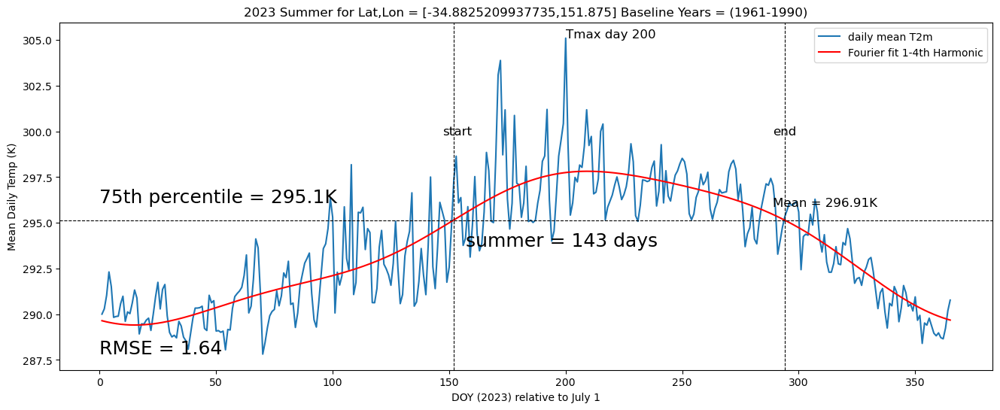

(152,
 294,
 200,
 275.2695617675781,
 143,
 1.6443194150924683,
 0.0,
 296.91259765625,
 2.313189594685525)

In [34]:
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True)
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Sydney 2070 using ssp2-4.5 data

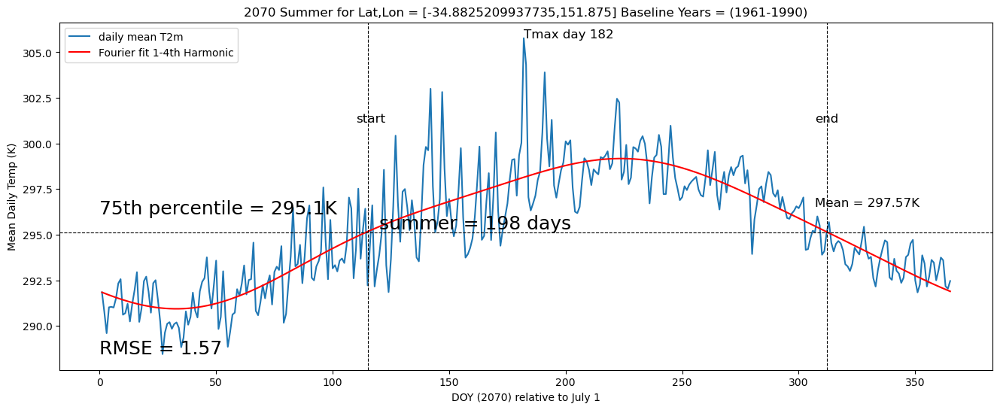

CPU times: user 1.6 s, sys: 194 ms, total: 1.79 s
Wall time: 1.68 s


(115,
 312,
 182,
 512.6148681640625,
 198,
 1.5678017139434814,
 0.0,
 297.5655822753906,
 2.980319000953841)

In [35]:
%%time
input_year = 2070

ds = ds_canesm5.sel(time = str(input_year))
curr = ds.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
dsnext = ds_canesm5.sel(time = str(input_year+1))
nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon, method="nearest")
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True)
start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

## Main Loop: loop through multiple years to generate summer stats

In [36]:
# grid parameters for looping
num_lat = ds_canesm5.lat.shape[0]
num_lon = ds_canesm5.lon.shape[0]

loop_lats = ds_canesm5.lat.values[:num_lat]
loop_lons = ds_canesm5.lon.values[:num_lon]
loop_lats, loop_lons

(array([-87.86379884, -85.09652699, -82.31291295, -79.52560657,
        -76.73689968, -73.94751515, -71.15775201, -68.36775611,
        -65.57760701, -62.7873518 , -59.99702011, -57.20663153,
        -54.41619953, -51.62573367, -48.83524097, -46.04472663,
        -43.25419467, -40.46364818, -37.67308963, -34.88252099,
        -32.09194388, -29.30135962, -26.51076933, -23.72017393,
        -20.92957425, -18.13897099, -15.34836476, -12.55775612,
         -9.76714556,  -6.97653355,  -4.18592053,  -1.39530691,
          1.39530691,   4.18592053,   6.97653355,   9.76714556,
         12.55775612,  15.34836476,  18.13897099,  20.92957425,
         23.72017393,  26.51076933,  29.30135962,  32.09194388,
         34.88252099,  37.67308963,  40.46364818,  43.25419467,
         46.04472663,  48.83524097,  51.62573367,  54.41619953,
         57.20663153,  59.99702011,  62.7873518 ,  65.57760701,
         68.36775611,  71.15775201,  73.94751515,  76.73689968,
         79.52560657,  82.31291295,  85.

### Going to go all the way to 2099

In [37]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1990, 2100,1)

process_yrs

array([1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000,
       2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011,
       2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022,
       2023, 2024, 2025, 2026, 2027, 2028, 2029, 2030, 2031, 2032, 2033,
       2034, 2035, 2036, 2037, 2038, 2039, 2040, 2041, 2042, 2043, 2044,
       2045, 2046, 2047, 2048, 2049, 2050, 2051, 2052, 2053, 2054, 2055,
       2056, 2057, 2058, 2059, 2060, 2061, 2062, 2063, 2064, 2065, 2066,
       2067, 2068, 2069, 2070, 2071, 2072, 2073, 2074, 2075, 2076, 2077,
       2078, 2079, 2080, 2081, 2082, 2083, 2084, 2085, 2086, 2087, 2088,
       2089, 2090, 2091, 2092, 2093, 2094, 2095, 2096, 2097, 2098, 2099])

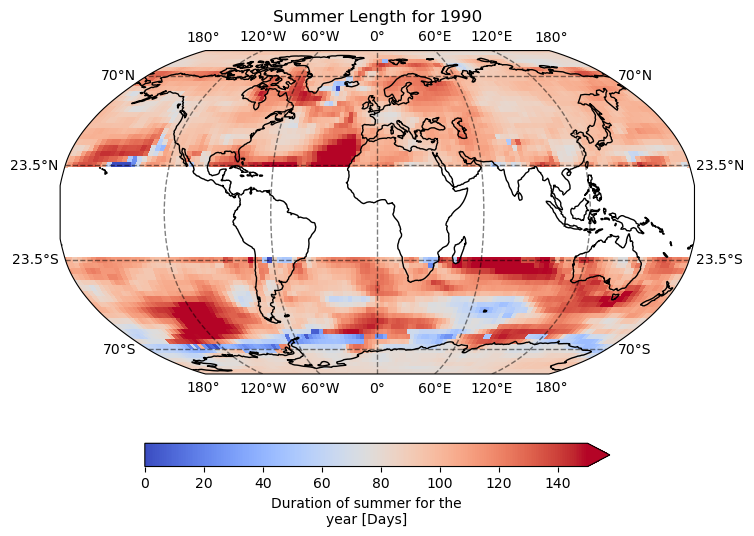

Time for 1990 :0.3221152333333333 min


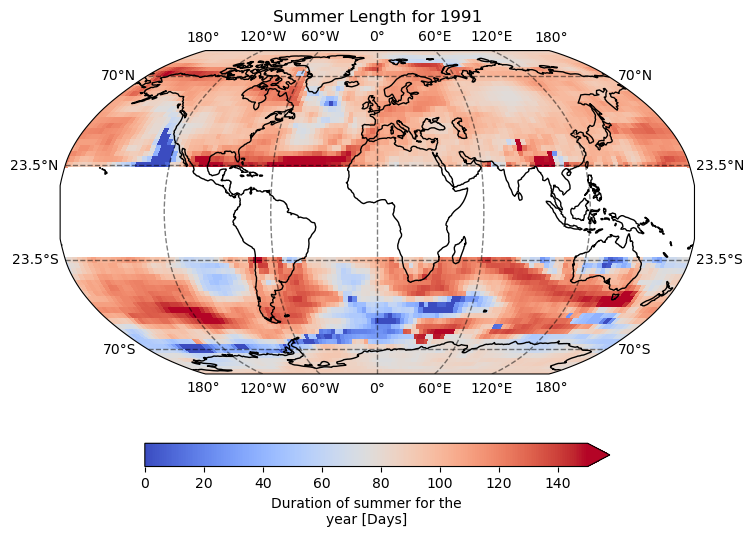

Time for 1991 :0.31945243333333334 min


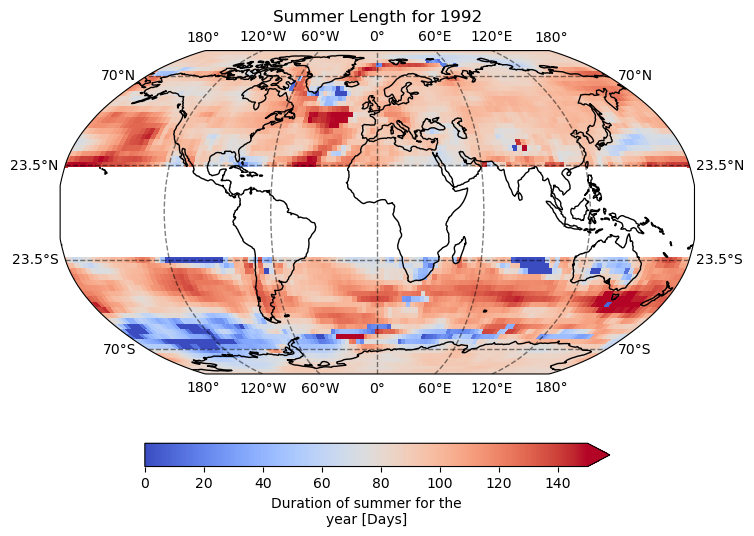

Time for 1992 :0.3236639333333333 min


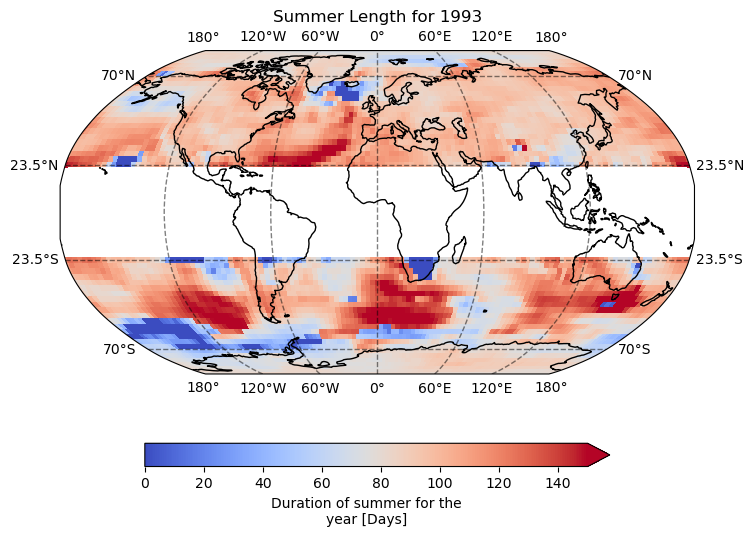

Time for 1993 :0.315239 min


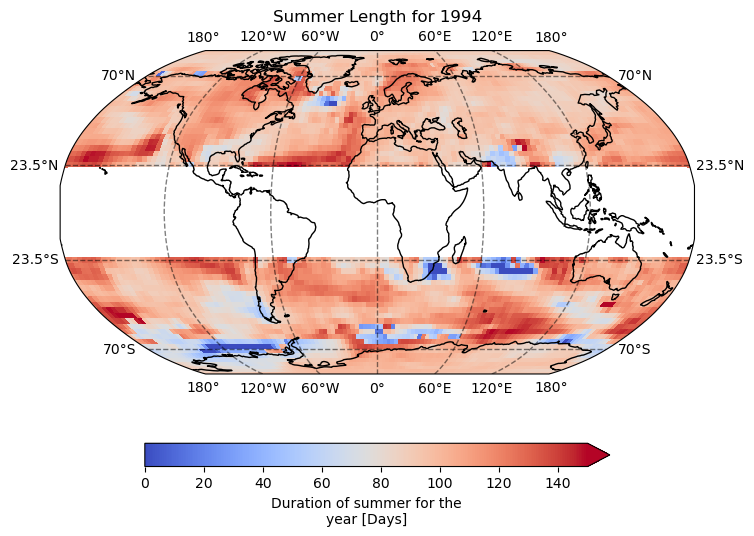

Time for 1994 :0.31611618333333336 min


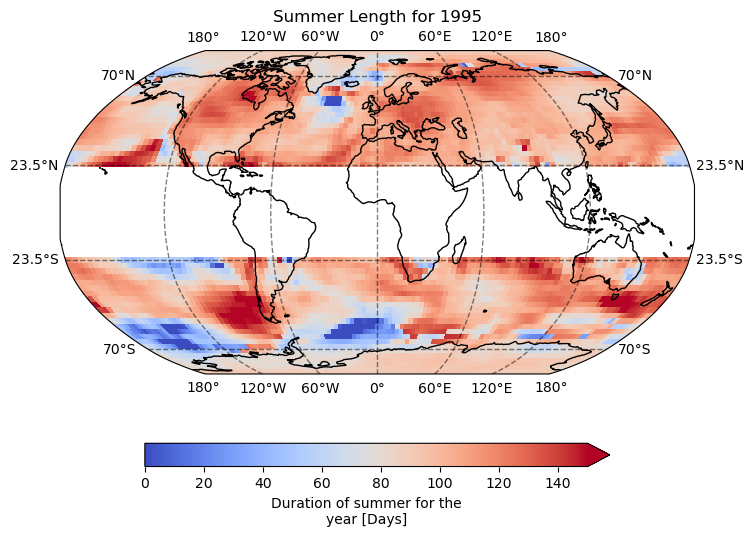

Time for 1995 :0.31546273333333336 min


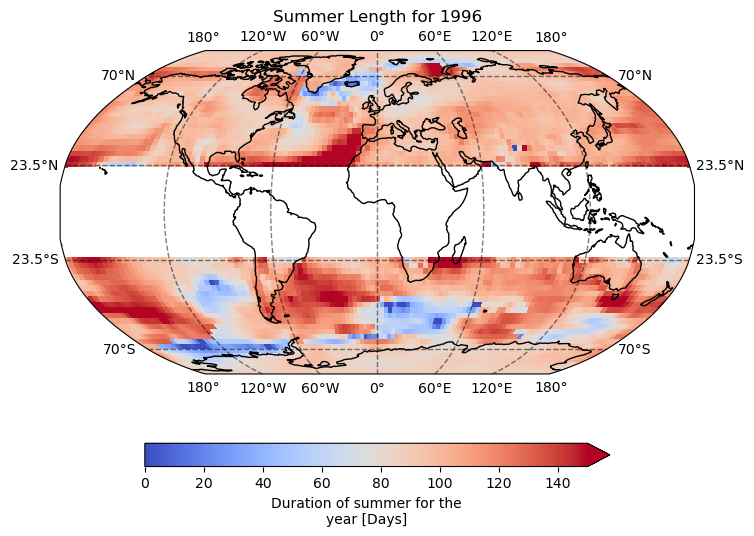

Time for 1996 :0.31690446666666666 min


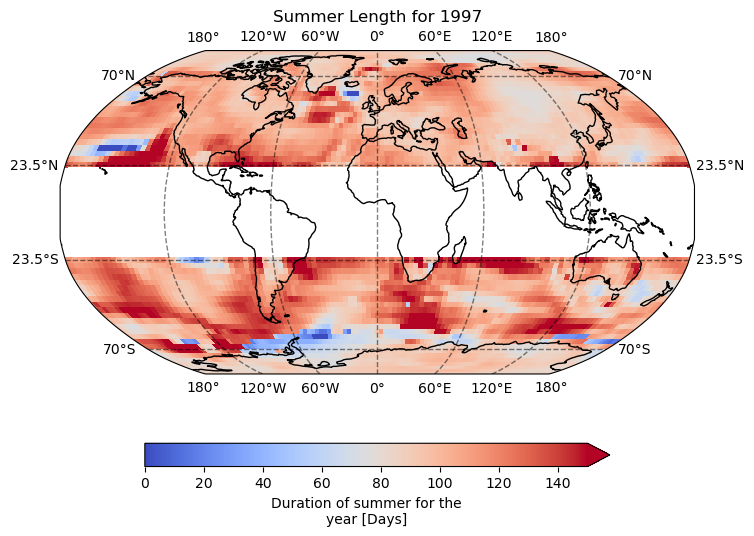

Time for 1997 :0.32319323333333333 min


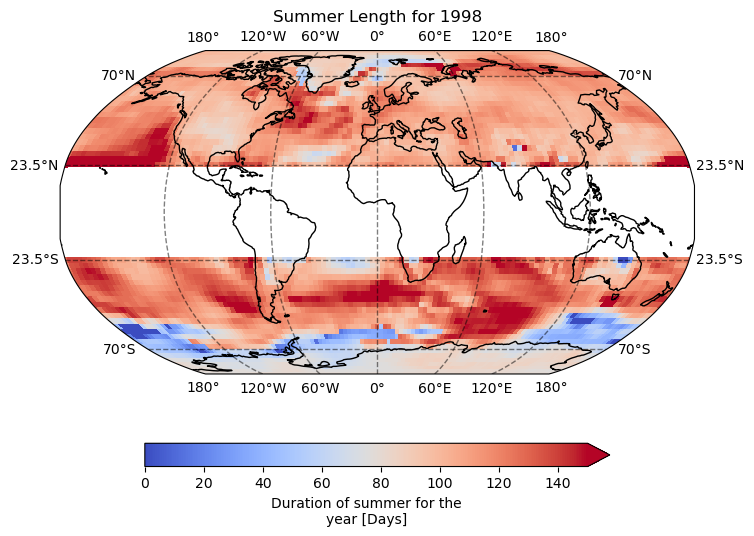

Time for 1998 :0.31979471666666665 min


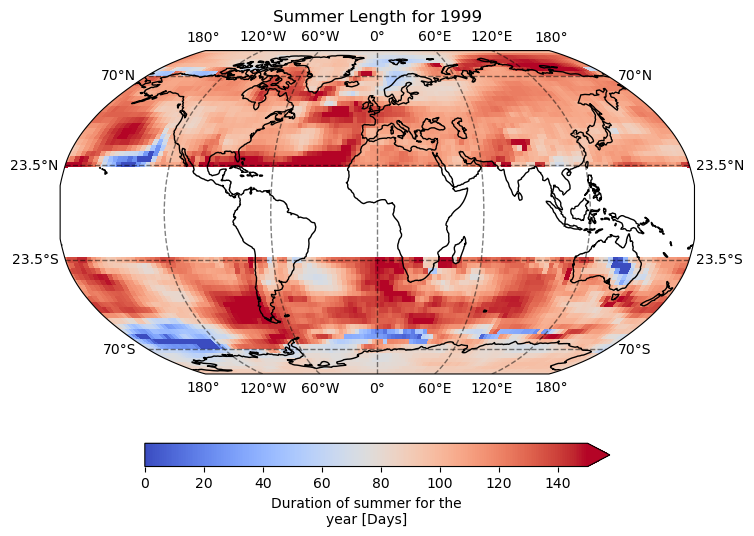

Time for 1999 :0.3152107333333333 min


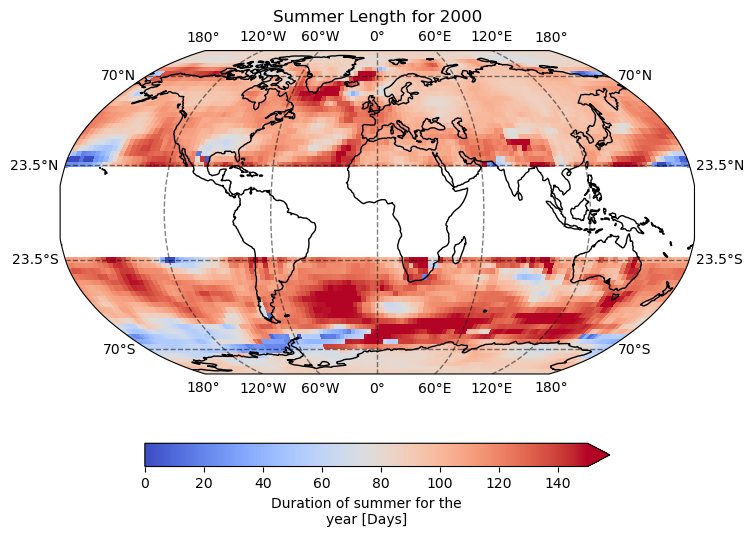

Time for 2000 :0.31065271666666666 min


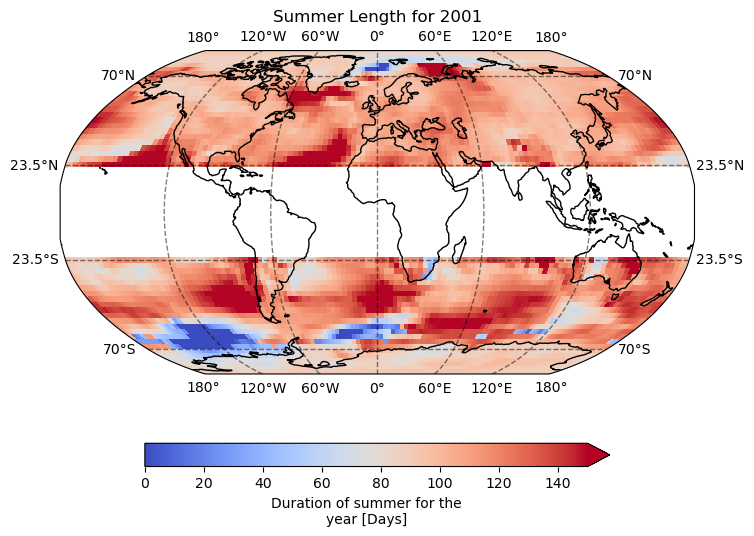

Time for 2001 :0.31538646666666664 min


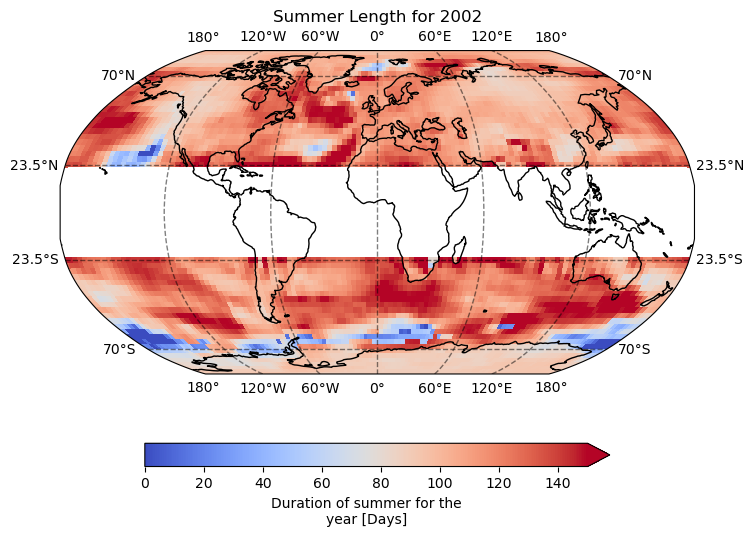

Time for 2002 :0.30770125 min


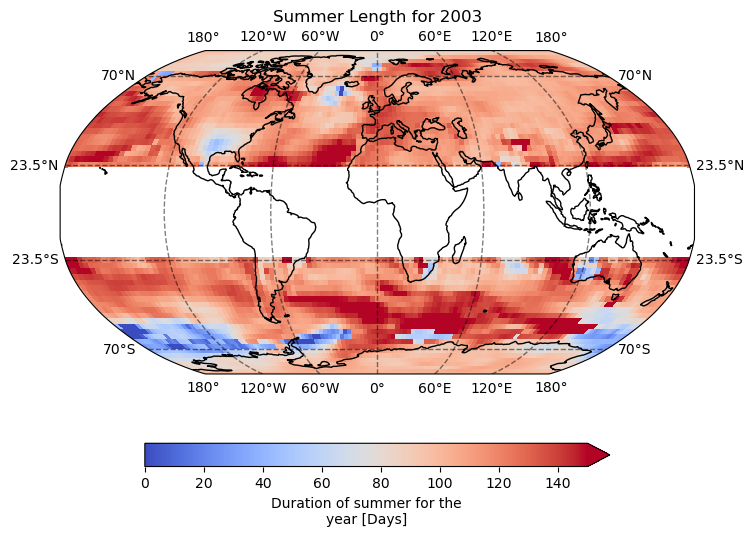

Time for 2003 :0.31050679999999997 min


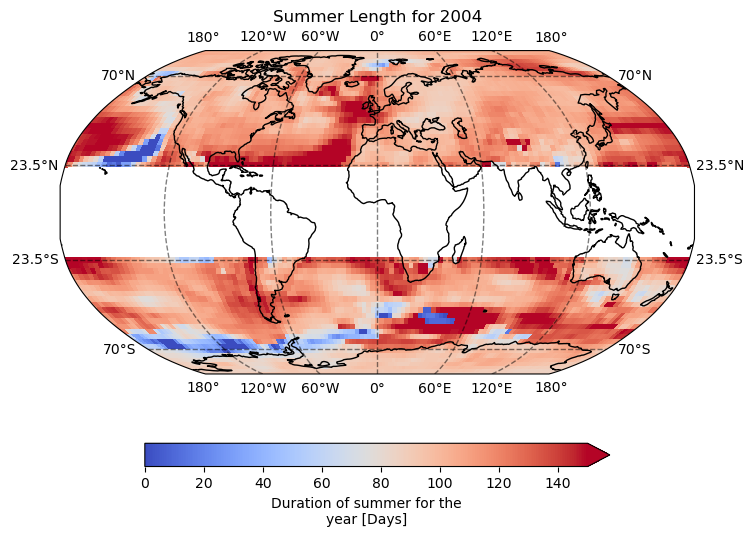

Time for 2004 :0.3108742166666667 min


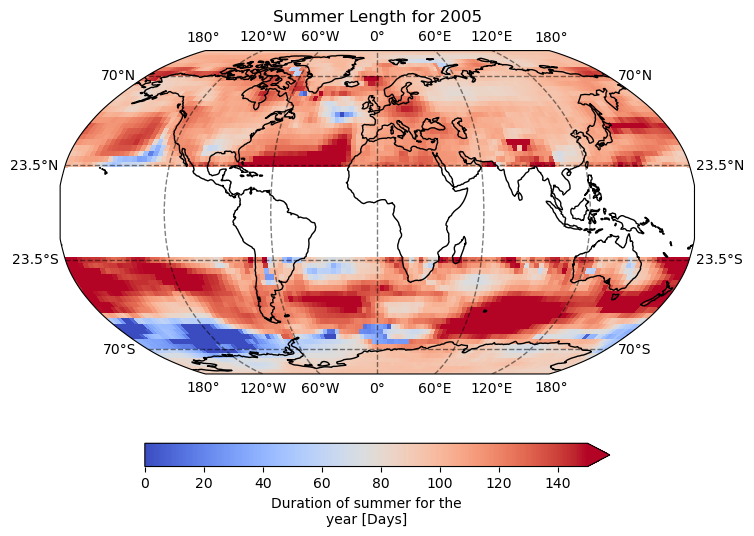

Time for 2005 :0.30677893333333334 min


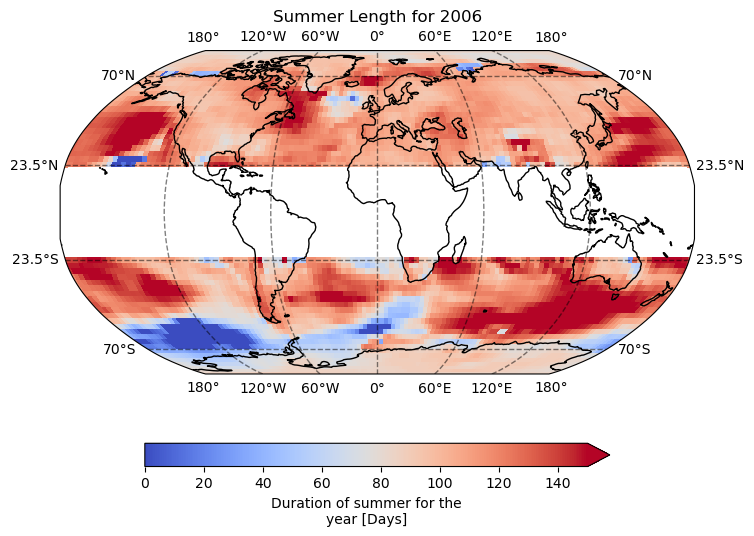

Time for 2006 :0.3042016 min


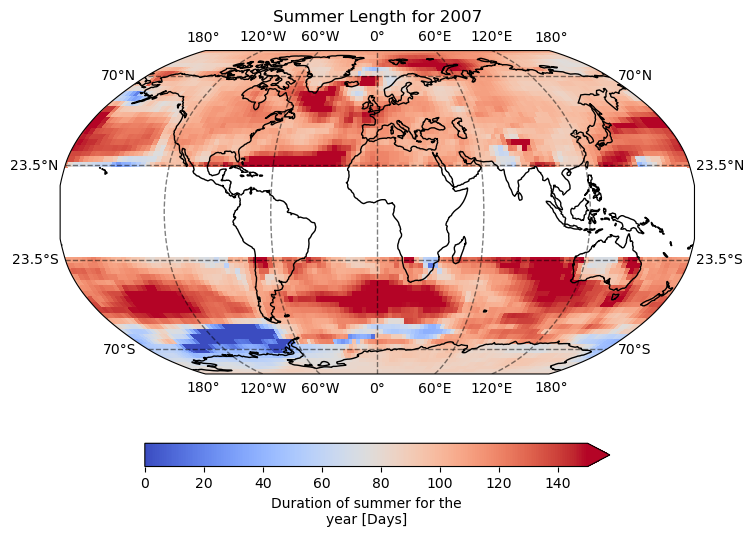

Time for 2007 :0.3132588666666667 min


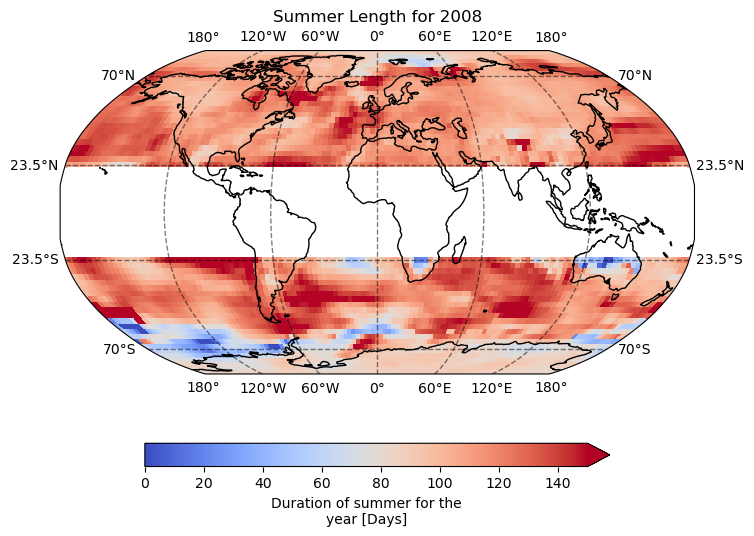

Time for 2008 :0.3126212333333333 min


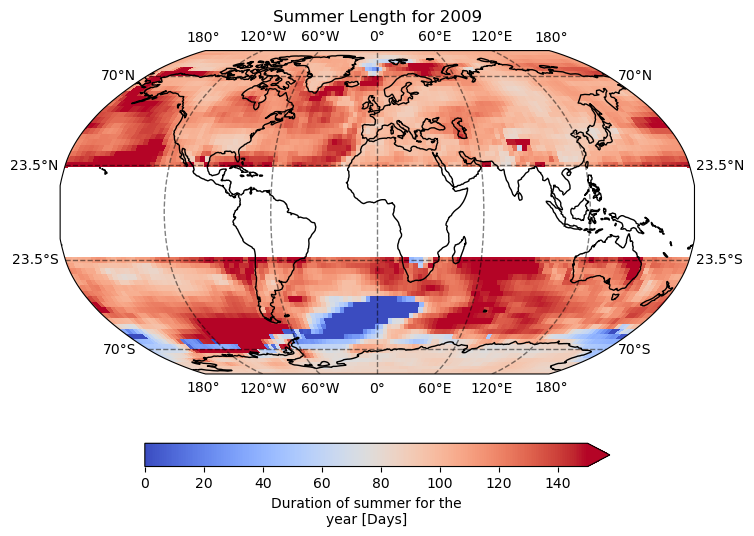

Time for 2009 :0.31539836666666665 min


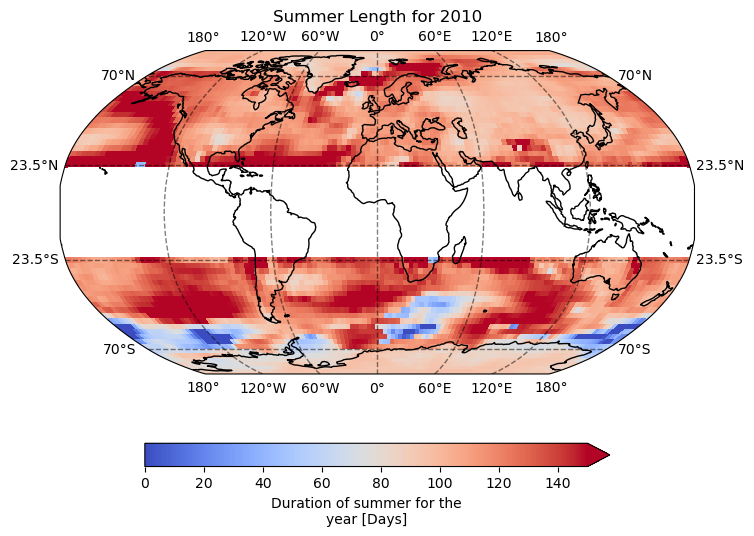

Time for 2010 :0.31208003333333334 min


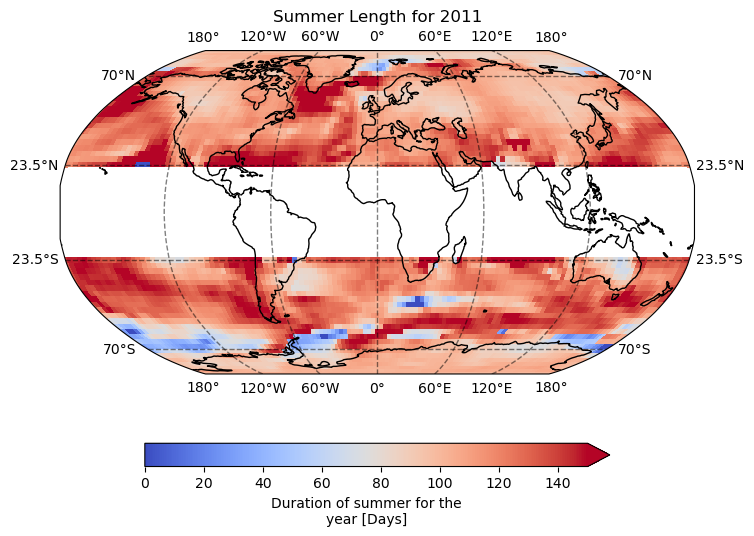

Time for 2011 :0.30699303333333333 min


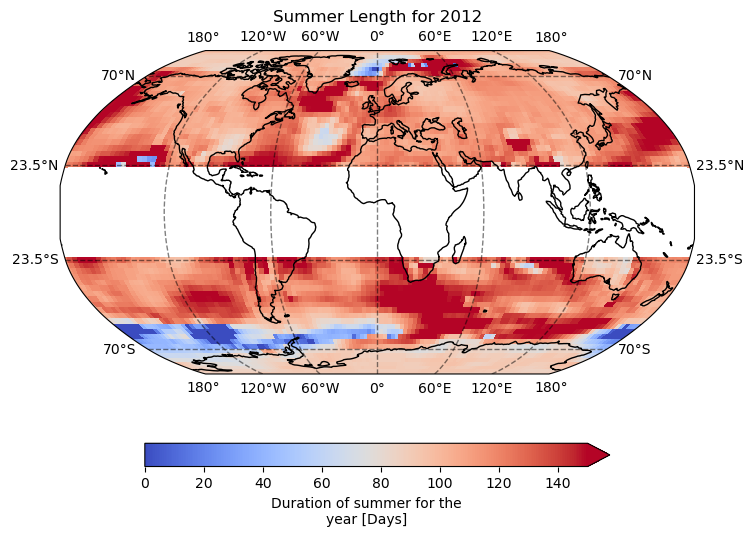

Time for 2012 :0.30251486666666666 min


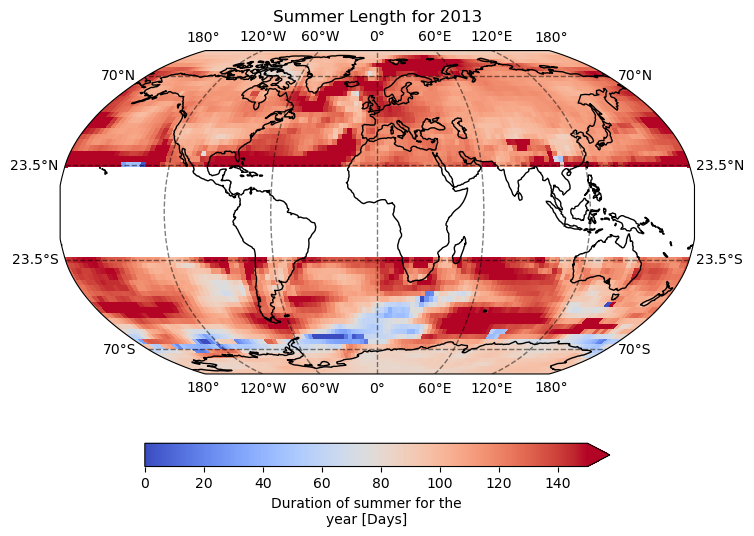

Time for 2013 :0.31992204999999996 min


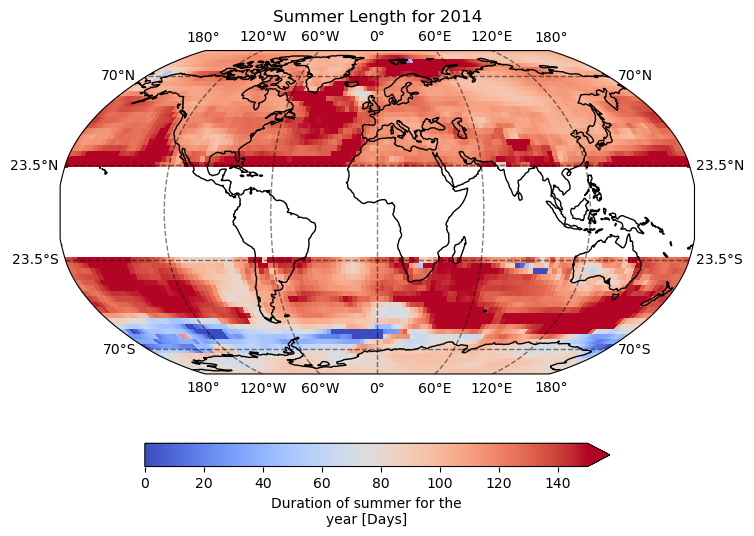

Time for 2014 :0.31820655000000003 min


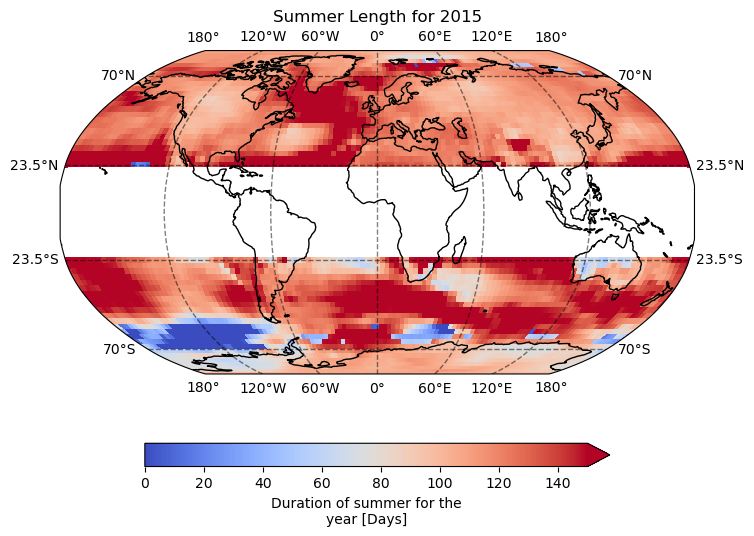

Time for 2015 :0.3088677333333333 min


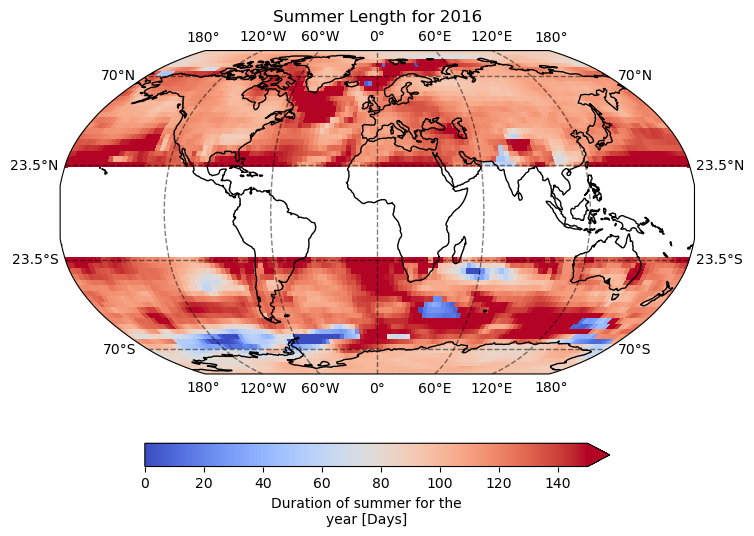

Time for 2016 :0.3135119833333333 min


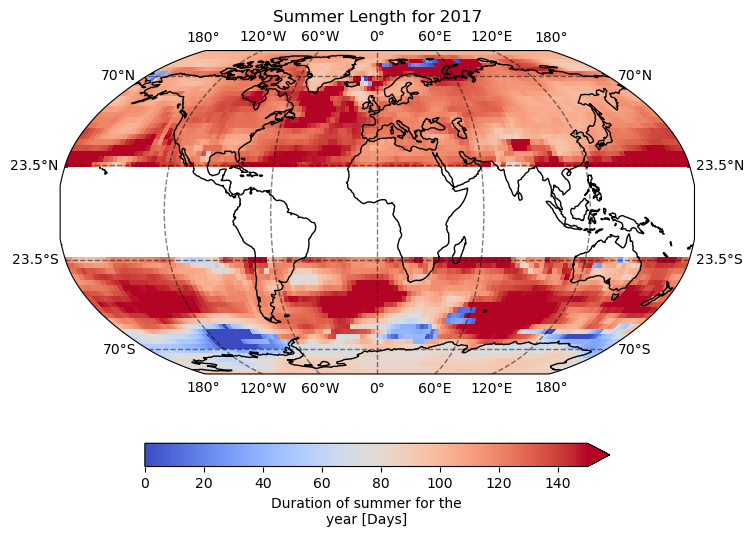

Time for 2017 :0.31563806666666666 min


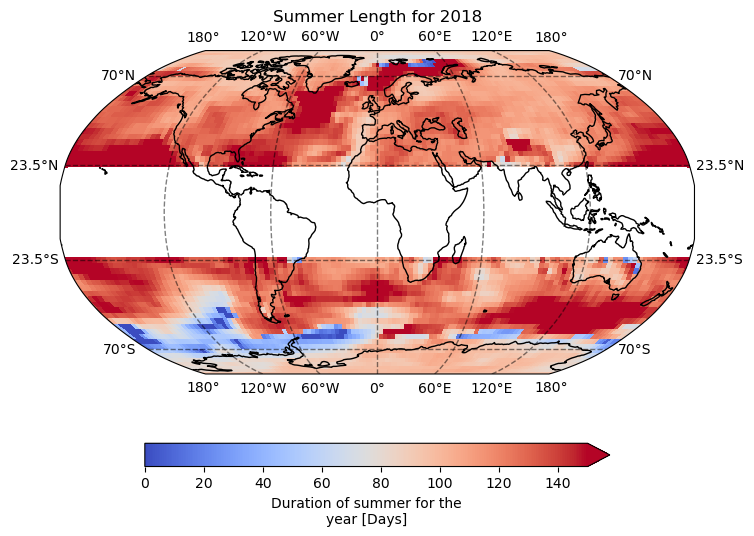

Time for 2018 :0.3192889666666667 min


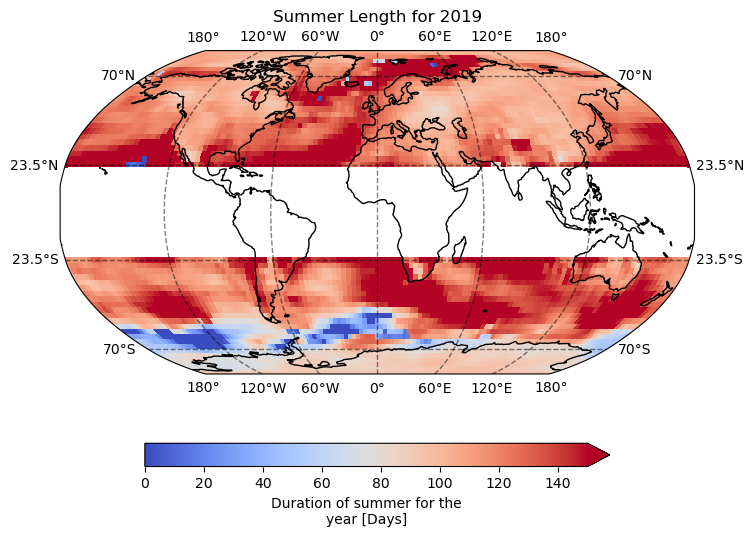

Time for 2019 :0.3138213166666667 min


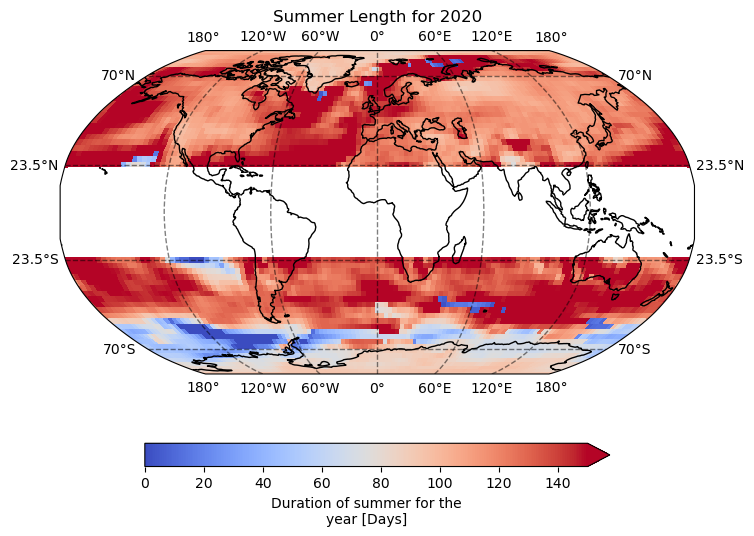

Time for 2020 :0.31312985 min


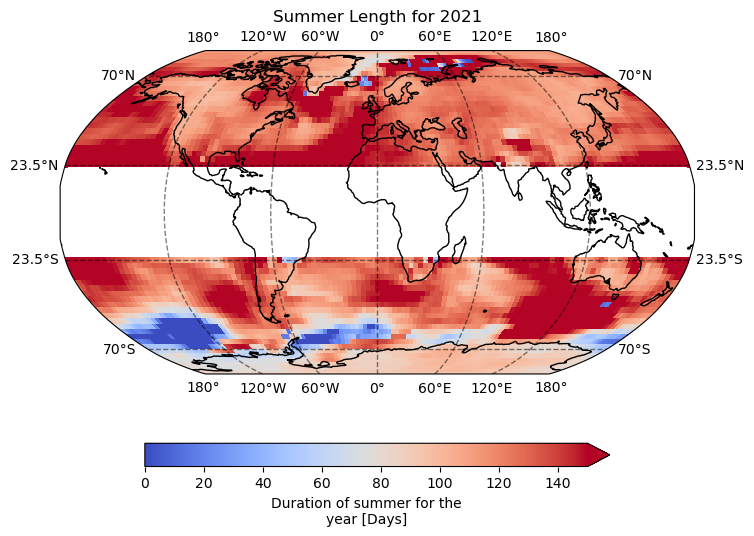

Time for 2021 :0.31420919999999997 min


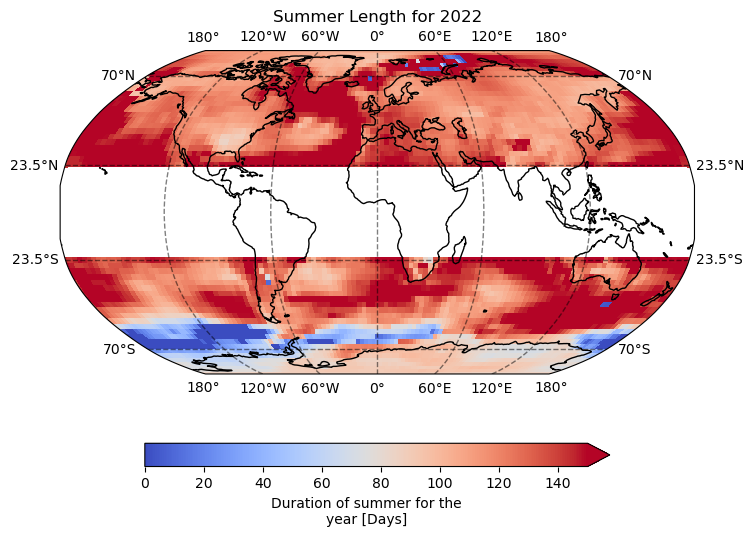

Time for 2022 :0.3111258666666667 min


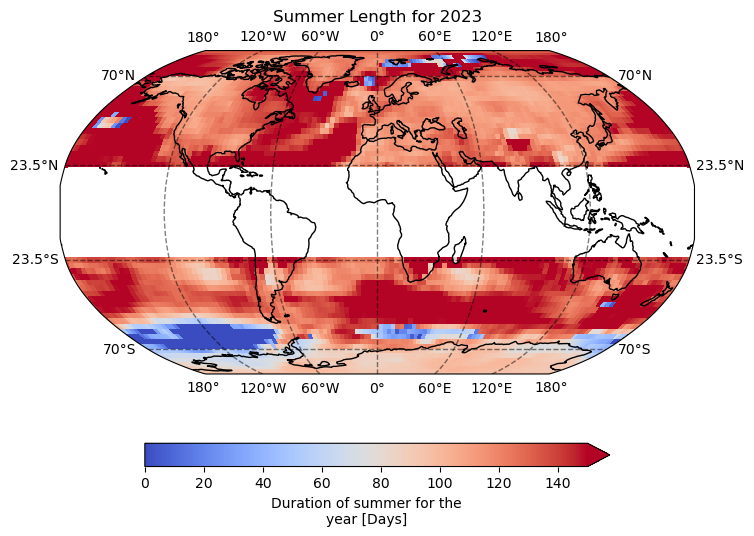

Time for 2023 :0.3054646833333334 min


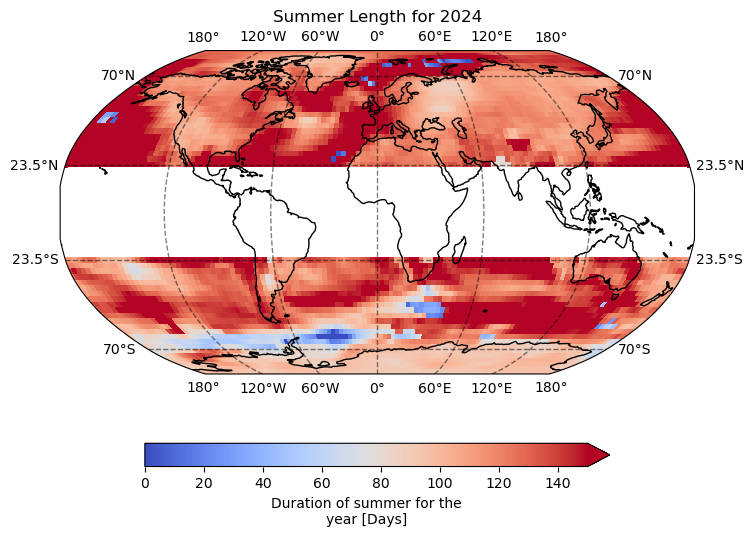

Time for 2024 :0.30905235 min


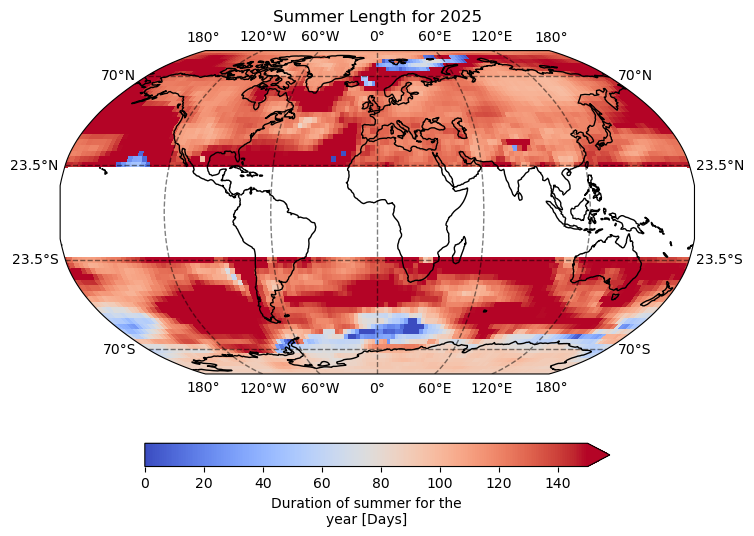

Time for 2025 :0.30772889999999997 min


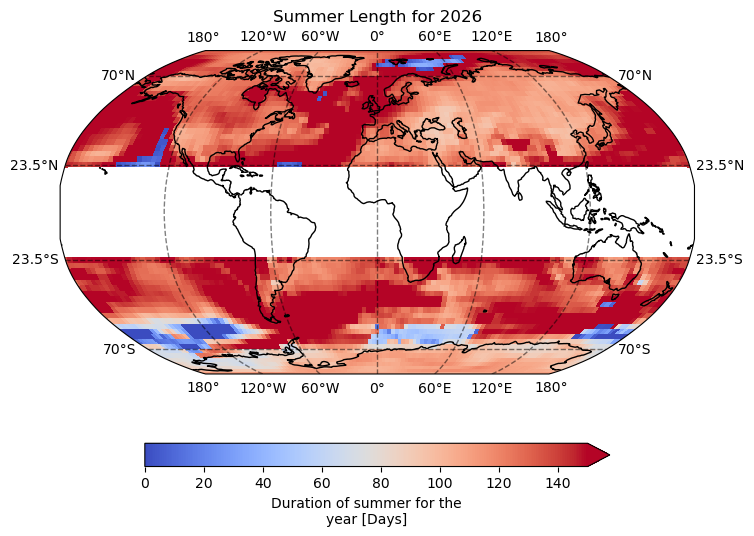

Time for 2026 :0.30861330000000003 min


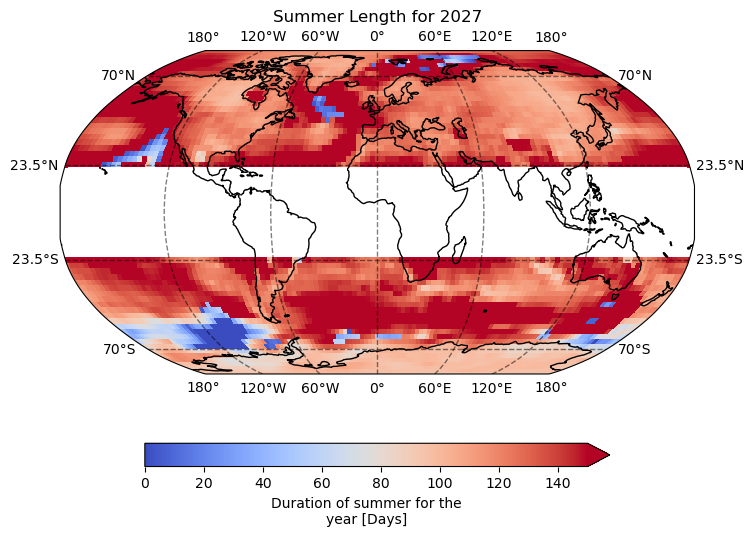

Time for 2027 :0.3084679833333333 min


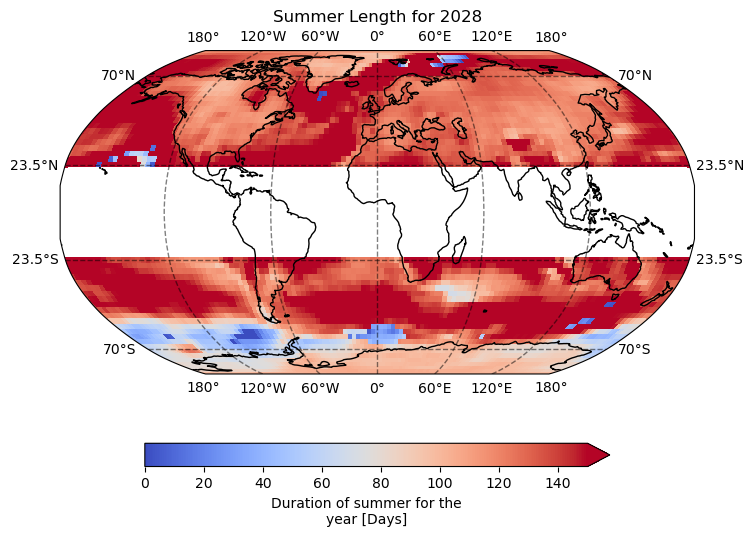

Time for 2028 :0.3094075666666667 min


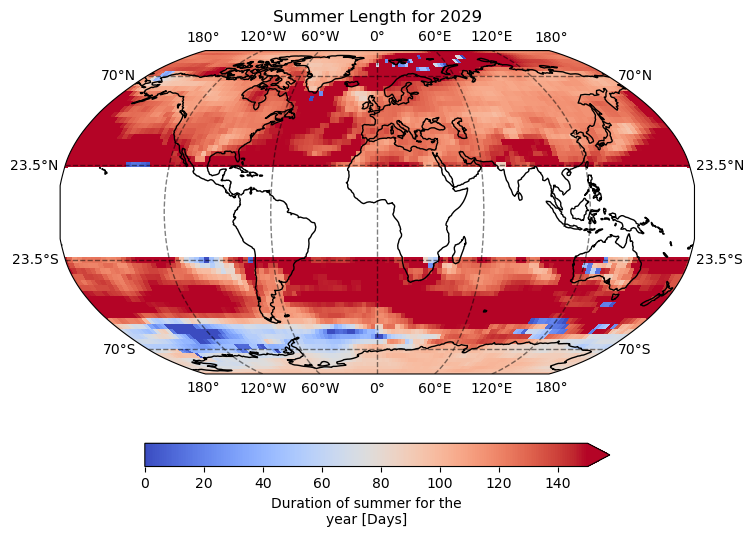

Time for 2029 :0.3101784833333333 min


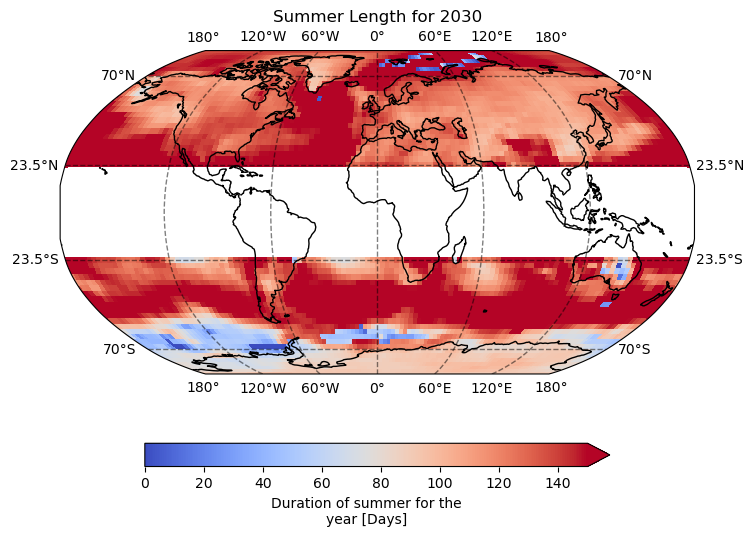

Time for 2030 :0.31002406666666665 min


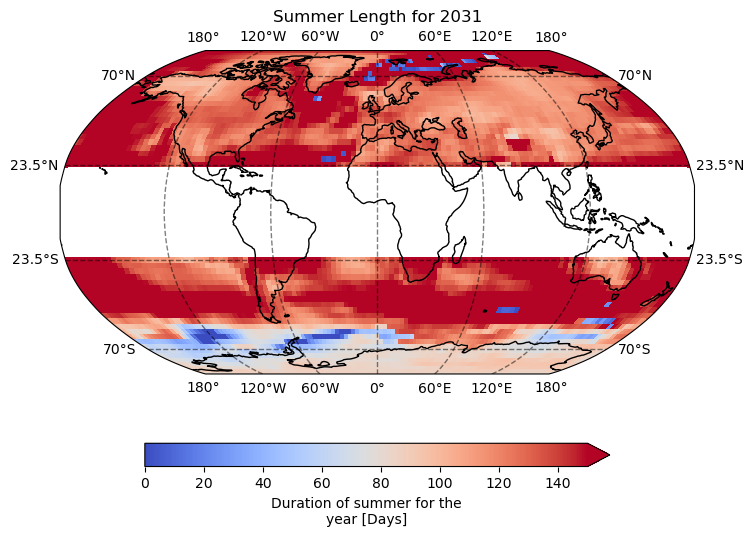

Time for 2031 :0.3147687833333333 min


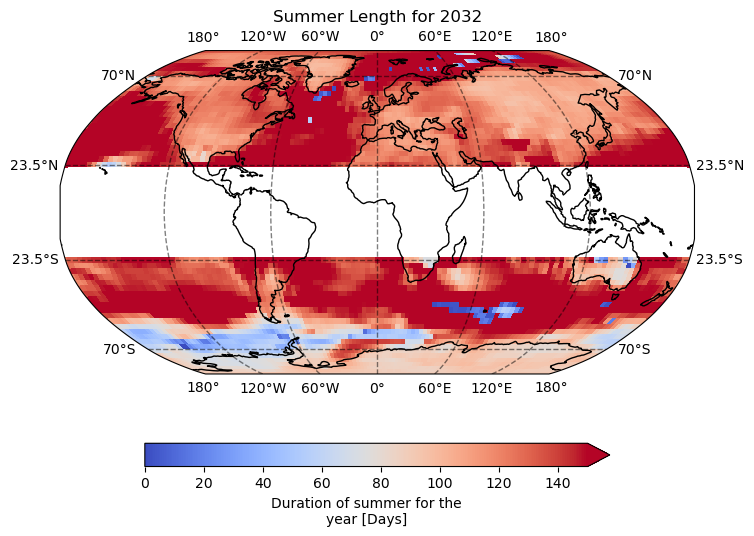

Time for 2032 :0.31108755 min


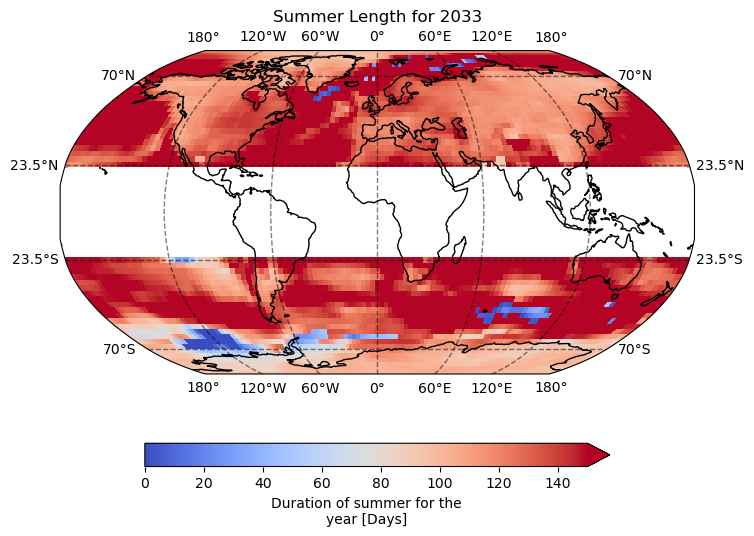

Time for 2033 :0.31617568333333335 min


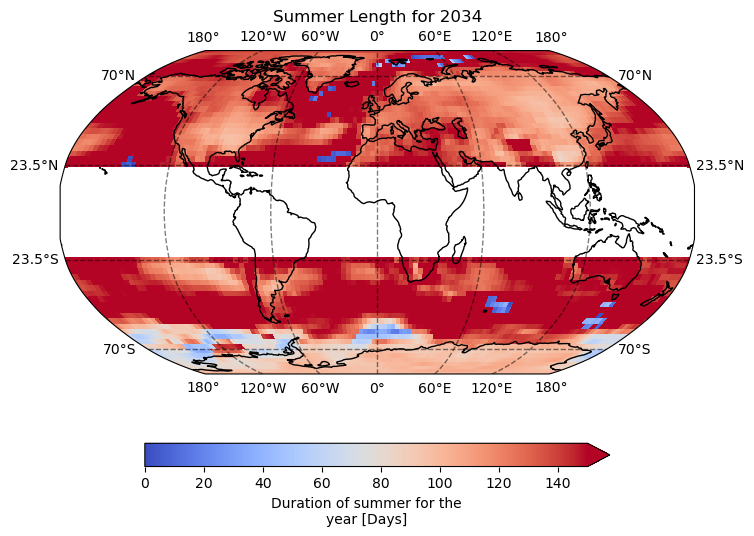

Time for 2034 :0.3139242666666667 min


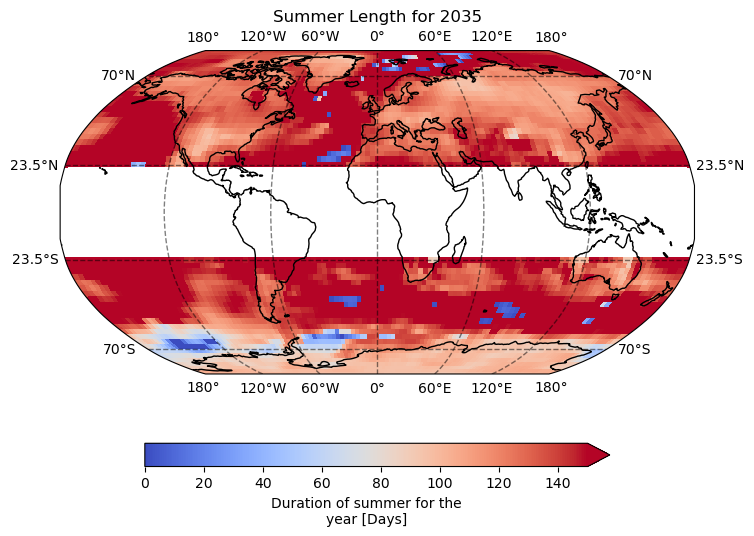

Time for 2035 :0.3138082166666667 min


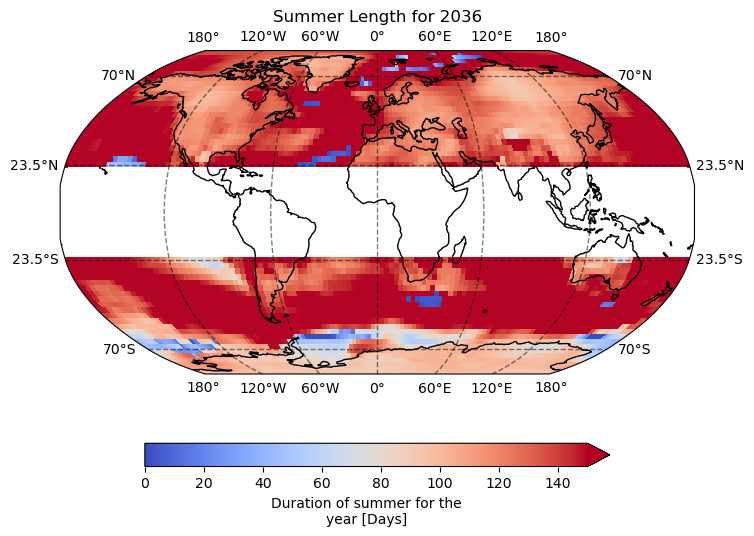

Time for 2036 :0.31224139999999995 min


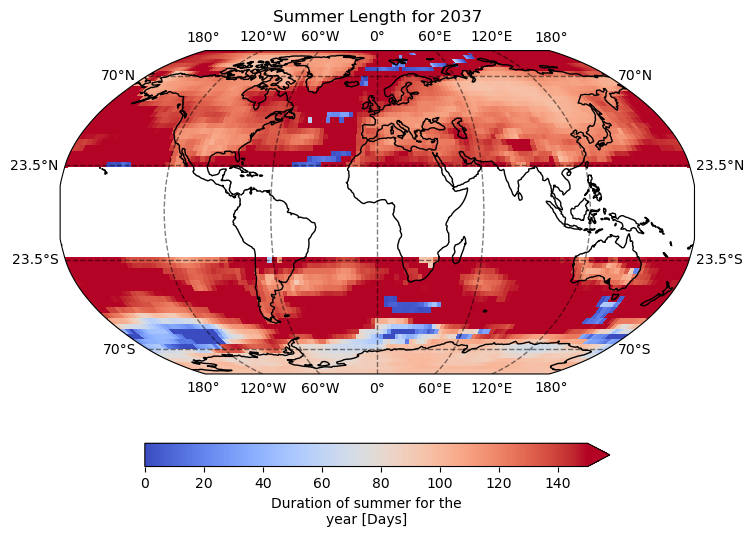

Time for 2037 :0.31419335 min


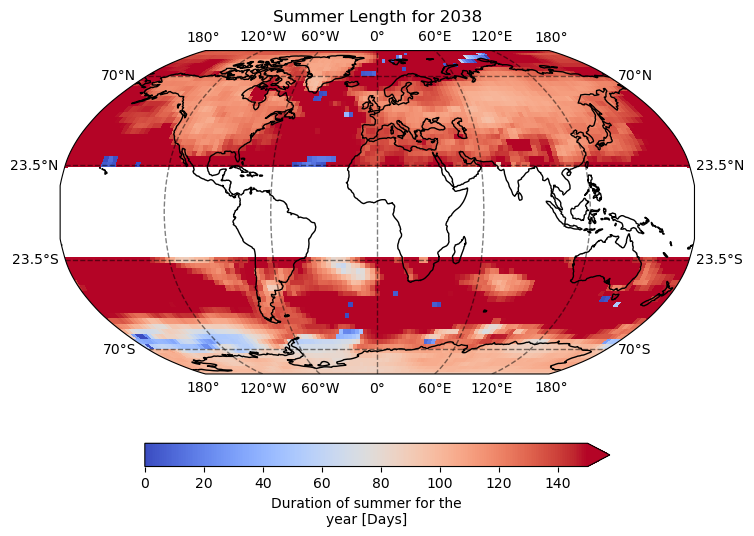

Time for 2038 :0.31061535 min


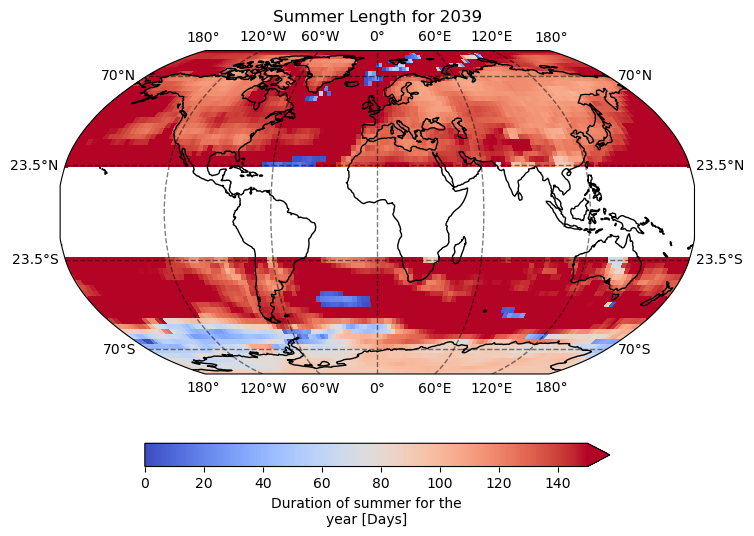

Time for 2039 :0.3165831333333333 min


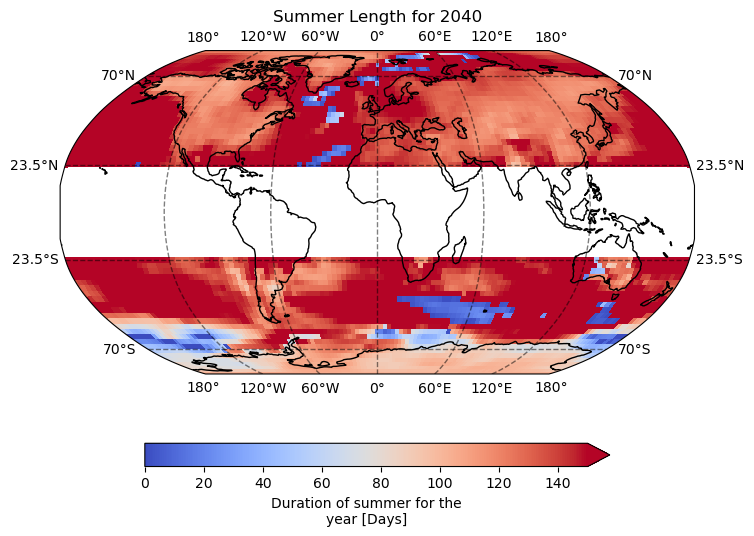

Time for 2040 :0.3106715833333333 min


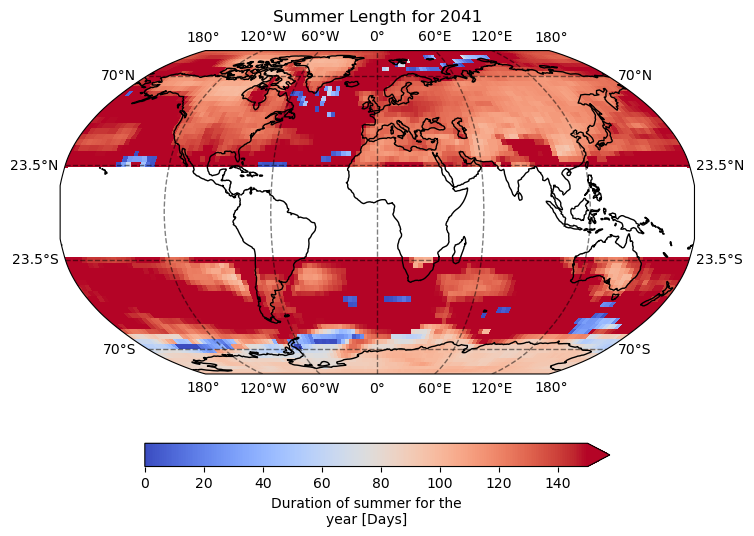

Time for 2041 :0.3154583 min


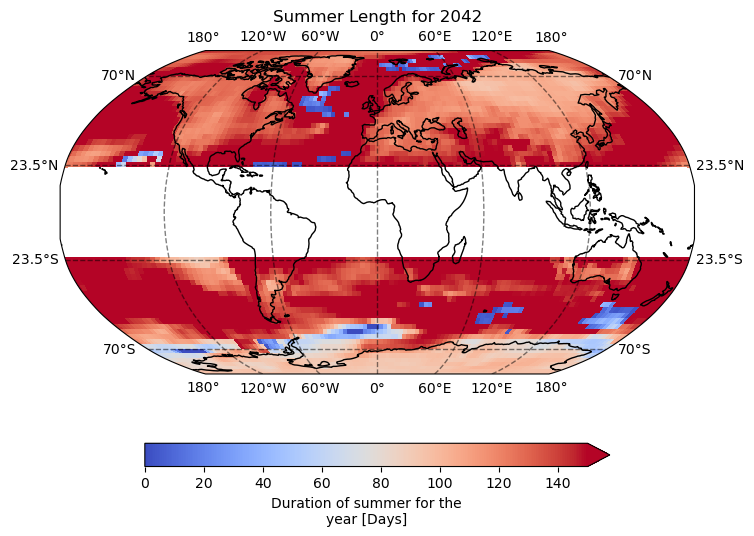

Time for 2042 :0.3108981 min


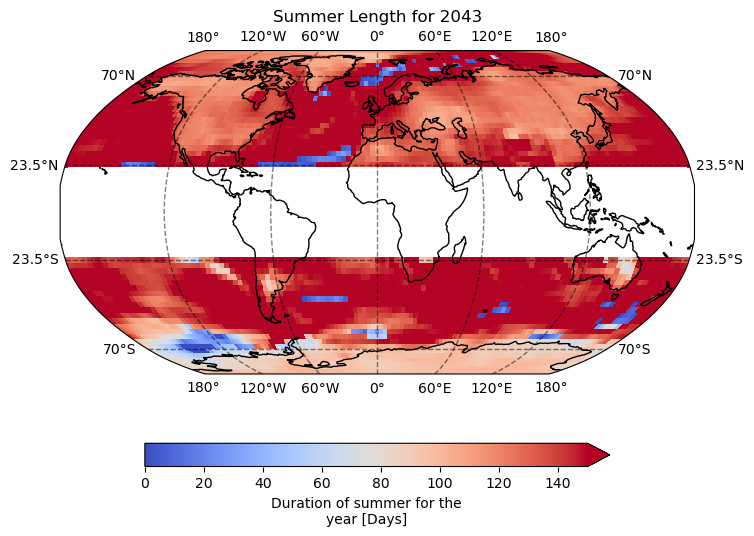

Time for 2043 :0.30991365000000004 min


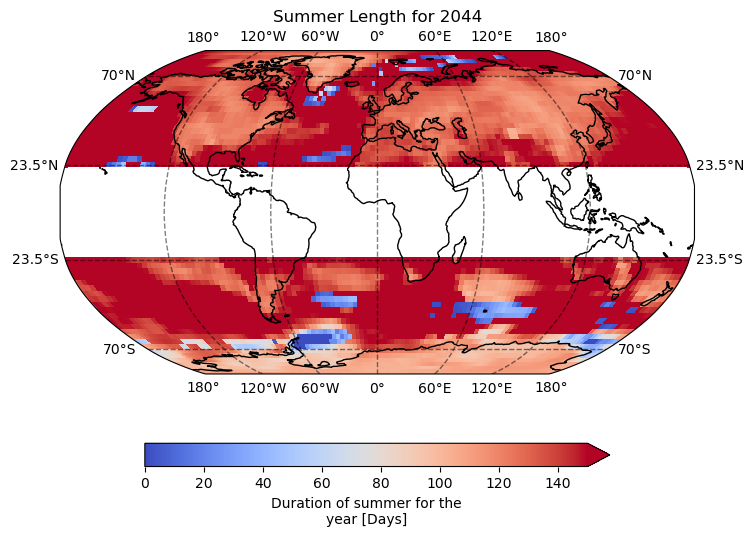

Time for 2044 :0.3101126833333333 min


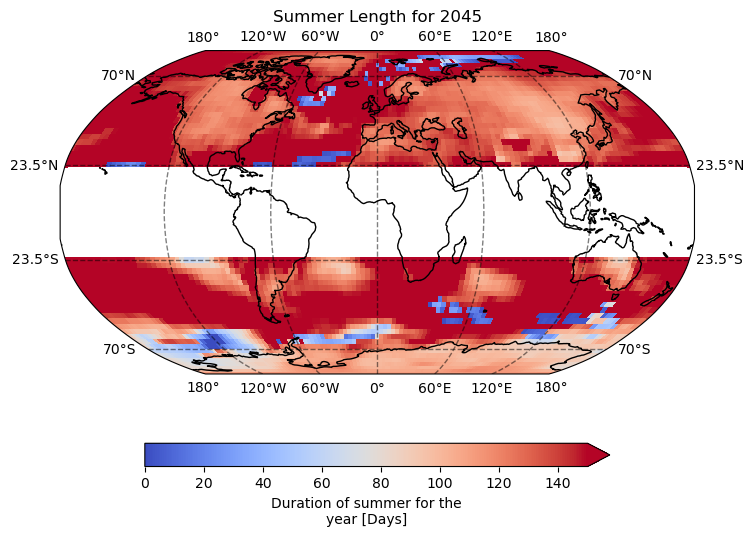

Time for 2045 :0.31176183333333335 min


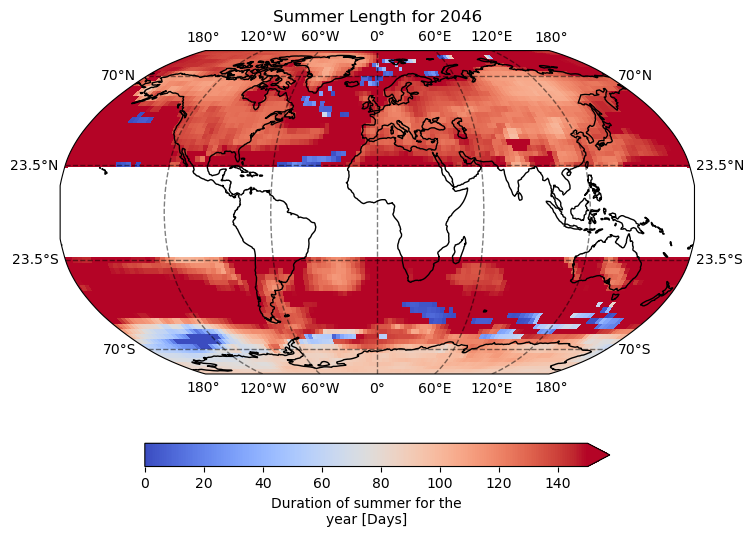

Time for 2046 :0.3087312333333333 min


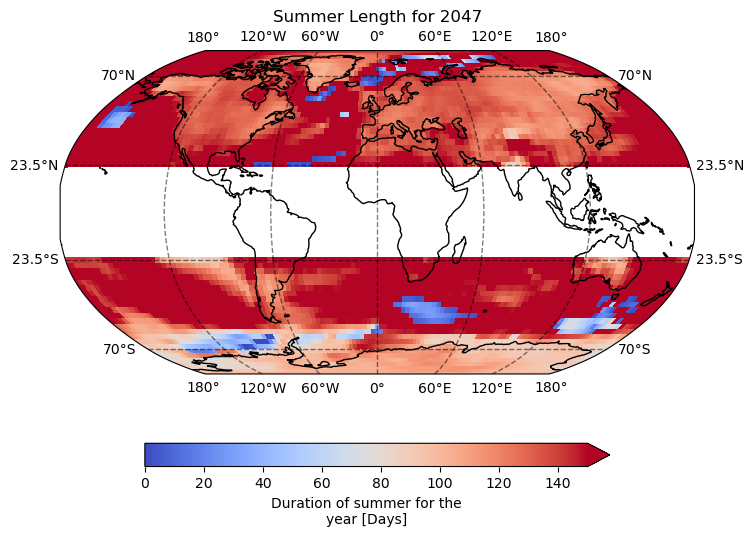

Time for 2047 :0.3111652333333333 min


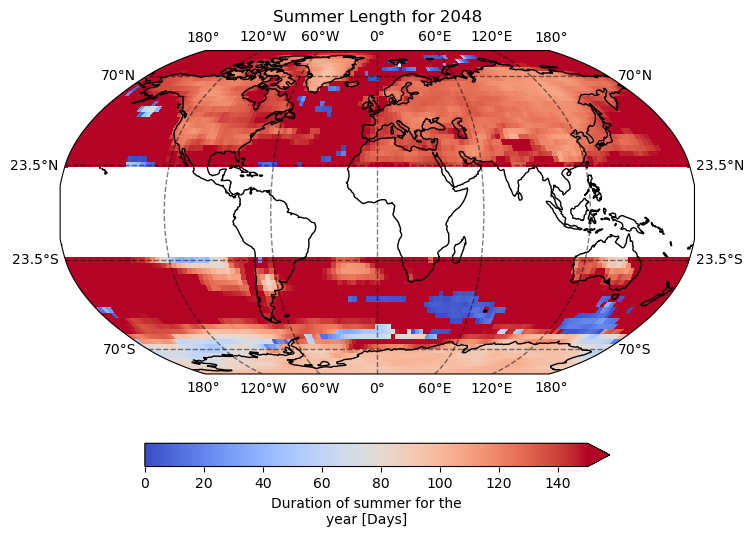

Time for 2048 :0.30783541666666664 min


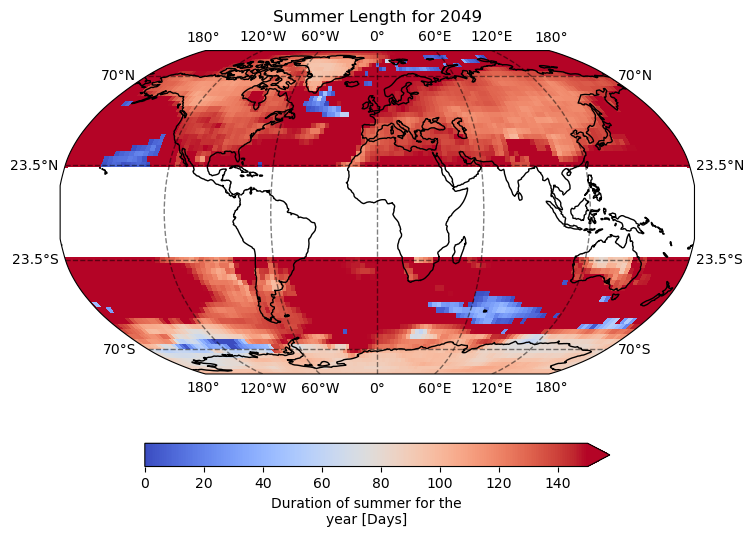

Time for 2049 :0.30700561666666665 min


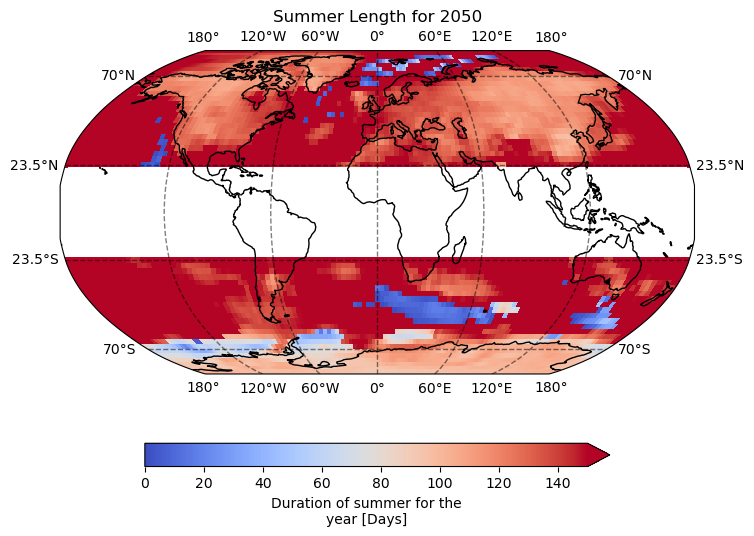

Time for 2050 :0.32473868333333333 min


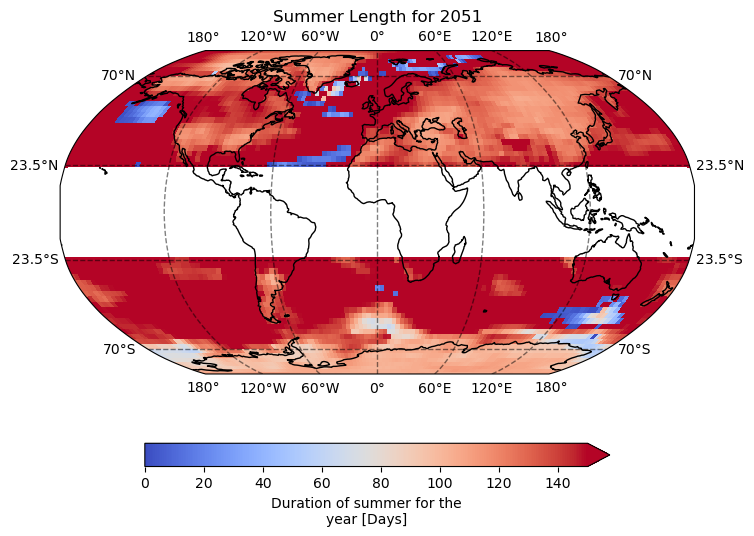

Time for 2051 :0.30948081666666666 min


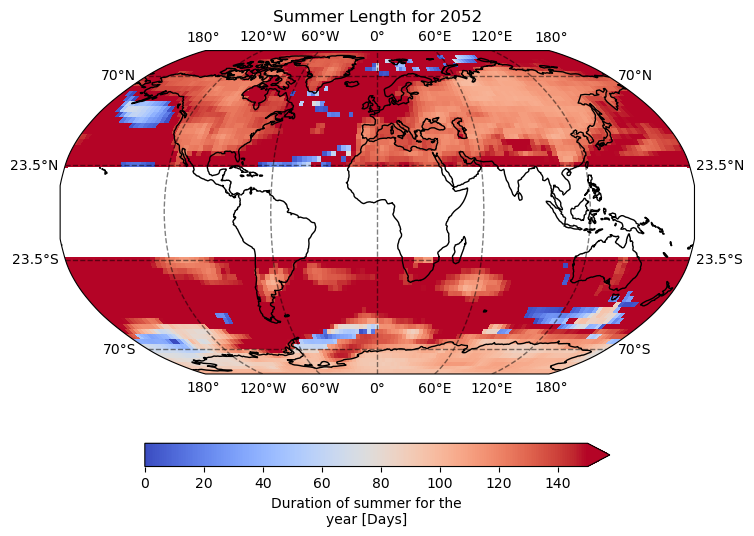

Time for 2052 :0.3071297333333333 min


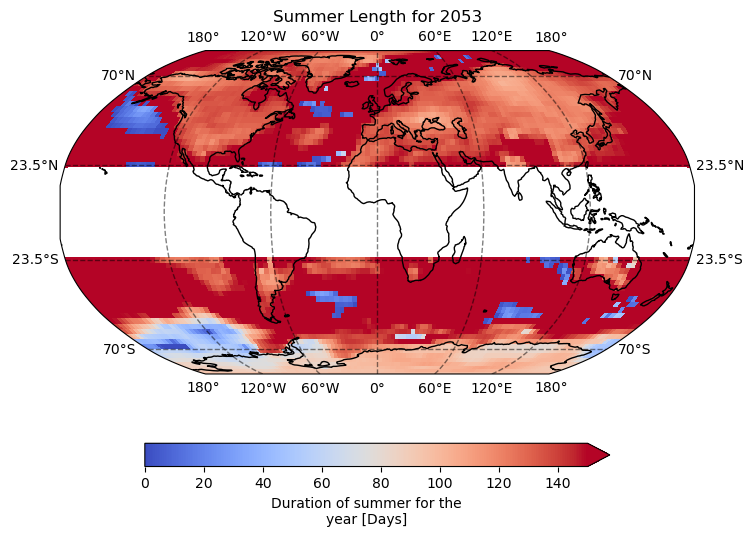

Time for 2053 :0.32072728333333334 min


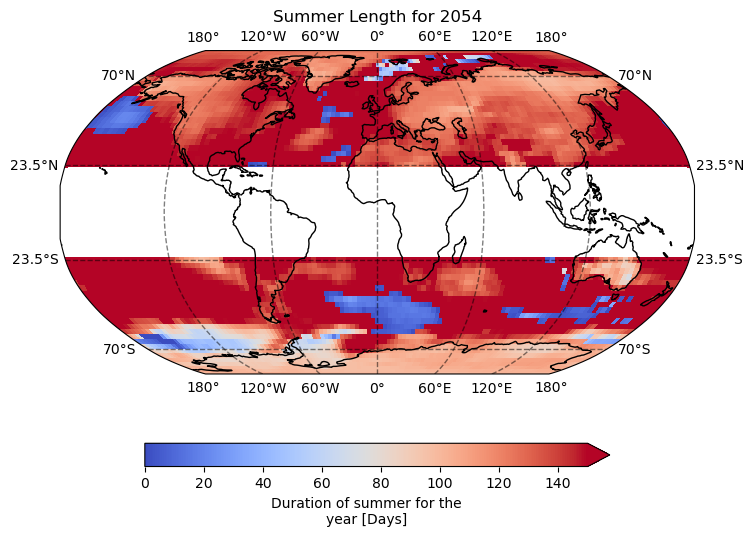

Time for 2054 :0.30768914999999997 min


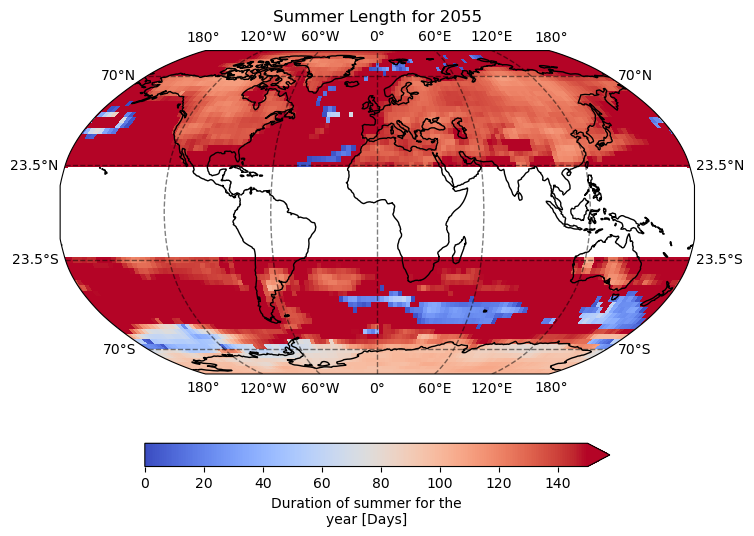

Time for 2055 :0.30653525 min


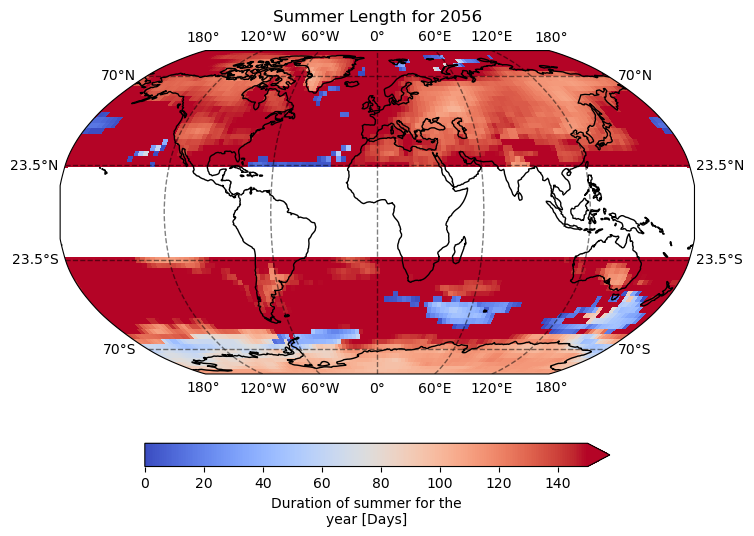

Time for 2056 :0.3068844 min


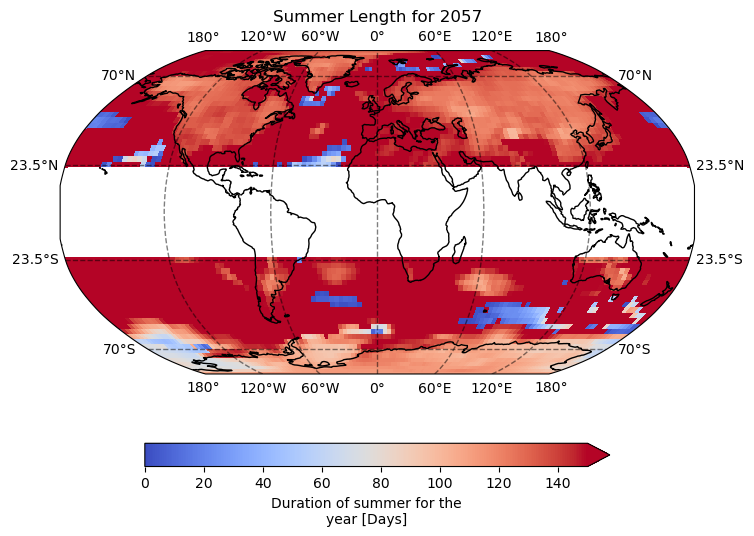

Time for 2057 :0.30693715000000005 min


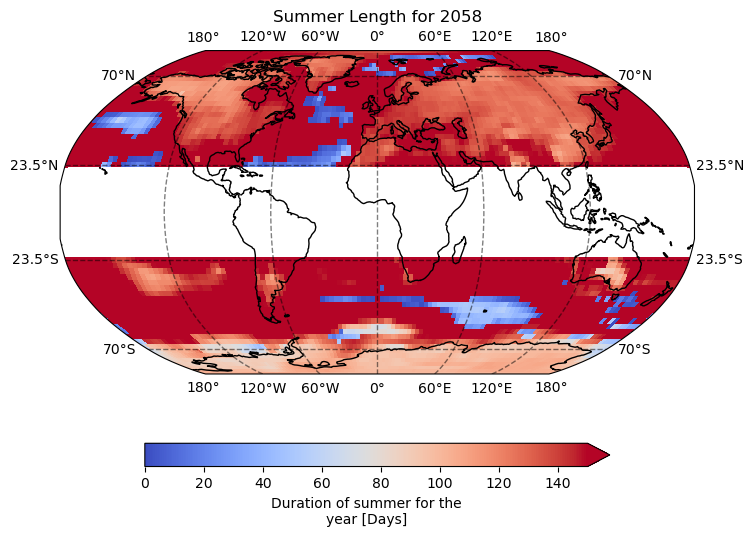

Time for 2058 :0.3109515 min


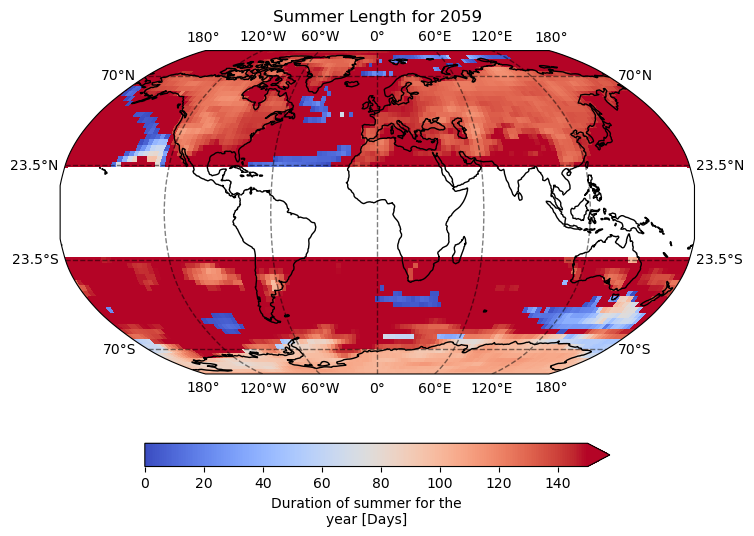

Time for 2059 :0.3056922666666667 min


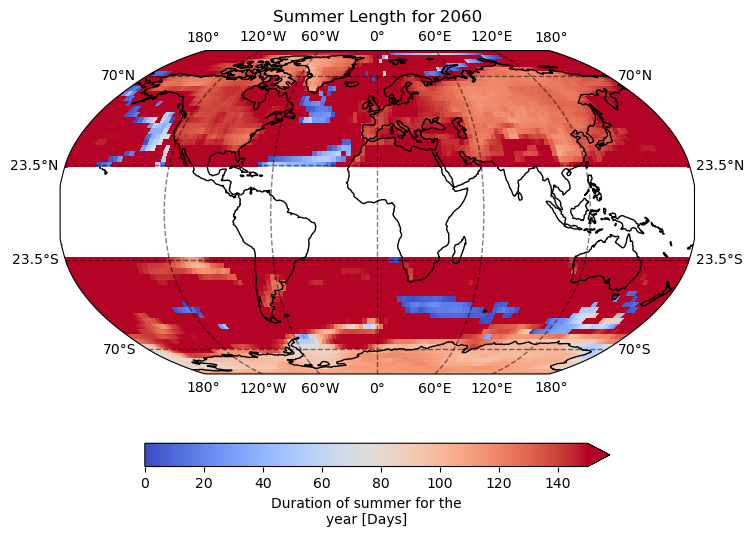

Time for 2060 :0.30553965 min


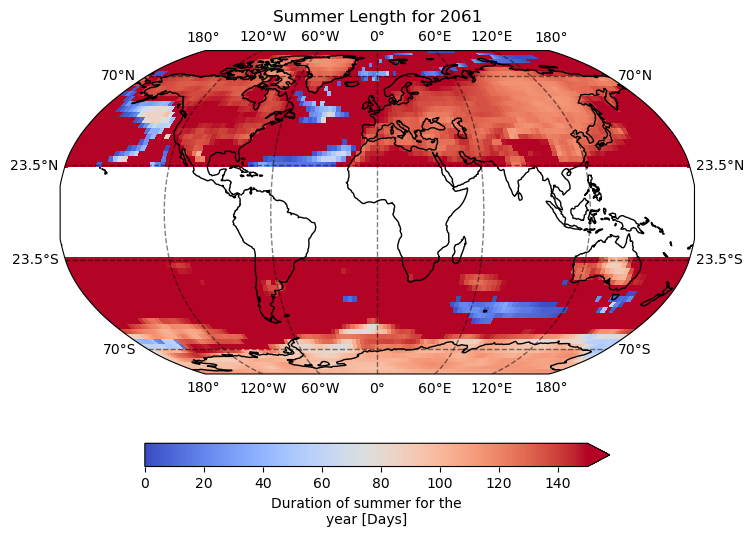

Time for 2061 :0.3073321666666667 min


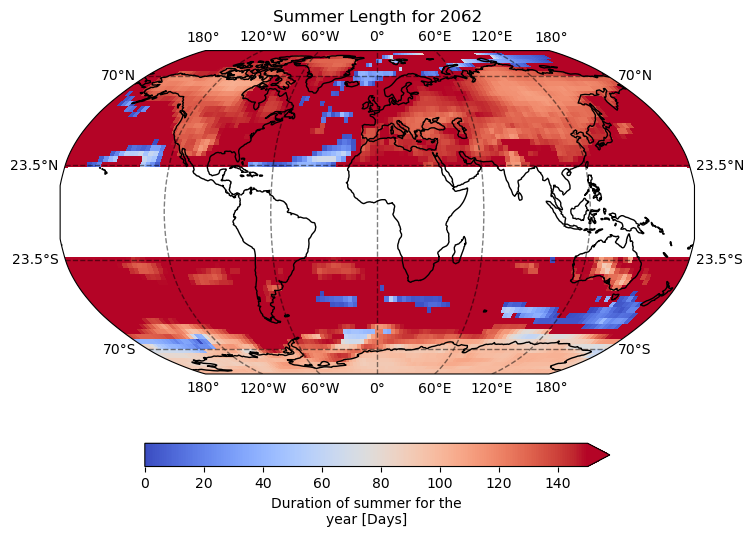

Time for 2062 :0.3072492 min


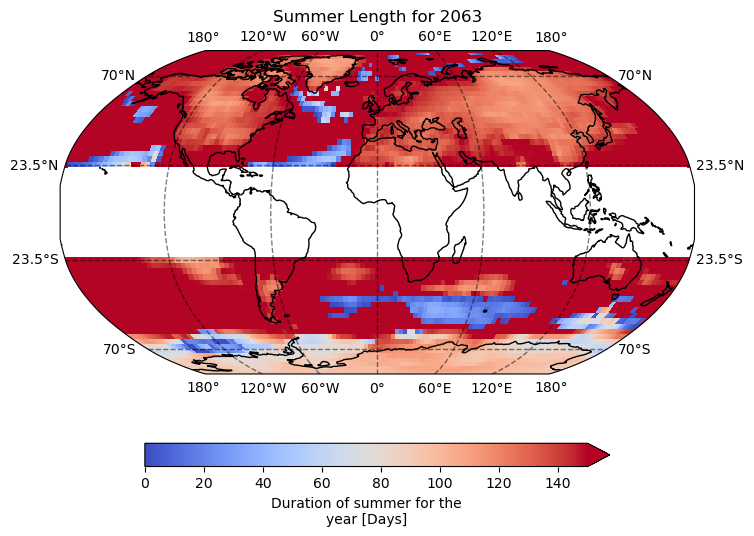

Time for 2063 :0.3055569666666667 min


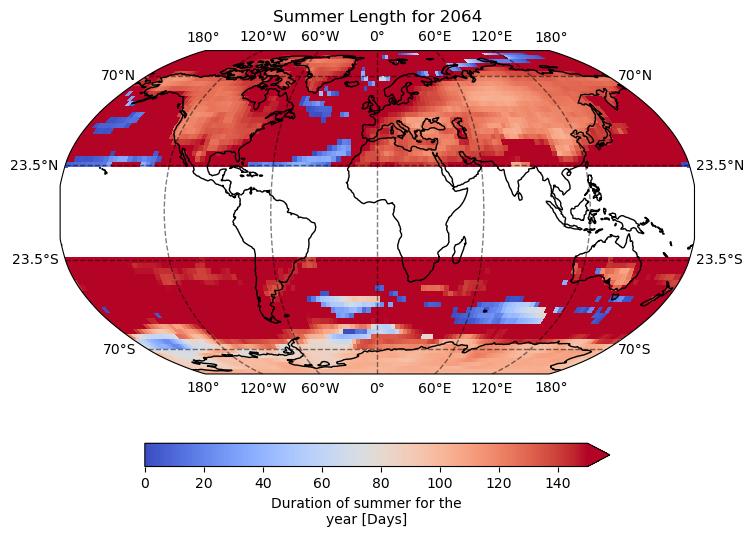

Time for 2064 :0.30970511666666667 min


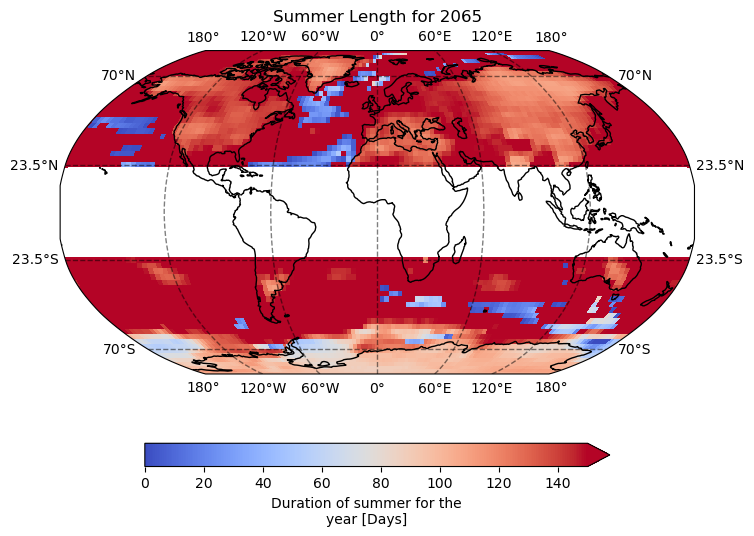

Time for 2065 :0.30795896666666667 min


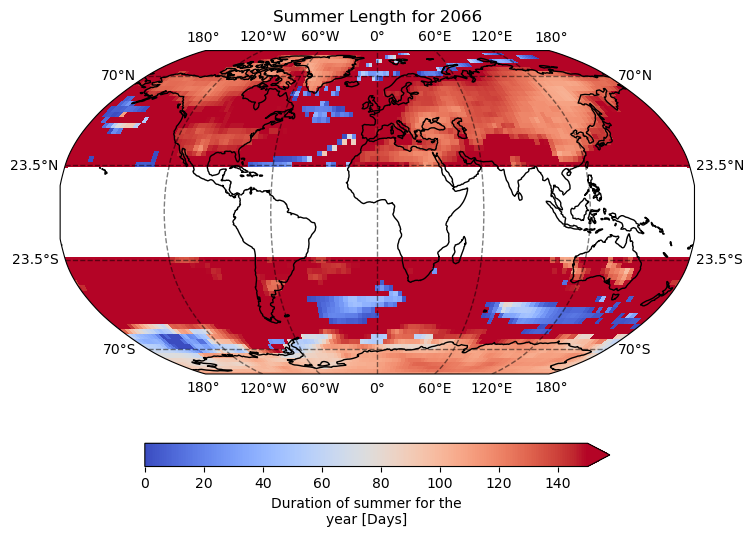

Time for 2066 :0.3122961166666667 min


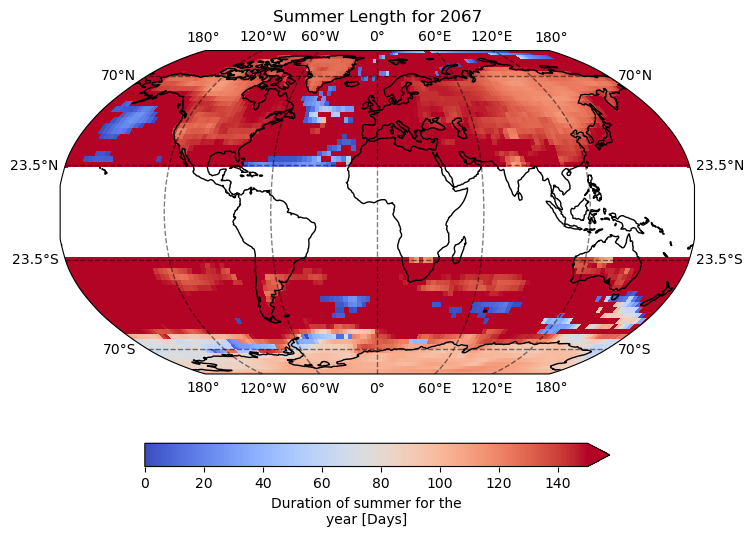

Time for 2067 :0.3106542 min


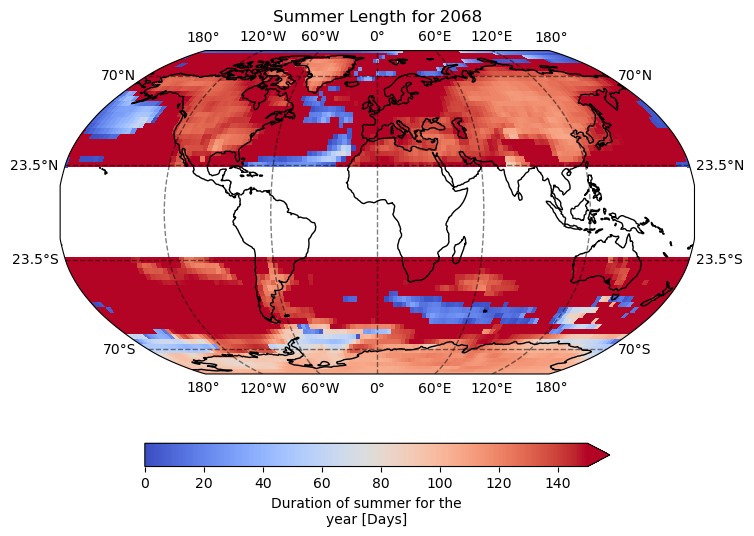

Time for 2068 :0.31649088333333336 min


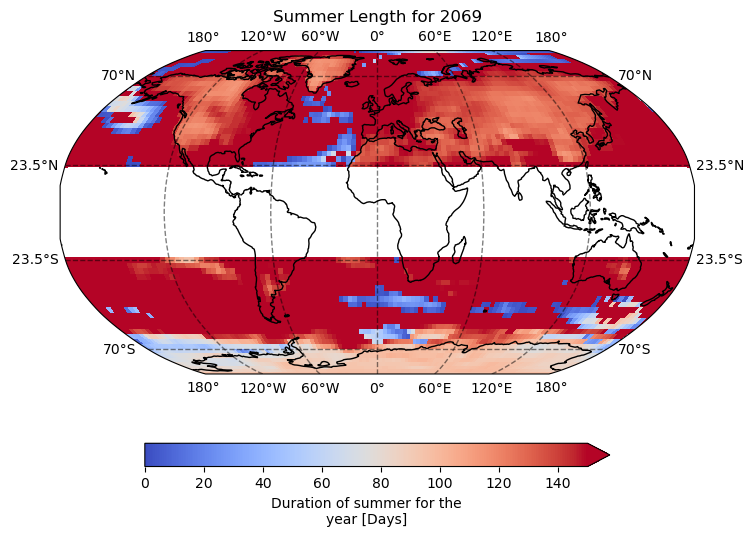

Time for 2069 :0.31159268333333334 min


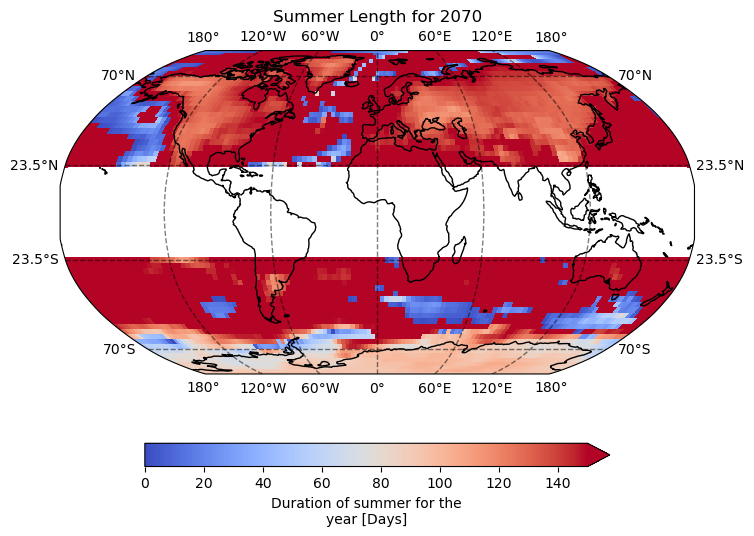

Time for 2070 :0.31284201666666667 min


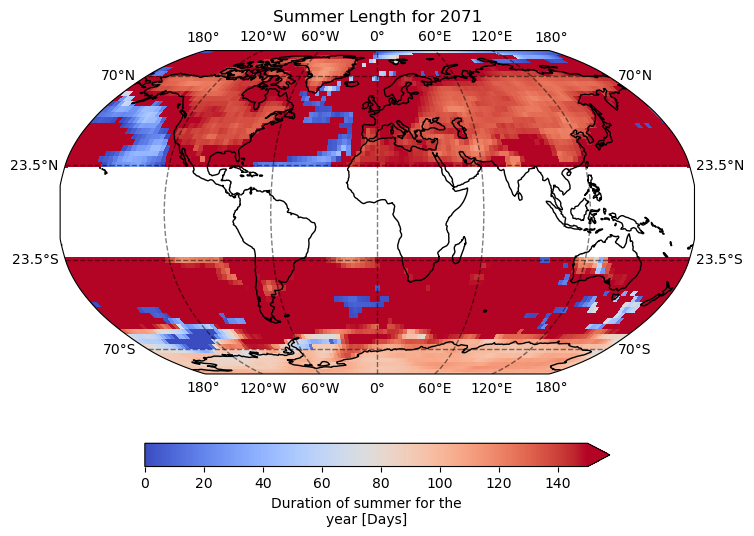

Time for 2071 :0.3352471833333333 min


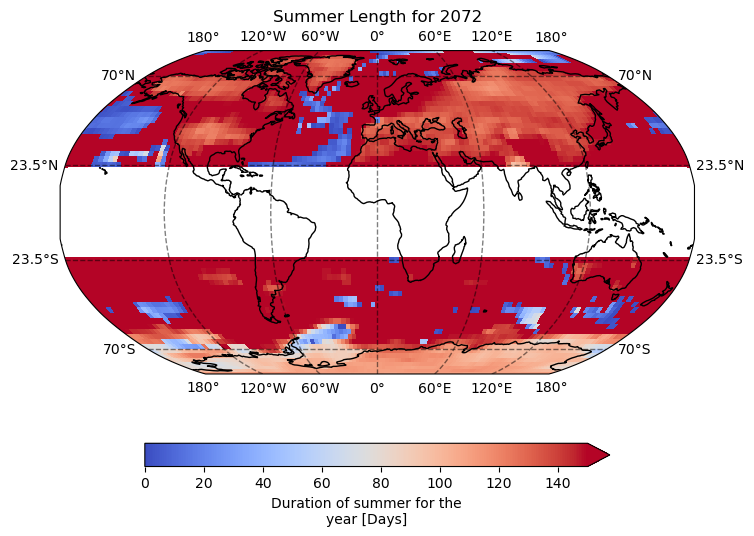

Time for 2072 :0.3210376166666667 min


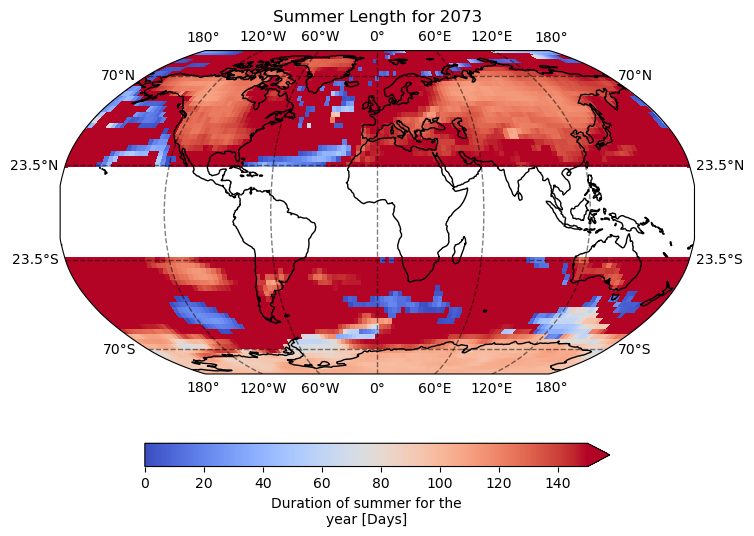

Time for 2073 :0.3136469666666667 min


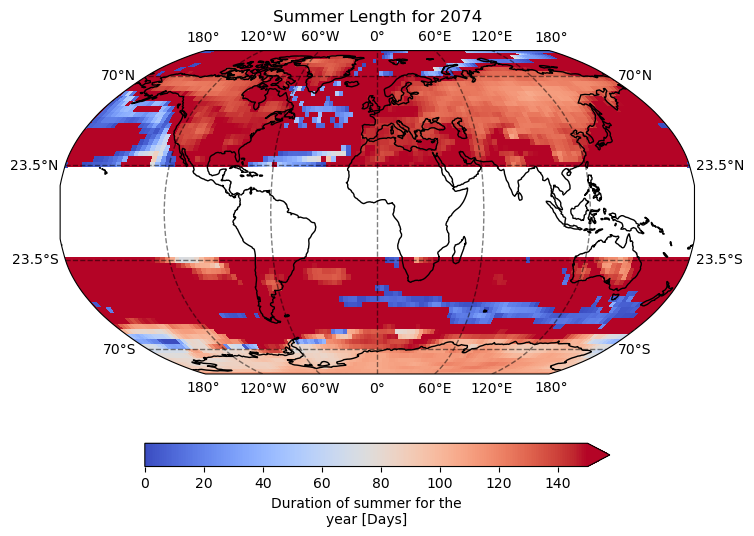

Time for 2074 :0.3107616833333333 min


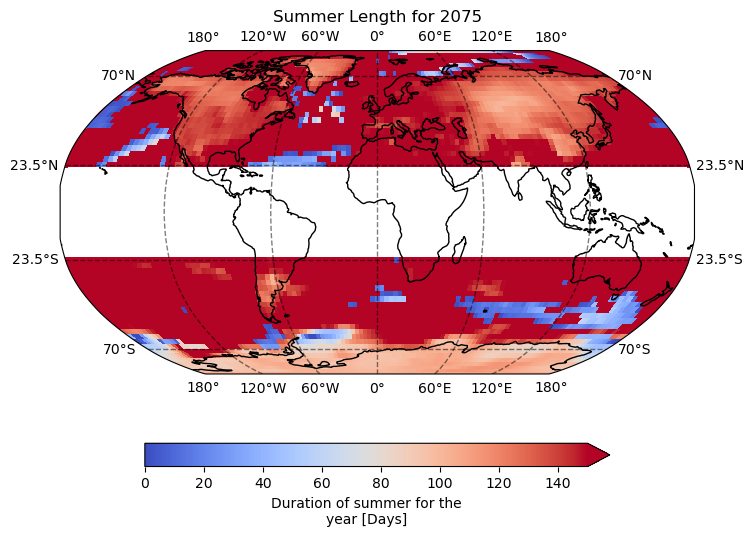

Time for 2075 :0.3123366166666666 min


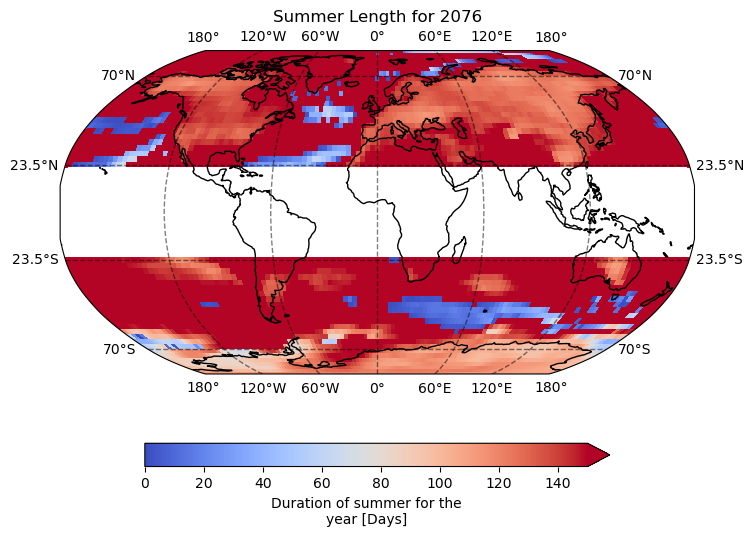

Time for 2076 :0.3076557166666667 min


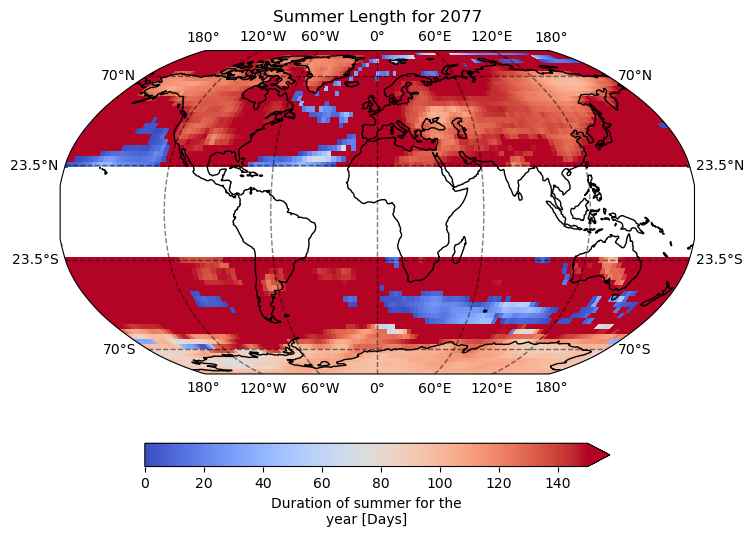

Time for 2077 :0.31053675 min


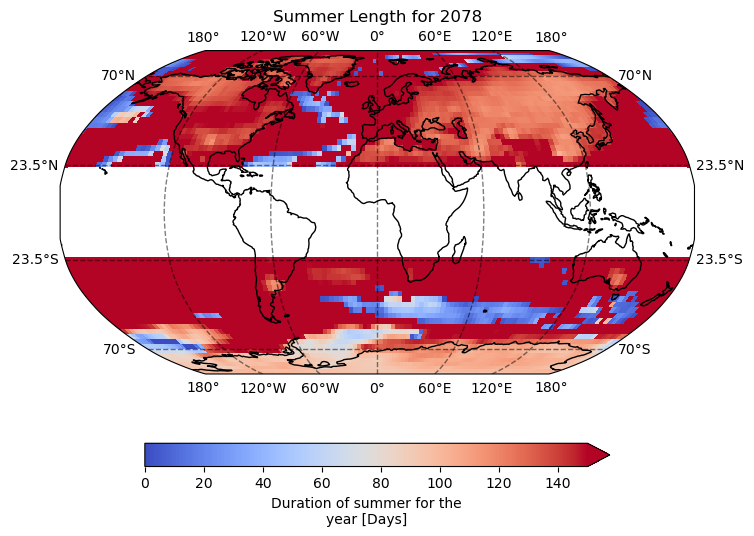

Time for 2078 :0.30952865 min


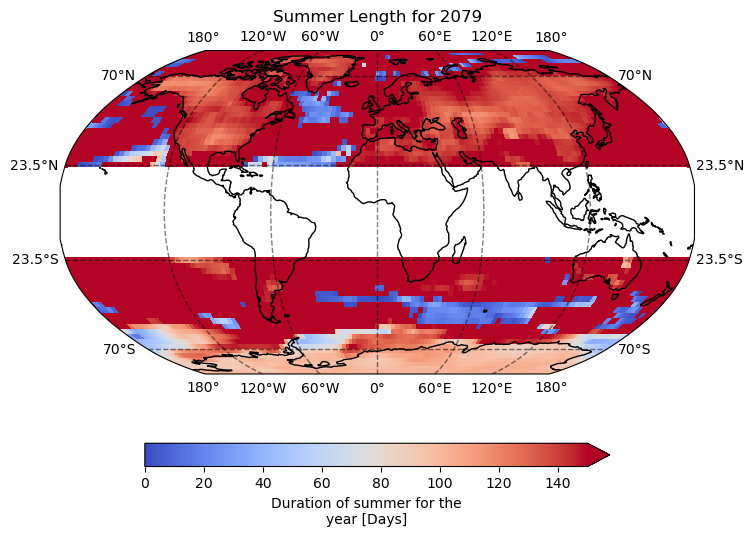

Time for 2079 :0.30751910000000005 min


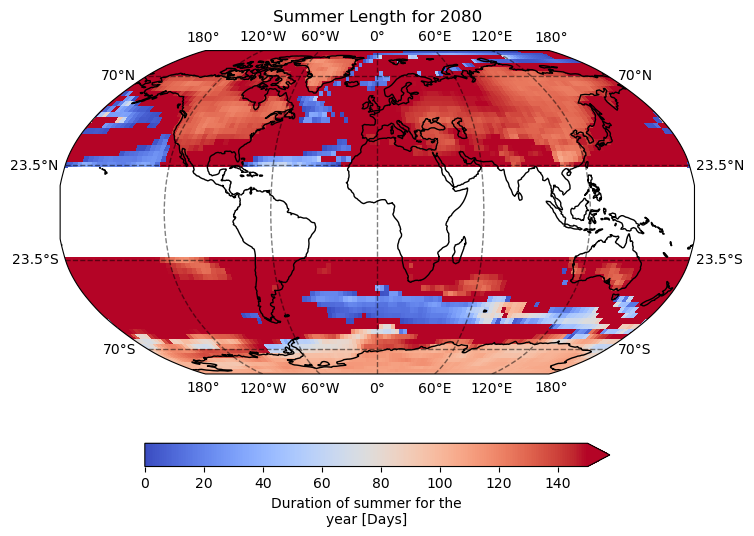

Time for 2080 :0.3198089833333333 min


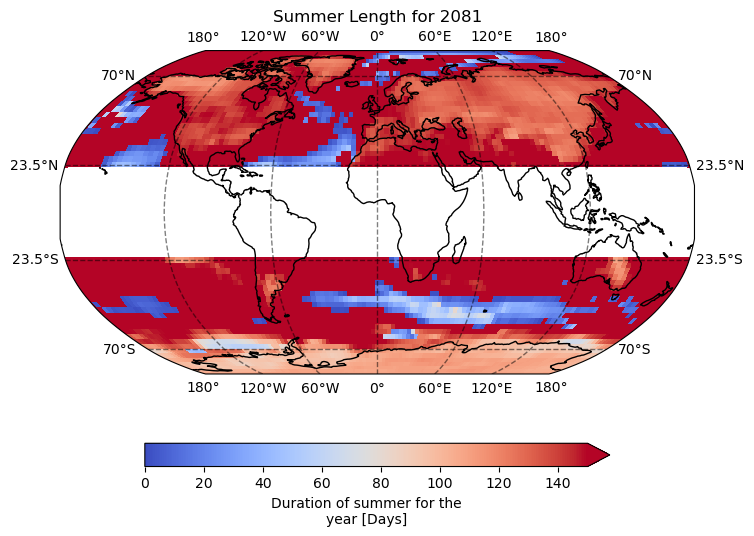

Time for 2081 :0.3238822833333333 min


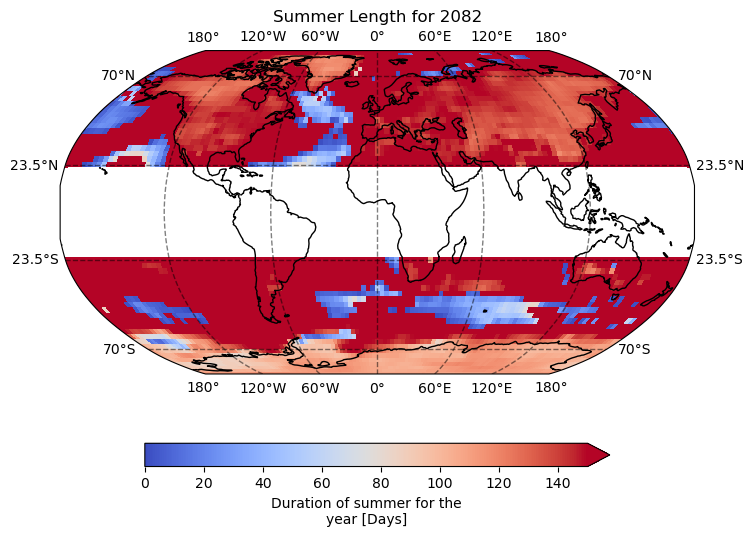

Time for 2082 :0.31749121666666663 min


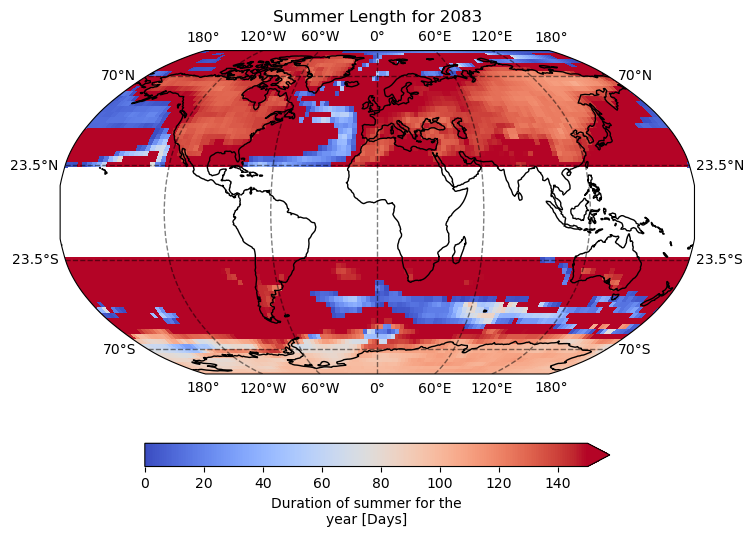

Time for 2083 :0.3173701333333333 min


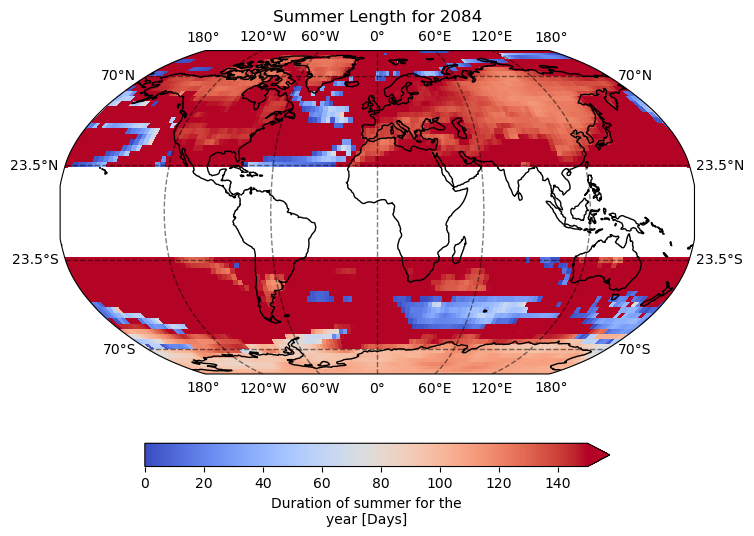

Time for 2084 :0.3128228666666667 min


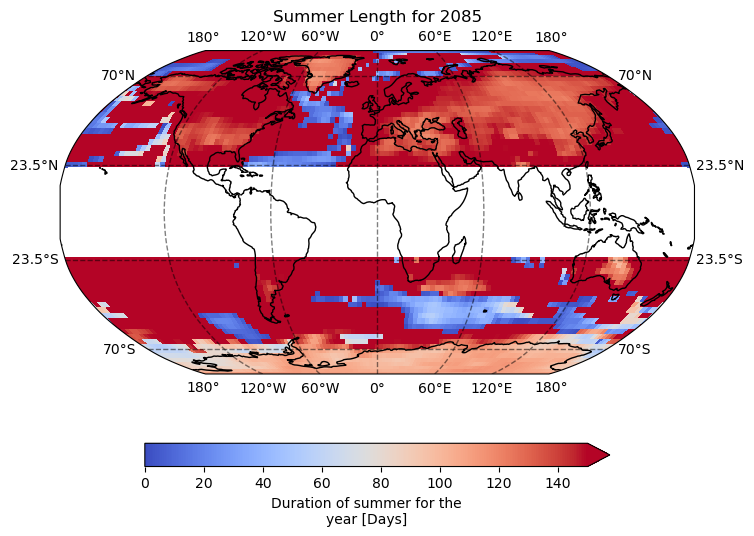

Time for 2085 :0.30951895 min


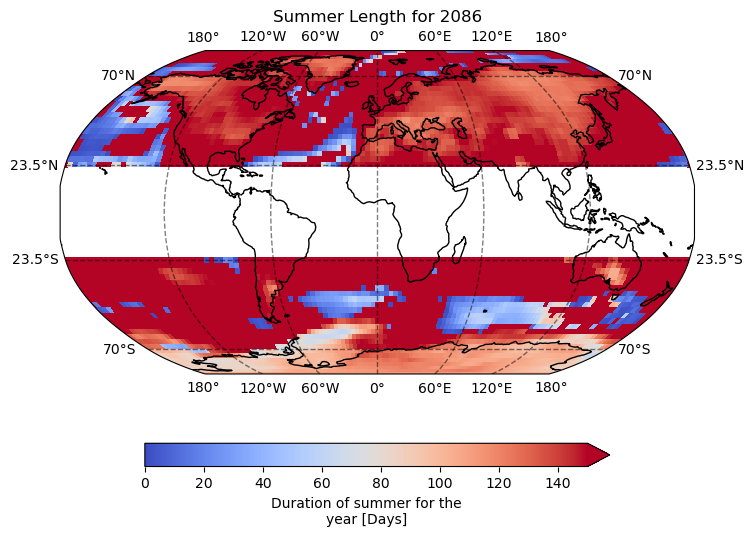

Time for 2086 :0.3078841666666667 min


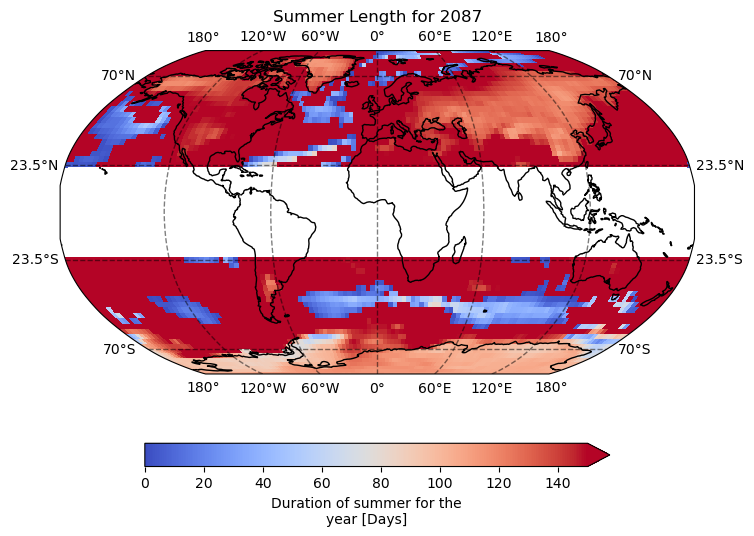

Time for 2087 :0.31326856666666664 min


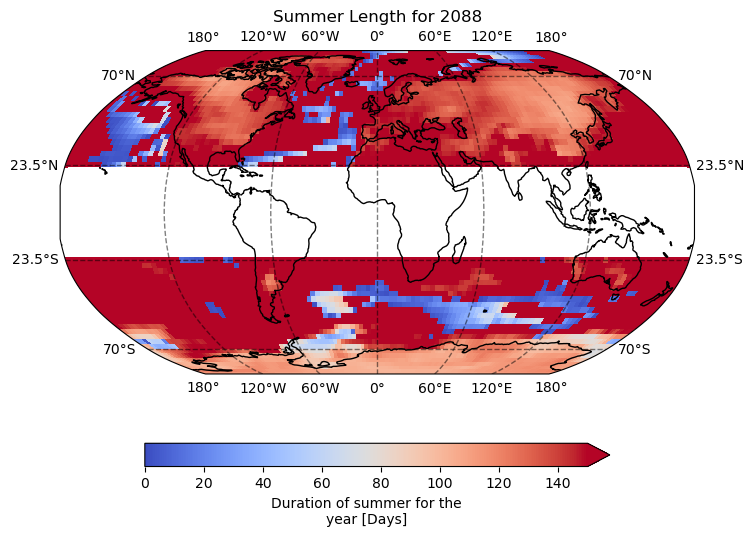

Time for 2088 :0.30796498333333333 min


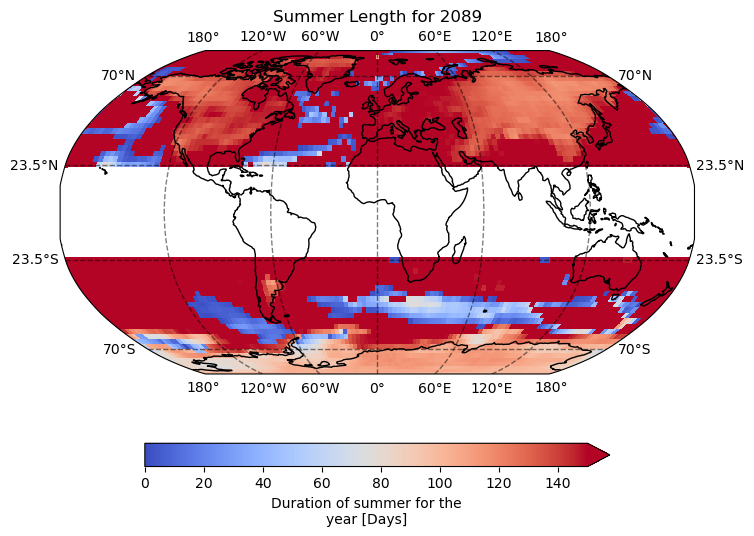

Time for 2089 :0.30677201666666665 min


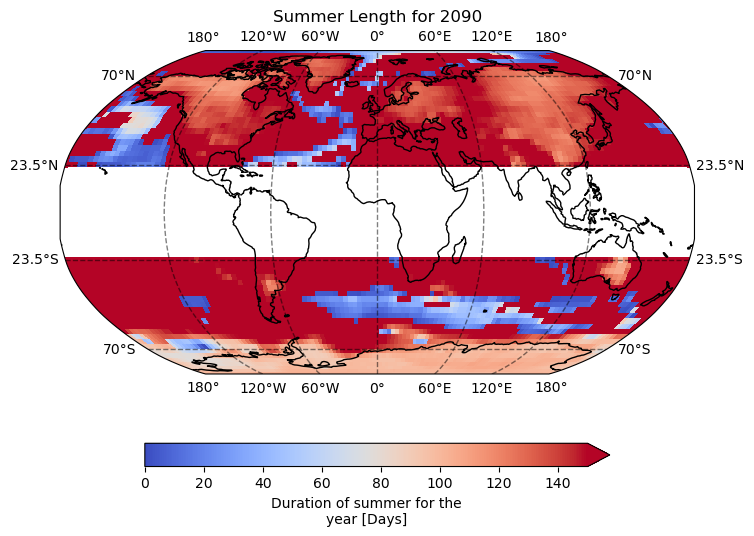

Time for 2090 :0.3119972166666667 min


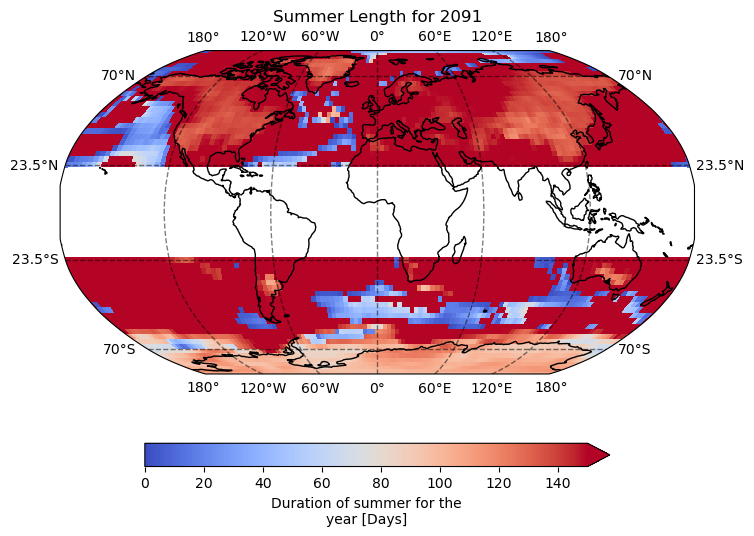

Time for 2091 :0.3088792833333333 min


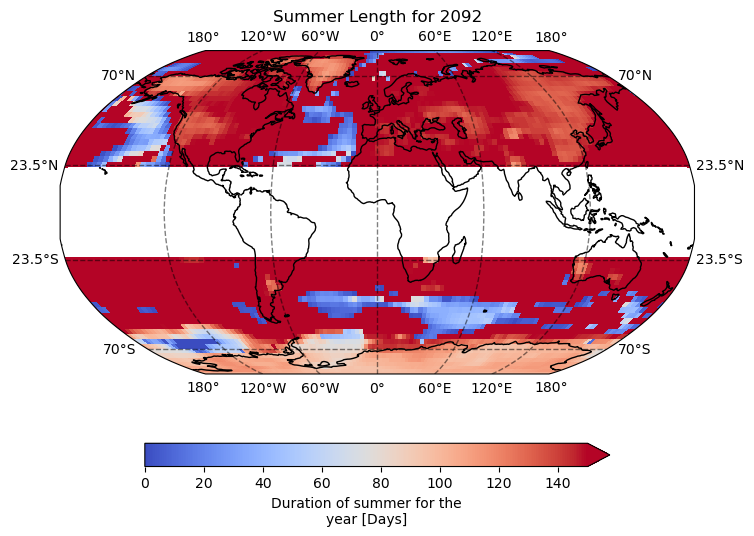

Time for 2092 :0.31080621666666663 min


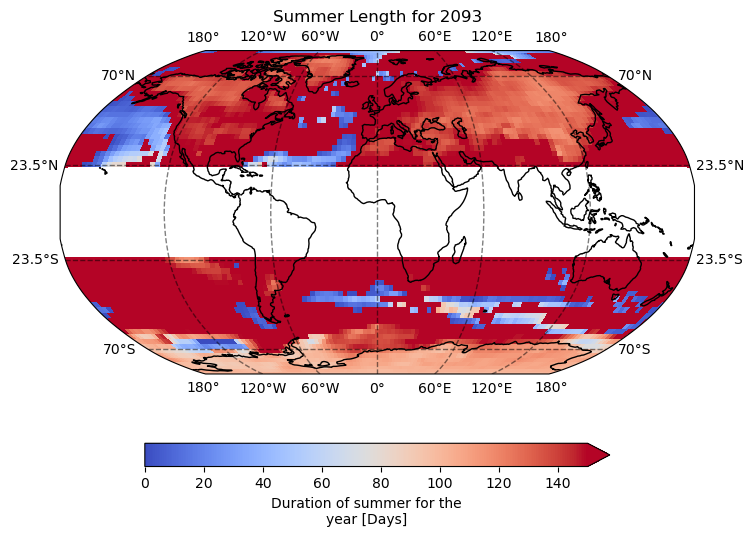

Time for 2093 :0.31471135 min


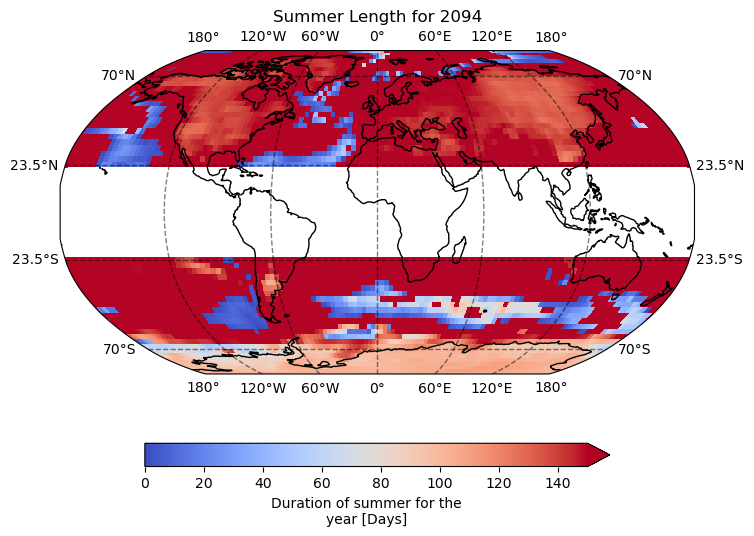

Time for 2094 :0.31105695 min


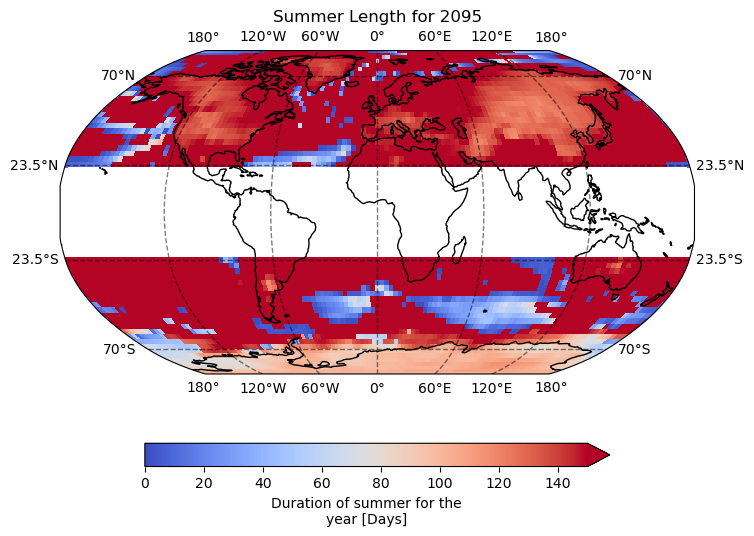

Time for 2095 :0.3089729333333333 min


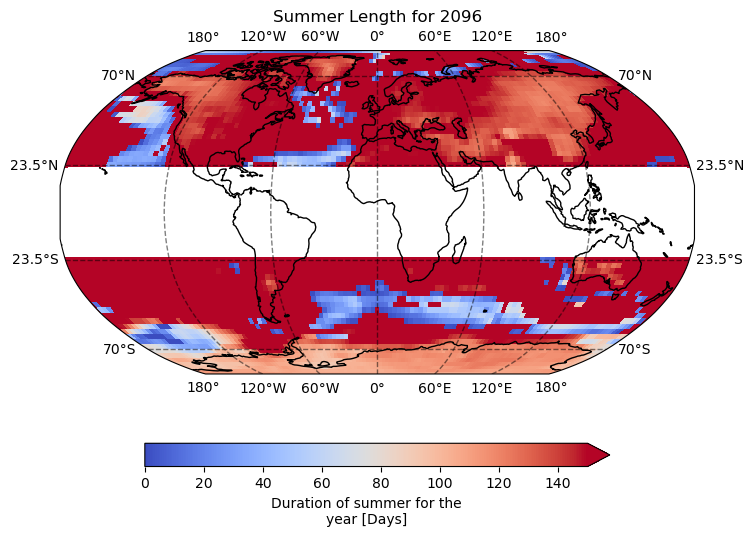

Time for 2096 :0.31314946666666665 min


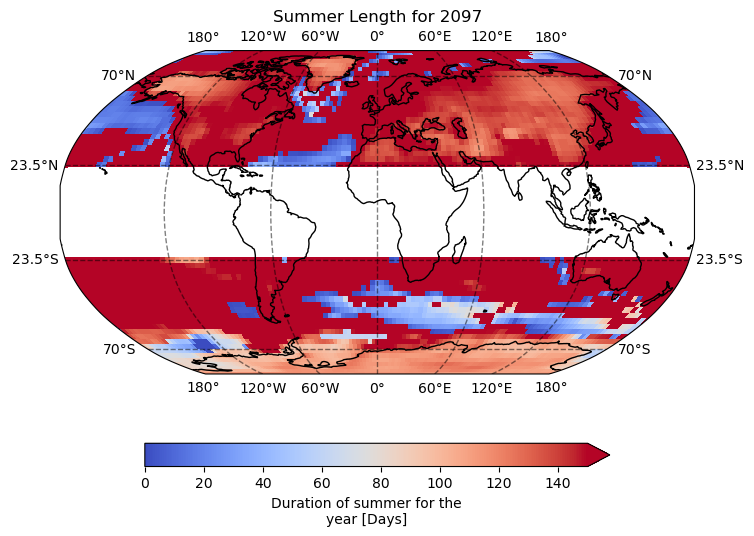

Time for 2097 :0.30931855 min


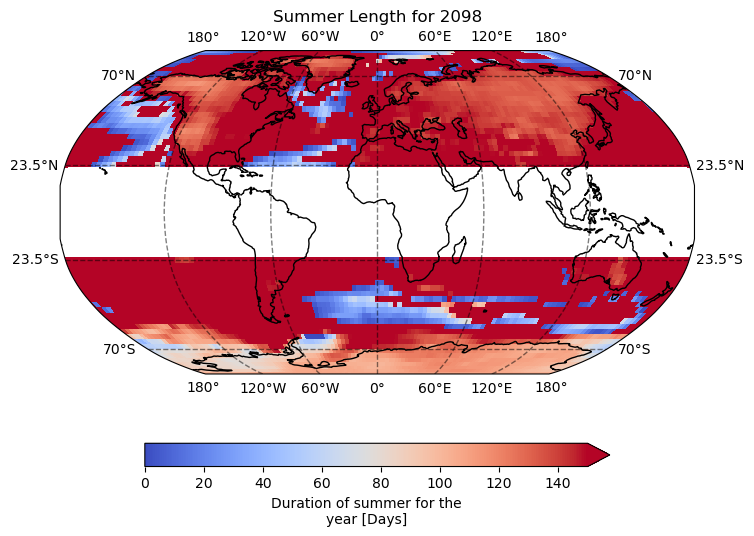

Time for 2098 :0.30644485 min


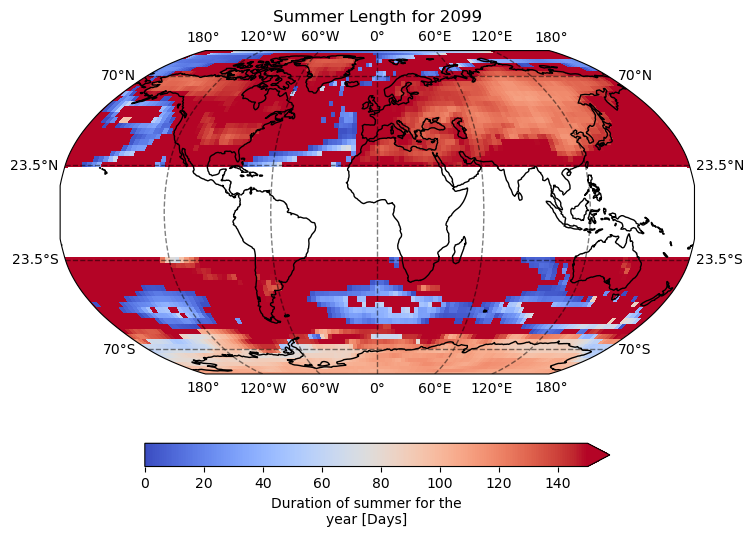

Time for 2099 :0.3083148666666667 min
CPU times: user 33min 35s, sys: 32.4 s, total: 34min 7s
Wall time: 34min 20s


In [38]:
%%time

# Runtime: 0.33 min for 1 year

# loop thru the years in the defined array above
for input_year in process_yrs:

    start = dt.now()

    ds = ds_canesm5.sel(time = str(input_year))

    dsnext = ds_canesm5.sel(time = str(input_year+1))

    # load into memory to speed up the summer stats processing
    ds.load()
    dsnext.load()

    # empty data arrays for summer stats
    summerlength = xr.DataArray(np.zeros((num_lat,num_lon)), 
                                coords=[loop_lats, loop_lons], 
                                dims=['lat','lon'])
    summerstart = xr.DataArray(np.zeros((num_lat,num_lon)), 
                               coords=[loop_lats, loop_lons], 
                               dims=['lat','lon'])
    summerend = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summermax = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summerheat = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summerrmse = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summerr2 = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summermean = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    summermeanhs = xr.DataArray(np.zeros((num_lat,num_lon)), 
                             coords=[loop_lats, loop_lons], 
                             dims=['lat','lon'])
    
    # add attributes
    summerstart.attrs["long_name"] = "Start day of summer for the year (DOY in [1,365])"
    summerstart.attrs["units"] = "Day of year"
    
    summerend.attrs["long_name"] = "Last day of summer for the year (DOY in [1,365])"
    summerend.attrs["units"] = "Day of year"
    
    summerlength.attrs["long_name"] = "Duration of summer for the year"
    summerlength.attrs["units"] = "Days"
    
    summermax.attrs["long_name"] = "Day of max mean temp during summer for the year"
    summermax.attrs["units"] = "Day of year"
    
    summerheat.attrs["long_name"] = "Accumulated heat during summer for the year"
    summerheat.attrs["units"] = "Degree-Days"
    
    summerrmse.attrs["long_name"] = "Root mean squared error of Fourier fit"
    summerrmse.attrs["units"] = "Degrees [K]"
    
    summerr2.attrs["long_name"] = "Coefficient of determination (R-squared) of Fourier fit [NOT USED]"
    summerr2.attrs["units"] = "Variance explained"

    summermean.attrs["long_name"] = "Mean temperature during the summer period"
    summermean.attrs["units"] = "Degrees [K]"

    summermeanhs.attrs["long_name"] = "Mean HS temperature during the summer period"
    summermeanhs.attrs["units"] = "Degrees [K]"

    ## now that I've added RMSE and R^2 - these loops take ~27 min with heat and tmax

    # loop through all of the lat,lon of interest
    for input_lat in loop_lats:
        for input_lon in loop_lons:
            # get threshold from c_75 - using closest location since not same grid as GFDL-ESM4
            thresh = c_75_canesm.sel(lat=input_lat,lon=input_lon, method='nearest')
    
            # all the temps for that grid cell over time for this year and next (for SH)
            curr = ds.tas.sel(lat=input_lat,lon=input_lon) 
            nxt = dsnext.tas.sel(lat=input_lat, lon=input_lon)
    
            # build summer stats for the grid cell and produce the plot if desired (currently False)
            start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True)
            
            # xarray requires strange indexing in order to replace values by coordinate
            summerstart.loc[input_lat, input_lon] = start_day
            summerend.loc[input_lat, input_lon] = last_day
            summermax.loc[input_lat, input_lon] = day_of_max
            summerheat.loc[input_lat, input_lon] = acc_heat
            summerlength.loc[input_lat, input_lon] = summer_length
            summerrmse.loc[input_lat, input_lon] = rmse
            summerr2.loc[input_lat, input_lon] = r2
            summermean.loc[input_lat, input_lon] = mean_temp
            summermeanhs.loc[input_lat, input_lon] = mean_hs
            

    # save it out
    sum_ds = xr.Dataset(data_vars={'SummerStart':summerstart,
                               'SummerEnd':summerend,
                               'SummerTmax':summermax,
                               'SummerHeat':summerheat,
                               'SummerLength':summerlength,
                               'SummerRMSE':summerrmse,
                               'SummerR2':summerr2,
                                'SummerMeanT':summermean,
                                   'SummerMeanHS':summermeanhs})
    output_path = '../../../Data/CMIP6/CanESM5/Summers/'+str(input_year)+'_CanESM5_r1i1p1f1_summer_stats.nc'
    sum_ds.to_netcdf(output_path)

    # plots for the year
    fig = plt.figure(figsize=(12,6))

    # assign axis and def projection to use
    ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))
    
    # add coastlines and grid
    ax.coastlines()
    ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([-70, -23.5, 23.5, 70]), linestyle='--')
    
    sum_ds.SummerLength.where((sum_ds.lat >= 23.5) | (sum_ds.lat <= -23.5)).plot(
        ax=ax,
        transform=ccrs.PlateCarree(), # assign map projection
        vmin=0,
        vmax=150, 
        cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
        cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
    )
    
    plt.title("Summer Length for "+str(input_year))#+" using 1961-1990 baseline")
    #plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
    plt.show()

    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(input_year)+" :"+str(elapsed)+" min")